# Lab Notes: Machine Learning with Scikit-Learn
### Assignment 5 - Scikit-Learn for Machine Learning

These notes accompany Assignment 5. Every task in the assignment is implemented here, and each algorithm is explained from first principles before any code is written.

Each section follows the same structure:

1. **Concept** - what the technique does and why it exists, in plain language.
2. **How it works** - the mathematics, followed by a small worked numerical example.
3. **Implementation** - every task from the assignment, with code and printed output.
4. **Visualisation** - plots that show what the algorithm is actually doing.
5. **Interpretation** - what the numbers mean.
6. **Discussion** - answers to the assignment's written questions.

---

## Contents

| No. | Topic | Algorithm / Tool | Learning type |
|---|---|---|---|
| 0 | Foundations | Scikit-learn API, ML workflow | - |
| 1 | Data Preprocessing | StandardScaler, MinMaxScaler, LabelEncoder, OneHotEncoder | Preprocessing |
| 2 | Train-Test Split and Linear Regression | LinearRegression, MSE, R² | Supervised (regression) |
| 3 | Logistic Regression and Classification | LogisticRegression, confusion matrix, precision, recall | Supervised (classification) |
| 4 | K-Means Clustering | KMeans, Elbow Method, silhouette score | Unsupervised (clustering) |
| 5 | Principal Component Analysis | PCA, explained variance | Unsupervised (dimensionality reduction) |
| 6 | Decision Tree Classifier | DecisionTreeClassifier, Gini impurity | Supervised (classification) |
| 7 | Cross-Validation and Model Comparison | cross_val_score, StratifiedKFold | Model evaluation |
| 8 | Random Forest and Feature Importance | RandomForestClassifier, RandomForestRegressor | Supervised (ensemble) |
| 9 | Hyperparameter Tuning | GridSearchCV, Support Vector Classifier | Model selection |
| 10 | Complete ML Pipeline | Pipeline, ColumnTransformer, SimpleImputer | End-to-end workflow |
| 11 | Summary | Reference tables | - |

---
# 0. Foundations

## 0.1 What machine learning is

In traditional programming, a person writes the rules and the computer applies them to data. In machine learning, the computer is given data together with the correct answers, and it works out the rules by itself.

**Example.** To decide whether a loan should be approved, a traditional program would contain a hand-written rule such as `if credit_score > 650 and income > 45000: approve`. A machine learning model is instead shown thousands of past applications with their outcomes, and it learns a rule of that kind from the examples.

## 0.2 Vocabulary used throughout these notes

| Term | Meaning | Example |
|---|---|---|
| **Sample** (row, observation) | One record in the dataset | One employee |
| **Feature** (input, independent variable, `X`) | A measured property used to make a prediction | Age, Salary |
| **Target** (label, output, dependent variable, `y`) | The value the model should predict | Loan approved (yes/no) |
| **Model** | The mathematical function that maps features to the target | A straight line, a decision tree |
| **Training** (fitting) | Letting the model learn its internal numbers from data | Finding the slope of the line |
| **Prediction** | Using a trained model on new data | Predicting approval for a new applicant |

## 0.3 Types of machine learning covered in this lab

| Type | Is the correct answer given? | Goal | Algorithms in this lab |
|---|---|---|---|
| **Supervised - Regression** | Yes | Predict a continuous number | Linear Regression, Random Forest Regressor |
| **Supervised - Classification** | Yes | Predict a category | Logistic Regression, Decision Tree, Random Forest, SVC |
| **Unsupervised - Clustering** | No | Find natural groups | K-Means |
| **Unsupervised - Dimensionality reduction** | No | Compress many features into fewer | PCA |

## 0.4 The scikit-learn API

Every object in scikit-learn follows the same small set of methods. Once these are understood, every algorithm in this lab is used in the same way.

| Method | Available on | What it does |
|---|---|---|
| `fit(X, y)` | All estimators | Learns from the data. For a scaler, it learns the mean and standard deviation. For a model, it learns the coefficients or tree splits. |
| `transform(X)` | Transformers (scalers, encoders, PCA) | Applies what was learned to change the data. |
| `fit_transform(X)` | Transformers | `fit` followed by `transform` in one call. Used on training data only. |
| `predict(X)` | Models | Returns predictions for new data. |
| `predict_proba(X)` | Most classifiers | Returns the probability of each class. |
| `score(X, y)` | Models | Returns a default metric (accuracy for classifiers, R² for regressors). |

Attributes learned during `fit` end with an underscore, for example `coef_`, `mean_`, `feature_importances_`. The underscore signals that the value exists only after training.

## 0.5 The standard machine learning workflow

```
Raw data -> Clean and preprocess -> Split into train/test -> Train model on train set
         -> Evaluate on test set -> Tune hyperparameters -> Final model -> Predict new data
```

## 0.6 Environment setup
The cell below imports the shared libraries, sets a consistent plotting style, and defines one helper function for drawing confusion matrices, which is reused in several sections.

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

plt.rcParams.update({
    'figure.figsize': (8, 5),
    'figure.dpi': 100,
    'axes.grid': True,
    'grid.alpha': 0.3,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.titleweight': 'bold',
})
pd.set_option('display.width', 140)
pd.set_option('display.max_columns', 30)

print('NumPy        :', np.__version__)
print('pandas       :', pd.__version__)
print('scikit-learn :', sklearn.__version__)


def plot_confusion_matrix(cm, class_names, title='Confusion Matrix', ax=None):
    # Draws a confusion matrix as a colour-coded grid with the count in each cell.
    if ax is None:
        fig, ax = plt.subplots(figsize=(5, 4))
    im = ax.imshow(cm, cmap='Blues')
    ax.set_xticks(range(len(class_names)))
    ax.set_xticklabels(class_names)
    ax.set_yticks(range(len(class_names)))
    ax.set_yticklabels(class_names)
    ax.set_xlabel('Predicted label')
    ax.set_ylabel('Actual label')
    ax.set_title(title)
    ax.grid(False)
    threshold = cm.max() / 2
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, cm[i, j], ha='center', va='center', fontsize=15, fontweight='bold',
                    color='white' if cm[i, j] > threshold else 'black')
    plt.colorbar(im, ax=ax, fraction=0.046)
    return ax

NumPy        : 2.1.3
pandas       : 2.2.3
scikit-learn : 1.6.1


---
# 1. Data Preprocessing: Scaling and Encoding

## 1.1 Concept

Machine learning models perform arithmetic on their inputs. Raw data usually has two properties that break this arithmetic:

1. **Features on very different scales.** Age is measured in tens, while Salary is measured in tens of thousands. Any algorithm that adds, subtracts or measures distances will be dominated by Salary simply because its numbers are larger, not because it is more important.
2. **Features stored as text.** A model cannot multiply `'IT'` by a coefficient. Categories must be converted to numbers without introducing false meaning.

Preprocessing solves both problems. **Scaling** puts numeric features on a comparable range, and **encoding** converts categories into numbers.

### Worked example of the scale problem

Consider two employees from the dataset below:

| Employee | Age | Salary |
|---|---|---|
| A | 25 | 50,000 |
| G | 45 | 100,000 |

The Euclidean distance between them is

$$d = \sqrt{(45-25)^2 + (100000-50000)^2} = \sqrt{400 + 2{,}500{,}000{,}000} \approx 50{,}000.004$$

A 20-year age difference contributes only 400 to a sum of 2.5 billion. To a distance-based algorithm, Age effectively does not exist. Scaling fixes this.

## 1.2 The dataset

In [2]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder, OneHotEncoder

np.random.seed(42)
df = pd.DataFrame({
    'Age': [25, 30, 35, 40, 28, 32, 45, 50],
    'Salary': [50000, 60000, 75000, 90000, 55000, 65000, 100000, 120000],
    'Department': ['IT', 'HR', 'IT', 'Sales', 'HR', 'Sales', 'IT', 'Sales'],
    'Gender': ['Male', 'Female', 'Female', 'Male', 'Male', 'Female', 'Male', 'Female'],
    'Performance': ['Good', 'Average', 'Excellent', 'Good', 'Average', 'Excellent', 'Good', 'Average']
})
df_original = df.copy()   # untouched copy kept for later comparison
df

,Age,Salary,Department,Gender,Performance
0,25,50000,IT,Male,Good
1,30,60000,HR,Female,Average
2,35,75000,IT,Female,Excellent
3,40,90000,Sales,Male,Good
4,28,55000,HR,Male,Average
5,32,65000,Sales,Female,Excellent
6,45,100000,IT,Male,Good
7,50,120000,Sales,Female,Average


The dataset contains three kinds of columns, and each needs different treatment:

| Column | Kind | Problem | Treatment |
|---|---|---|---|
| Age, Salary | Numeric | Different scales | StandardScaler or MinMaxScaler |
| Gender | Categorical, 2 values | Text | LabelEncoder (0/1) |
| Department | Categorical, 3 values, **no order** | Text | OneHotEncoder |
| Performance | Categorical, **natural order** | Text | Manual ordinal mapping |

In [3]:
print('Column data types:')
print(df.dtypes)
print()
print('Summary of numeric columns:')
df[['Age', 'Salary']].describe()

Column data types:
Age             int64
Salary          int64
Department     object
Gender         object
Performance    object
dtype: object

Summary of numeric columns:


,Age,Salary
count,8.000000,8.000000
mean,35.625000,76875.000000
std,8.700369,24485.783047
min,25.000000,50000.000000
25%,29.500000,58750.000000
50%,33.500000,70000.000000
75%,41.250000,92500.000000
max,50.000000,120000.000000


In [4]:
# Demonstrating the scale problem on the raw data (employees A = row 0 and G = row 6)
a = df.loc[0, ['Age', 'Salary']]
g = df.loc[6, ['Age', 'Salary']]
age_diff = abs(a['Age'] - g['Age'])
sal_diff = abs(a['Salary'] - g['Salary'])
distance = np.sqrt(age_diff**2 + sal_diff**2)

print(f'Age difference    : {age_diff} years')
print(f'Salary difference : {sal_diff}')
print(f'Euclidean distance: {distance:,.4f}')
print(f'Share of the squared distance contributed by Age: {age_diff**2 / distance**2:.8%}')

Age difference    : 20 years
Salary difference : 50000
Euclidean distance: 50,000.0040
Share of the squared distance contributed by Age: 0.00001600%


## 1.3 StandardScaler (standardisation, z-score)

### How it works
For every value $x$ in a column, StandardScaler subtracts the column mean $\mu$ and divides by the column standard deviation $\sigma$:

$$z = \frac{x - \mu}{\sigma}$$

After this transformation every column has **mean 0** and **standard deviation 1**. The new value $z$ answers the question: *how many standard deviations is this value above or below the average?*

### Worked example (Age column)
- Ages: 25, 30, 35, 40, 28, 32, 45, 50
- Mean: $\mu = 285 / 8 = 35.625$
- Standard deviation: $\sigma \approx 8.138$
- For Age = 25: $z = (25 - 35.625) / 8.138 \approx -1.306$. This employee is about 1.3 standard deviations younger than average.
- For Age = 50: $z = (50 - 35.625) / 8.138 \approx +1.766$.

Note: scikit-learn computes the **population** standard deviation (dividing by $n$). pandas `.std()` divides by $n-1$ by default, so `ddof=0` is passed below to match scikit-learn.

In [5]:
num_cols = ['Age', 'Salary']

std_scaler = StandardScaler()
scaled_std = std_scaler.fit_transform(df[num_cols])   # fit learns mean and std, transform applies them
df_std = pd.DataFrame(scaled_std, columns=['Age_std', 'Salary_std'])

print('Values learned during fit:')
print('  mean_  :', std_scaler.mean_)
print('  scale_ :', std_scaler.scale_, '(standard deviations)')
print()
print('Verification on the scaled data:')
print('  Mean :', df_std.mean().round(10).values, '-> zero mean')
print('  Std  :', df_std.std(ddof=0).round(10).values, '-> unit variance')
print()

# Manual check against the worked example
mu, sigma = df['Age'].mean(), df['Age'].std(ddof=0)
print(f'Manual z-score for Age=25 : (25 - {mu:.3f}) / {sigma:.3f} = {(25 - mu) / sigma:.4f}')
print(f'StandardScaler output     : {df_std.loc[0, "Age_std"]:.4f}')
df_std.round(4)

Values learned during fit:
  mean_  : [3.5625e+01 7.6875e+04]
  scale_ : [8.13845041e+00 2.29043528e+04] (standard deviations)

Verification on the scaled data:
  Mean : [0. 0.] -> zero mean
  Std  : [1. 1.] -> unit variance

Manual z-score for Age=25 : (25 - 35.625) / 8.138 = -1.3055
StandardScaler output     : -1.3055


,Age_std,Salary_std
0,-1.3055,-1.1734
1,-0.6912,-0.7368
2,-0.0768,-0.0819
3,0.5376,0.5730
4,-0.9369,-0.9551
5,-0.4454,-0.5185
6,1.1519,1.0096
7,1.7663,1.8828


## 1.4 MinMaxScaler (normalisation)

### How it works
MinMaxScaler rescales each column so that its smallest value becomes 0 and its largest value becomes 1:

$$x' = \frac{x - x_{min}}{x_{max} - x_{min}}$$

### Worked example (Age column)
- $x_{min} = 25$, $x_{max} = 50$, range $= 25$
- Age 25 $\rightarrow (25-25)/25 = 0.0$
- Age 35 $\rightarrow (35-25)/25 = 0.4$
- Age 50 $\rightarrow (50-25)/25 = 1.0$

Every scaled value is the position of the original value along the column's range, expressed as a fraction.

In [6]:
mm_scaler = MinMaxScaler()
df_mm = pd.DataFrame(mm_scaler.fit_transform(df[num_cols]), columns=['Age_mm', 'Salary_mm'])

print('Values learned during fit:')
print('  data_min_ :', mm_scaler.data_min_)
print('  data_max_ :', mm_scaler.data_max_)
print()
print('Minimum of each scaled column:', df_mm.min().values)
print('Maximum of each scaled column:', df_mm.max().values)
print('All scaled values lie in [0, 1]:', bool(((df_mm >= 0) & (df_mm <= 1)).all().all()))

pd.concat([df[num_cols], df_std.round(3), df_mm.round(3)], axis=1)

Values learned during fit:
  data_min_ : [2.5e+01 5.0e+04]
  data_max_ : [5.0e+01 1.2e+05]

Minimum of each scaled column: [0. 0.]
Maximum of each scaled column: [1. 1.]
All scaled values lie in [0, 1]: True


,Age,Salary,Age_std,Salary_std,Age_mm,Salary_mm
0,25,50000,-1.306,-1.173,0.00,0.000
1,30,60000,-0.691,-0.737,0.20,0.143
2,35,75000,-0.077,-0.082,0.40,0.357
3,40,90000,0.538,0.573,0.60,0.571
4,28,55000,-0.937,-0.955,0.12,0.071
5,32,65000,-0.445,-0.518,0.28,0.214
6,45,100000,1.152,1.010,0.80,0.714
7,50,120000,1.766,1.883,1.00,1.000


### Visualising the effect of scaling

The first row of plots shows why scaling is needed: on the original scale, Age is squashed into a flat line next to Salary. After either scaler, both features occupy comparable ranges.

The second row shows an important property: **scaling does not change the shape of the data.** The relative positions of the points are identical in all three panels. Only the units on the axes change.

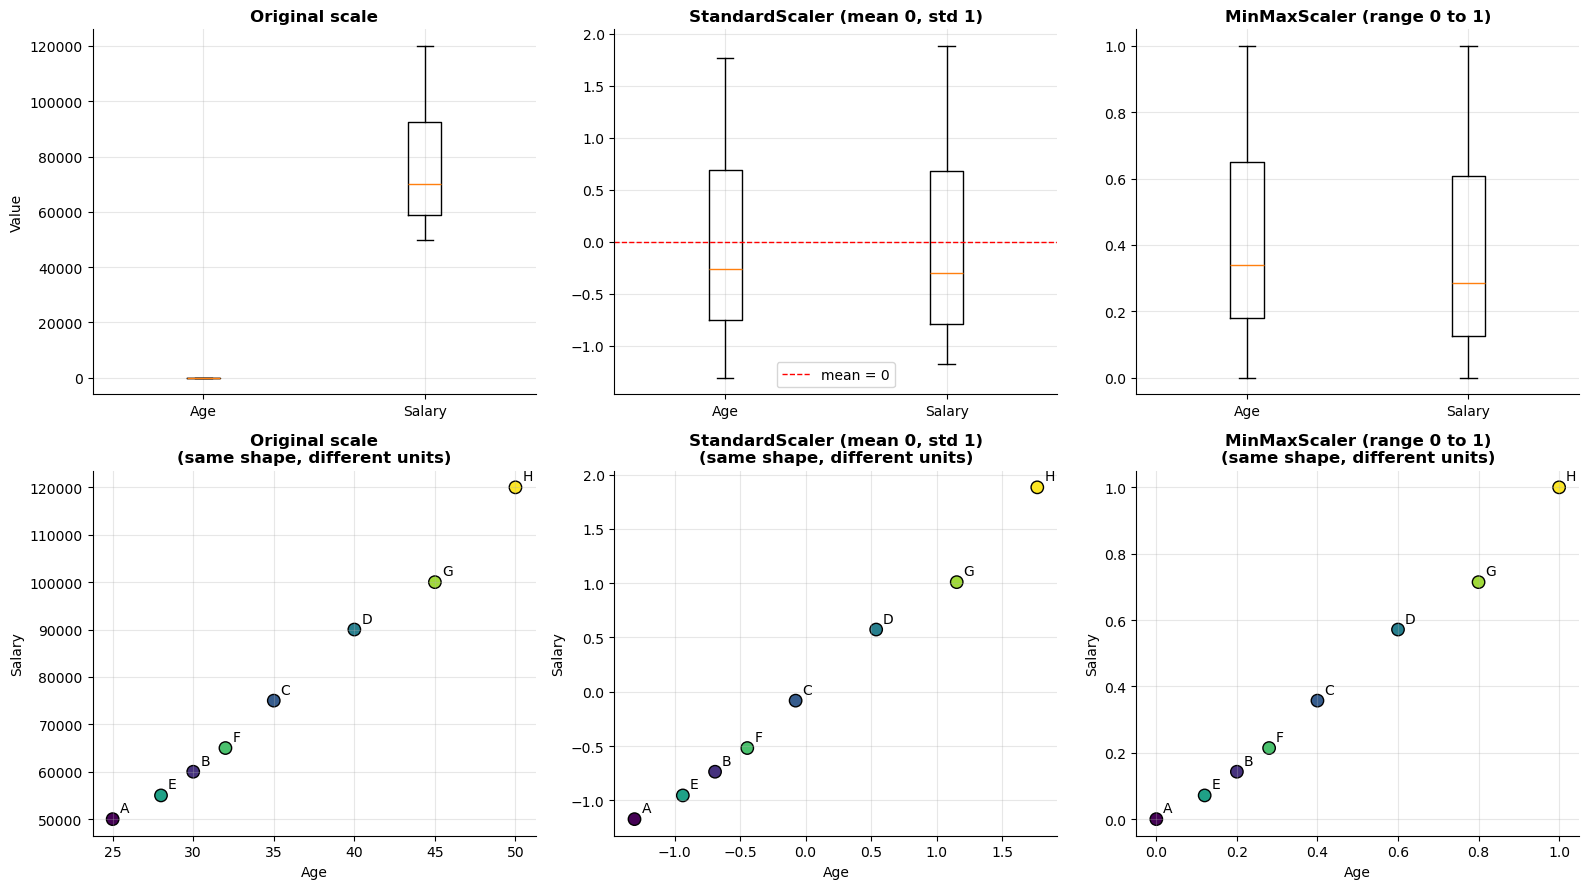

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
datasets = [
    (df[['Age', 'Salary']].values, 'Original scale'),
    (df_std.values, 'StandardScaler (mean 0, std 1)'),
    (df_mm.values, 'MinMaxScaler (range 0 to 1)'),
]

for col, (data, title) in enumerate(datasets):
    ax = axes[0, col]
    ax.boxplot([data[:, 0], data[:, 1]])
    ax.set_xticks([1, 2])
    ax.set_xticklabels(['Age', 'Salary'])
    ax.set_title(title)
    if col == 1:
        ax.axhline(0, color='red', ls='--', lw=1, label='mean = 0')
        ax.legend()

    ax = axes[1, col]
    ax.scatter(data[:, 0], data[:, 1], s=80, c=range(len(data)), cmap='viridis', edgecolor='black')
    for i, (xv, yv) in enumerate(data):
        ax.annotate(chr(65 + i), (xv, yv), xytext=(5, 5), textcoords='offset points')
    ax.set_xlabel('Age')
    ax.set_ylabel('Salary')
    ax.set_title(title + '\n(same shape, different units)')

axes[0, 0].set_ylabel('Value')
plt.tight_layout()
plt.show()

## 1.5 LabelEncoder

### How it works
LabelEncoder sorts the unique categories alphabetically and assigns them the integers 0, 1, 2, and so on. For `Gender`, the sorted categories are `Female`, `Male`, so Female becomes 0 and Male becomes 1.

### When it is appropriate
LabelEncoder is safe for a column with **exactly two** categories, because a single 0/1 column carries no false ordering. For three or more unordered categories it is misleading: encoding `HR=0, IT=1, Sales=2` tells a linear model that Sales is "twice" IT and that IT lies "between" HR and Sales, which is meaningless. LabelEncoder is designed primarily for encoding **target labels** `y`. For input features with more than two categories, OneHotEncoder is used.

In [8]:
le_gender = LabelEncoder()
df['Gender_encoded'] = le_gender.fit_transform(df['Gender'])

gender_mapping = {label: int(code) for label, code in zip(le_gender.classes_, le_gender.transform(le_gender.classes_))}
print('Categories found (classes_):', list(le_gender.classes_))
print('Mapping from label to code :', gender_mapping)
print('Reverse mapping (inverse_transform([0, 1])):', list(le_gender.inverse_transform([0, 1])))

df[['Gender', 'Gender_encoded']]

Categories found (classes_): ['Female', 'Male']
Mapping from label to code : {'Female': 0, 'Male': 1}
Reverse mapping (inverse_transform([0, 1])): ['Female', 'Male']


,Gender,Gender_encoded
0,Male,1
1,Female,0
2,Female,0
3,Male,1
4,Male,1
5,Female,0
6,Male,1
7,Female,0


## 1.6 OneHotEncoder

### How it works
OneHotEncoder creates **one new binary column per category**. For each row, the column matching its category is set to 1 and all others are set to 0.

| Department | Department_HR | Department_IT | Department_Sales |
|---|---|---|---|
| IT | 0 | 1 | 0 |
| HR | 1 | 0 | 0 |
| Sales | 0 | 0 | 1 |

No category is numerically larger than another, so no false ordering is introduced. These new columns are often called **dummy variables**.

`sparse_output=False` asks scikit-learn to return a normal dense array instead of a memory-saving sparse matrix, so the result can be placed directly into a DataFrame.

In [9]:
ohe = OneHotEncoder(sparse_output=False)
dept_encoded = ohe.fit_transform(df[['Department']])      # note the double brackets: a 2-D input is required
dept_columns = ohe.get_feature_names_out(['Department'])
df_dept = pd.DataFrame(dept_encoded, columns=dept_columns, index=df.index).astype(int)

print('Categories learned:', list(ohe.categories_[0]))
print('New column names  :', list(dept_columns))
print()
print('Original column next to its one-hot encoding:')
print(pd.concat([df['Department'], df_dept], axis=1))

# Merge the encoded columns back and drop the original text column
df = pd.concat([df.drop(columns='Department'), df_dept], axis=1)
print()
print('Dataframe after merging and dropping Department:')
df

Categories learned: ['HR', 'IT', 'Sales']
New column names  : ['Department_HR', 'Department_IT', 'Department_Sales']

Original column next to its one-hot encoding:
  Department  Department_HR  Department_IT  Department_Sales
0         IT              0              1                 0
1         HR              1              0                 0
2         IT              0              1                 0
3      Sales              0              0                 1
4         HR              1              0                 0
5      Sales              0              0                 1
6         IT              0              1                 0
7      Sales              0              0                 1

Dataframe after merging and dropping Department:


,Age,Salary,Gender,Performance,Gender_encoded,Department_HR,Department_IT,Department_Sales
0,25,50000,Male,Good,1,0,1,0
1,30,60000,Female,Average,0,1,0,0
2,35,75000,Female,Excellent,0,0,1,0
3,40,90000,Male,Good,1,0,0,1
4,28,55000,Male,Average,1,1,0,0
5,32,65000,Female,Excellent,0,0,0,1
6,45,100000,Male,Good,1,0,1,0
7,50,120000,Female,Average,0,0,0,1


## 1.7 Ordinal mapping with `map()`

`Performance` has a **natural order**: Average < Good < Excellent. One-hot encoding would discard that order, and LabelEncoder would assign codes alphabetically (Average=0, Excellent=1, Good=2), which puts Excellent below Good. A manual mapping preserves the true order.

In [10]:
performance_map = {'Excellent': 3, 'Good': 2, 'Average': 1}
df['Performance_Score'] = df['Performance'].map(performance_map)

# For comparison: what LabelEncoder would have produced (alphabetical, wrong order)
alphabetical = LabelEncoder().fit_transform(df['Performance'])

pd.DataFrame({
    'Performance': df['Performance'],
    'Performance_Score (manual, correct order)': df['Performance_Score'],
    'LabelEncoder (alphabetical, wrong order)': alphabetical,
})

,Performance,"Performance_Score (manual, correct order)","LabelEncoder (alphabetical, wrong order)"
0,Good,2,2
1,Average,1,0
2,Excellent,3,1
3,Good,2,2
4,Average,1,0
5,Excellent,3,1
6,Good,2,2
7,Average,1,0


## 1.8 Final machine-learning-ready dataframe

All steps are now combined. StandardScaler is chosen for the numeric columns (the more common default for models such as linear and logistic regression). The original text columns and unscaled numeric columns are excluded.

In [11]:
df_clean = pd.concat([
    df_std,                        # Age_std, Salary_std
    df[['Gender_encoded']],        # 0 = Female, 1 = Male
    df_dept,                       # Department_HR, Department_IT, Department_Sales
    df[['Performance_Score']],     # 1 = Average, 2 = Good, 3 = Excellent
], axis=1)

print('Data types of the final dataframe:')
print(df_clean.dtypes)
print()
print('Every column numeric:', all(pd.api.types.is_numeric_dtype(t) for t in df_clean.dtypes))
print('Missing values      :', int(df_clean.isna().sum().sum()))
print()
print('Before (original):')
print(df_original)
print()
print('After (ready for machine learning):')
df_clean.round(3)

Data types of the final dataframe:
Age_std              float64
Salary_std           float64
Gender_encoded         int64
Department_HR          int64
Department_IT          int64
Department_Sales       int64
Performance_Score      int64
dtype: object

Every column numeric: True
Missing values      : 0

Before (original):
   Age  Salary Department  Gender Performance
0   25   50000         IT    Male        Good
1   30   60000         HR  Female     Average
2   35   75000         IT  Female   Excellent
3   40   90000      Sales    Male        Good
4   28   55000         HR    Male     Average
5   32   65000      Sales  Female   Excellent
6   45  100000         IT    Male        Good
7   50  120000      Sales  Female     Average

After (ready for machine learning):


,Age_std,Salary_std,Gender_encoded,Department_HR,Department_IT,Department_Sales,Performance_Score
0,-1.306,-1.173,1,0,1,0,2
1,-0.691,-0.737,0,1,0,0,1
2,-0.077,-0.082,0,0,1,0,3
3,0.538,0.573,1,0,0,1,2
4,-0.937,-0.955,1,1,0,0,1
5,-0.445,-0.518,0,0,0,1,3
6,1.152,1.010,1,0,1,0,2
7,1.766,1.883,0,0,0,1,1


## 1.9 Discussion

**When should StandardScaler be used instead of MinMaxScaler?**
StandardScaler is the preferred default for algorithms that assume features are centred around zero or that rely on variance, such as linear regression, logistic regression, SVMs and PCA, and it is less distorted by a single extreme value. MinMaxScaler is preferred when a strict bounded range is required, for example pixel intensities or neural network inputs, but because it depends on the minimum and maximum, a single outlier can squash all other values into a narrow band.

**What happens if features are not scaled before training?**
Features with large numeric ranges dominate distance calculations and gradient updates, so algorithms such as K-Means, KNN, SVM and PCA effectively ignore small-range features, and gradient-based models such as logistic regression converge slowly or fail to converge. Tree-based models (decision trees, random forests) are the exception: they split on one feature at a time using thresholds, so scaling does not change their results.

---
# 2. Train-Test Split and Linear Regression

## 2.1 Concept: why data is split

A model is useful only if it performs well on **data it has never seen**. If a model is evaluated on the same rows it learned from, it can score perfectly simply by memorising them.

**Analogy.** A student who is given the exact exam questions in advance can memorise the answers and score 100%, yet understand nothing. A fair exam uses new questions. The **training set** is the practice material; the **test set** is the unseen exam.

A common split is 80% training and 20% testing. `random_state` fixes the random shuffle so that the same split is produced every time the code runs, making results reproducible.

## 2.2 Concept: linear regression

Linear regression predicts a continuous number as a weighted sum of the features:

$$\hat{y} = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \dots + \beta_p x_p$$

| Symbol | Name | Meaning |
|---|---|---|
| $\hat{y}$ | Prediction | The model's estimate of the target |
| $\beta_0$ | Intercept (`intercept_`) | Predicted value when every feature equals 0 |
| $\beta_1 \dots \beta_p$ | Coefficients (`coef_`) | Change in $\hat{y}$ when that feature increases by 1 unit, with all other features held constant |

### How the coefficients are found: least squares
For every training row, the **residual** is the vertical gap between the actual value and the prediction, $e_i = y_i - \hat{y}_i$. Linear regression chooses the coefficients that make the **sum of squared residuals** as small as possible:

$$\text{minimise} \quad \sum_{i=1}^{n} (y_i - \hat{y}_i)^2$$

Residuals are squared so that positive and negative errors do not cancel out, and so that large errors are penalised more heavily than small ones.

### Worked example
Suppose the model is $\hat{y} = 2 + 3x$ and a student studied $x = 4$ hours with an actual score of $y = 15$.
- Prediction: $\hat{y} = 2 + 3(4) = 14$
- Residual: $15 - 14 = 1$
- Squared residual: $1$

Least squares repeats this for every row and adjusts the intercept and slope until the total is minimised.

## 2.3 The dataset

The target is generated by a known formula plus random noise:

$$y = 5 \cdot \text{Study\_Hours} + 0.3 \cdot \text{Attendance} - 2 \cdot \text{Sleep\_Hours} + \text{noise}$$

Because the true coefficients are known (5, 0.3, and -2), it is possible to check whether linear regression recovers them.

In [12]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

np.random.seed(42)
n = 200
X = pd.DataFrame({
    'Study_Hours': np.random.uniform(1, 10, n),
    'Attendance': np.random.uniform(60, 100, n),
    'Sleep_Hours': np.random.uniform(4, 9, n)
})
y = 5 * X['Study_Hours'] + 0.3 * X['Attendance'] - 2 * X['Sleep_Hours'] + np.random.normal(0, 3, n)

print('Feature matrix X (first 5 rows):')
print(X.head().round(3))
print()
print('Target y (first 5 values):', y.head().round(3).values)

Feature matrix X (first 5 rows):
   Study_Hours  Attendance  Sleep_Hours
0        4.371      85.681        4.516
1        9.556      63.366        8.513
2        7.588      66.465        6.526
3        6.388      95.942        8.132
4        2.404      84.257        5.600

Target y (first 5 values): [36.937 47.388 44.506 41.352 24.437]


### Visualising least squares

Before fitting the full model, the idea is illustrated with a single feature. The left panel shows an arbitrary line; the grey dashed segments are the residuals. The right panel shows the least-squares line, which produces a much smaller sum of squared residuals. No other straight line can produce a smaller total.

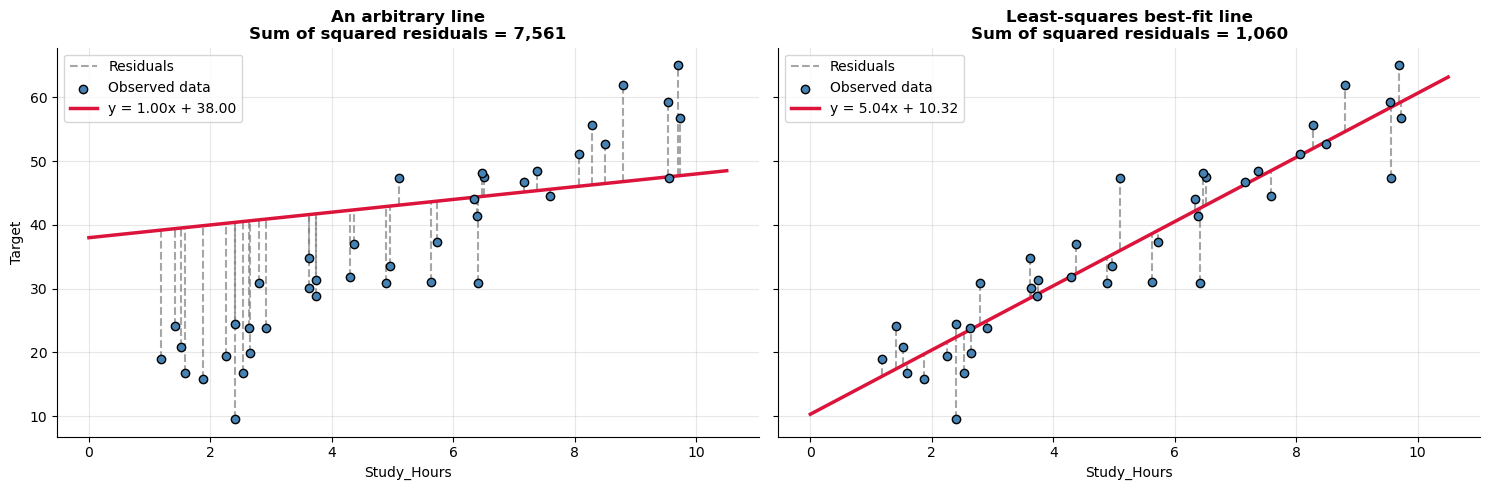

In [13]:
xs = X['Study_Hours'].values[:40]
ys = y.values[:40]
best_slope, best_intercept = np.polyfit(xs, ys, 1)   # least-squares fit on one feature
lines = {'An arbitrary line': (1.0, 38.0), 'Least-squares best-fit line': (best_slope, best_intercept)}

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
grid = np.linspace(0, 10.5, 50)
for ax, (name, (m, c)) in zip(axes, lines.items()):
    pred = m * xs + c
    sse = np.sum((ys - pred) ** 2)
    ax.vlines(xs, np.minimum(ys, pred), np.maximum(ys, pred), color='gray', ls='--', alpha=0.7, label='Residuals')
    ax.scatter(xs, ys, color='steelblue', edgecolor='black', zorder=3, label='Observed data')
    ax.plot(grid, m * grid + c, color='crimson', lw=2.5, label=f'y = {m:.2f}x + {c:.2f}')
    ax.set_title(f'{name}\nSum of squared residuals = {sse:,.0f}')
    ax.set_xlabel('Study_Hours')
    ax.legend()
axes[0].set_ylabel('Target')
plt.tight_layout()
plt.show()

## 2.4 Splitting the data (80-20)
`test_size=0.2` reserves 20% of the rows for testing. The function returns four objects in a fixed order: training features, testing features, training target, testing target.

In [14]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f'X_train shape: {X_train.shape}   -> {X_train.shape[0]} rows, {X_train.shape[1]} features')
print(f'X_test  shape: {X_test.shape}    -> {X_test.shape[0]} rows, {X_test.shape[1]} features')
print(f'y_train shape: {y_train.shape}')
print(f'y_test  shape: {y_test.shape}')
print()
print(f'Training fraction: {len(X_train) / len(X):.0%}   Testing fraction: {len(X_test) / len(X):.0%}')

X_train shape: (160, 3)   -> 160 rows, 3 features
X_test  shape: (40, 3)    -> 40 rows, 3 features
y_train shape: (160,)
y_test  shape: (40,)

Training fraction: 80%   Testing fraction: 20%


## 2.5 Training the model

In [15]:
lin_model = LinearRegression()
lin_model.fit(X_train, y_train)          # learns intercept_ and coef_ by least squares

print(f'Intercept (beta_0): {lin_model.intercept_:.4f}   (true value: 0)')
print()
coef_df = pd.DataFrame({
    'Feature': X.columns,
    'Learned coefficient': lin_model.coef_.round(4),
    'True coefficient': [5, 0.3, -2],
})
coef_df

Intercept (beta_0): -0.2428   (true value: 0)



,Feature,Learned coefficient,True coefficient
0,Study_Hours,4.9524,5.0
1,Attendance,0.2852,0.3
2,Sleep_Hours,-1.7714,-2.0


The learned coefficients are close to the true values used to generate the data. The small differences come from the random noise term and from the limited sample of 160 training rows. The intercept differs more from zero because noise and correlations between the estimates are absorbed there; this is normal.

**Reading a coefficient.** A Study_Hours coefficient of about 5 means: *holding Attendance and Sleep_Hours fixed, each additional hour of study increases the predicted target by about 5 points.*

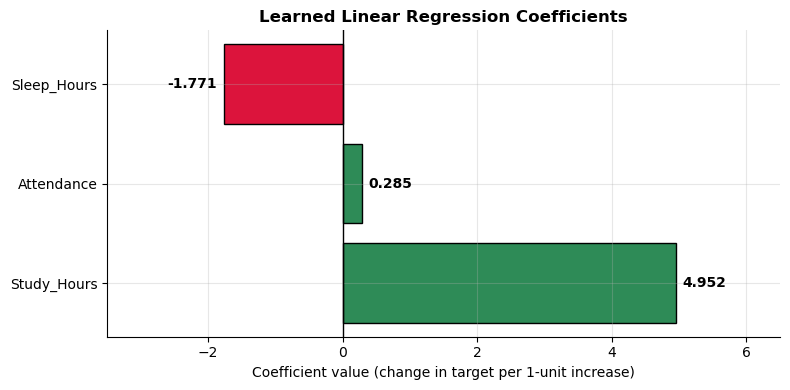

In [16]:
fig, ax = plt.subplots(figsize=(8, 4))
colors = ['seagreen' if c > 0 else 'crimson' for c in lin_model.coef_]
bars = ax.barh(X.columns, lin_model.coef_, color=colors, edgecolor='black')
ax.axvline(0, color='black', lw=1)
for bar, val in zip(bars, lin_model.coef_):
    ax.text(val + (0.1 if val > 0 else -0.1), bar.get_y() + bar.get_height() / 2, f'{val:.3f}',
            va='center', ha='left' if val > 0 else 'right', fontweight='bold')
ax.set_xlabel('Coefficient value (change in target per 1-unit increase)')
ax.set_title('Learned Linear Regression Coefficients')
ax.set_xlim(-3.5, 6.5)
plt.tight_layout()
plt.show()

## 2.6 Predictions: actual versus predicted

If predictions were perfect, every point would lie on the red diagonal line $y = x$. The spread of points around the line represents prediction error. The residual plot on the right shows the errors directly; a good linear model produces residuals scattered randomly around zero with no visible pattern.

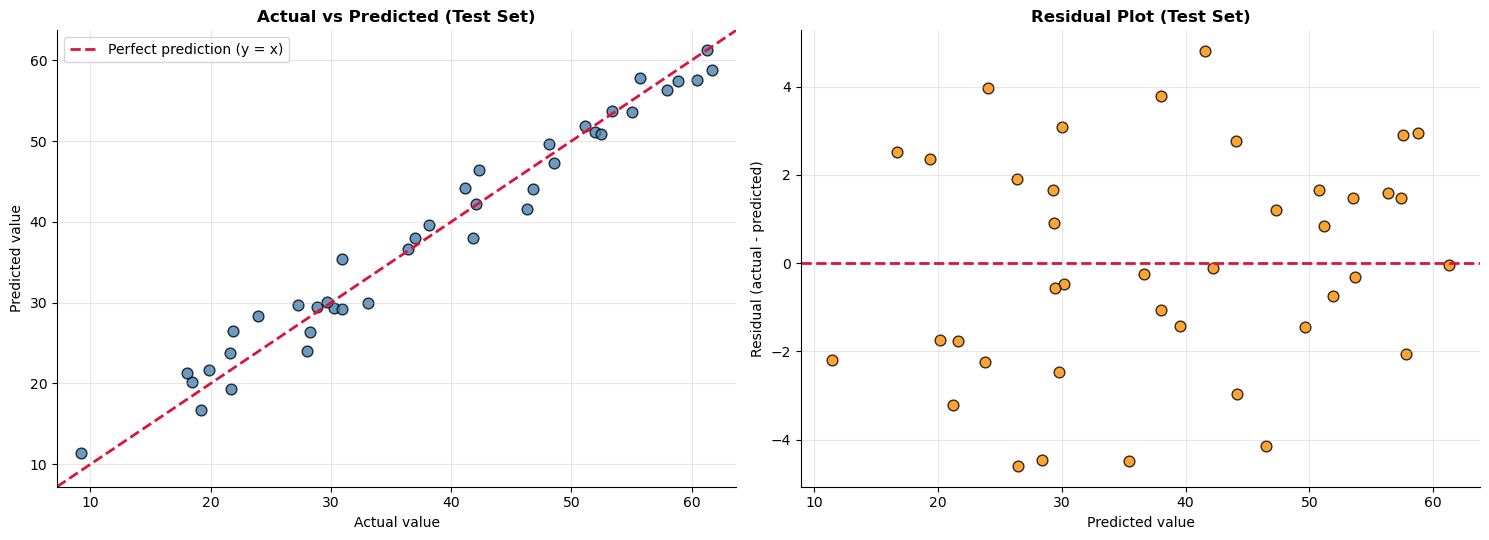

In [17]:
y_pred = lin_model.predict(X_test)
residuals = y_test - y_pred

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

ax = axes[0]
ax.scatter(y_test, y_pred, color='steelblue', edgecolor='black', s=60, alpha=0.8)
lims = [min(y_test.min(), y_pred.min()) - 2, max(y_test.max(), y_pred.max()) + 2]
ax.plot(lims, lims, color='crimson', lw=2, ls='--', label='Perfect prediction (y = x)')
ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_xlabel('Actual value')
ax.set_ylabel('Predicted value')
ax.set_title('Actual vs Predicted (Test Set)')
ax.legend()

ax = axes[1]
ax.scatter(y_pred, residuals, color='darkorange', edgecolor='black', s=60, alpha=0.8)
ax.axhline(0, color='crimson', lw=2, ls='--')
ax.set_xlabel('Predicted value')
ax.set_ylabel('Residual (actual - predicted)')
ax.set_title('Residual Plot (Test Set)')

plt.tight_layout()
plt.show()

## 2.7 Evaluation metrics

### Mean Squared Error (MSE)
$$\text{MSE} = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2$$
The average squared error. Lower is better, and 0 is perfect. Its unit is the square of the target's unit, so the **Root Mean Squared Error** $\text{RMSE} = \sqrt{\text{MSE}}$ is often reported as well, because it is in the same unit as the target.

### R-squared (coefficient of determination)
$$R^2 = 1 - \frac{\sum (y_i - \hat{y}_i)^2}{\sum (y_i - \bar{y})^2}$$

The denominator is the error of a naive model that always predicts the mean $\bar{y}$. R² therefore measures how much better the model is than simply guessing the average.

| R² value | Interpretation |
|---|---|
| 1.0 | Perfect predictions |
| 0.8 | The model explains 80% of the variation in the target |
| 0.0 | No better than always predicting the mean |
| Below 0 | Worse than predicting the mean |

In [18]:
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

# Manual calculation to confirm the formulas
manual_mse = np.mean((y_test - y_pred) ** 2)
manual_r2 = 1 - np.sum((y_test - y_pred) ** 2) / np.sum((y_test - y_test.mean()) ** 2)

print('Test set performance')
print(f'  MSE  : {mse:.4f}   (manual: {manual_mse:.4f})')
print(f'  RMSE : {rmse:.4f}   -> a typical prediction is off by about {rmse:.2f} points')
print(f'  R²   : {r2:.4f}   (manual: {manual_r2:.4f}) -> the model explains {r2:.1%} of the variance')
print()
y_train_pred = lin_model.predict(X_train)
print('Training set performance (for comparison)')
print(f'  MSE  : {mean_squared_error(y_train, y_train_pred):.4f}')
print(f'  R²   : {r2_score(y_train, y_train_pred):.4f}')
print()
print('The noise term has standard deviation 3 (variance 9), so on average no model can achieve an MSE much below 9.')
print('With only 40 test rows, the test MSE can fall above or below 9 by chance, which is why the test value here differs.')

Test set performance
  MSE  : 6.2137   (manual: 6.2137)
  RMSE : 2.4927   -> a typical prediction is off by about 2.49 points
  R²   : 0.9698   (manual: 0.9698) -> the model explains 97.0% of the variance

Training set performance (for comparison)
  MSE  : 9.9150
  R²   : 0.9517

The noise term has standard deviation 3 (variance 9), so on average no model can achieve an MSE much below 9.
With only 40 test rows, the test MSE can fall above or below 9 by chance, which is why the test value here differs.


## 2.8 Interpreting the coefficients: which feature has the strongest positive impact?

The raw coefficient tells the effect of a one-unit change, but one unit means different things for different features (one hour versus one percentage point of attendance). A fair comparison multiplies each coefficient by the feature's standard deviation, giving the effect of a **typical** change in that feature.

In [19]:
impact = pd.DataFrame({
    'Coefficient': lin_model.coef_,
    'Feature std': X_train.std().values,
    'Feature range': (X_train.max() - X_train.min()).values,
}, index=X.columns)
impact['Effect of a 1-std increase'] = impact['Coefficient'] * impact['Feature std']
impact['Effect across full range'] = impact['Coefficient'] * impact['Feature range']
print(impact.round(3))
print()

strongest = impact['Coefficient'].idxmax()
print(f'Strongest positive impact: {strongest}')
print(f'  Per unit        : +{impact.loc[strongest, "Coefficient"]:.2f} per hour')
print(f'  Per typical std : +{impact.loc[strongest, "Effect of a 1-std increase"]:.2f}')
print('Attendance also has a positive effect but is much weaker, even after accounting for its larger range.')
print('Sleep_Hours has a negative coefficient: more sleep hours are associated with a lower target in this synthetic data.')

             Coefficient  Feature std  Feature range  Effect of a 1-std increase  Effect across full range
Study_Hours        4.952        2.655          8.821                      13.146                    43.686
Attendance         0.285       11.902         39.418                       3.395                    11.242
Sleep_Hours       -1.771        1.530          4.944                      -2.710                    -8.759

Strongest positive impact: Study_Hours
  Per unit        : +4.95 per hour
  Per typical std : +13.15
Attendance also has a positive effect but is much weaker, even after accounting for its larger range.
Sleep_Hours has a negative coefficient: more sleep hours are associated with a lower target in this synthetic data.


## 2.9 Discussion

**Why is it important to split data into training and testing sets?**
The goal of a model is to make accurate predictions on new, unseen data, and the test set simulates that situation by holding back rows the model never learns from. Performance on the test set is therefore an honest estimate of how the model will behave after deployment.

**What problem occurs if the model is evaluated on the same data it was trained on?**
The evaluation becomes over-optimistic, because a model can fit the noise and quirks of its training rows, a problem known as **overfitting**. A highly flexible model could achieve near-perfect training scores while performing poorly on new data, and this failure would go completely undetected without a separate test set.

---
# 3. Logistic Regression and Classification

## 3.1 Concept

Classification predicts a **category**, such as approved or not approved. Linear regression is unsuitable for this, because a straight line produces values like -0.4 or 1.7, which cannot be interpreted as a yes/no answer or a probability.

Logistic regression solves this in two steps:

1. Compute a linear score exactly as in linear regression: $z = \beta_0 + \beta_1 x_1 + \dots + \beta_p x_p$
2. Pass that score through the **sigmoid function**, which squeezes any number into the range 0 to 1:

$$\sigma(z) = \frac{1}{1 + e^{-z}}$$

The output $\sigma(z)$ is the **probability that the sample belongs to class 1**. A threshold, 0.5 by default, turns the probability into a class: probability $\geq 0.5$ means class 1, otherwise class 0.

Despite its name, logistic regression is a **classification** algorithm.

### Worked example
Suppose a trained model gives $z = -1 + 2 \times (\text{scaled credit score})$.

| Scaled credit score | $z$ | $\sigma(z)$ | Predicted class |
|---|---|---|---|
| -1.0 | -3.0 | $1/(1+e^{3}) = 0.047$ | 0 (rejected) |
| 0.5 | 0.0 | $1/(1+e^{0}) = 0.500$ | 1 (on the boundary) |
| 1.5 | 2.0 | $1/(1+e^{-2}) = 0.881$ | 1 (approved) |

### How the coefficients are learned
The model is trained by minimising **log loss** (cross-entropy):

$$\text{Log loss} = -\frac{1}{n}\sum_{i=1}^{n}\left[y_i \log(p_i) + (1-y_i)\log(1-p_i)\right]$$

This loss is small when the model assigns high probability to the correct class and very large when it is confidently wrong. There is no closed-form solution, so an iterative optimiser adjusts the coefficients step by step. `max_iter=1000` allows it enough steps to converge.

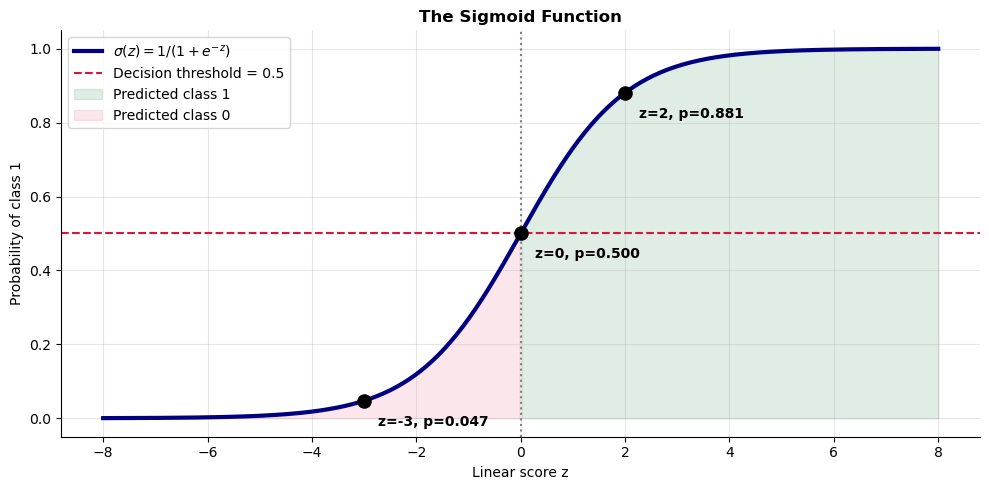

In [20]:
z = np.linspace(-8, 8, 400)
sigmoid = 1 / (1 + np.exp(-z))

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(z, sigmoid, color='navy', lw=3, label=r'$\sigma(z) = 1 / (1 + e^{-z})$')
ax.axhline(0.5, color='crimson', ls='--', lw=1.5, label='Decision threshold = 0.5')
ax.axvline(0, color='gray', ls=':', lw=1.5)
ax.fill_between(z, 0, sigmoid, where=(z >= 0), color='seagreen', alpha=0.15, label='Predicted class 1')
ax.fill_between(z, 0, sigmoid, where=(z < 0), color='crimson', alpha=0.10, label='Predicted class 0')
for zv in [-3, 0, 2]:
    sv = 1 / (1 + np.exp(-zv))
    ax.scatter(zv, sv, s=90, color='black', zorder=5)
    ax.annotate(f'z={zv}, p={sv:.3f}', (zv, sv), xytext=(10, -18), textcoords='offset points', fontweight='bold')
ax.set_xlabel('Linear score z')
ax.set_ylabel('Probability of class 1')
ax.set_title('The Sigmoid Function')
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

## 3.2 The dataset

A loan is approved only if **both** Credit_Score > 650 **and** Income > 45000. Age has no effect on the outcome.

In [21]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.preprocessing import StandardScaler

np.random.seed(42)
n = 300
df_loan = pd.DataFrame({
    'Age': np.random.randint(18, 60, n),
    'Income': np.random.normal(50000, 15000, n),
    'Credit_Score': np.random.randint(300, 850, n)
})
df_loan['Approved'] = ((df_loan['Credit_Score'] > 650) & (df_loan['Income'] > 45000)).astype(int)

print(df_loan.head())
print()
counts = df_loan['Approved'].value_counts()
print('Class distribution:')
print(f'  Not approved (0): {counts[0]}  ({counts[0] / n:.1%})')
print(f'  Approved     (1): {counts[1]}  ({counts[1] / n:.1%})')
print('The classes are imbalanced: most applications are not approved.')

   Age        Income  Credit_Score  Approved
0   56  62751.808732           355         0
1   46  55915.099272           825         1
2   32  49929.560080           773         1
3   25  26437.820247           327         0
4   38  72197.731628           377         0

Class distribution:
  Not approved (0): 247  (82.3%)
  Approved     (1): 53  (17.7%)
The classes are imbalanced: most applications are not approved.


## 3.3 Separate features and target, then split (75-25)

In [22]:
X = df_loan[['Age', 'Income', 'Credit_Score']]
y = df_loan['Approved']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
print(f'Training set: {X_train.shape[0]} rows   Test set: {X_test.shape[0]} rows')
print(f'Approval rate in training set: {y_train.mean():.1%}   in test set: {y_test.mean():.1%}')

Training set: 225 rows   Test set: 75 rows
Approval rate in training set: 17.3%   in test set: 18.7%


## 3.4 Scaling correctly: fit on training data only

This step prevents **data leakage**. The scaler must learn its mean and standard deviation from the training set only, and then apply those same numbers to the test set.

- `scaler.fit_transform(X_train)` learns the statistics from training data and scales it.
- `scaler.transform(X_test)` reuses the **training** statistics on the test data.

If the scaler were fitted on the full dataset, information about the test rows (their mean and spread) would influence training. The test set would no longer be truly unseen, and the reported accuracy would be slightly optimistic.

In [23]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # learn from training data
X_test_scaled = scaler.transform(X_test)         # apply training statistics; never fit on test data

print('Means learned from the training set :', scaler.mean_.round(2))
print('Means of the full dataset (not used):', X.mean().values.round(2))
print()
print('Scaled training data -> mean:', X_train_scaled.mean(axis=0).round(4), ' std:', X_train_scaled.std(axis=0).round(4))
print('Scaled test data     -> mean:', X_test_scaled.mean(axis=0).round(4), ' std:', X_test_scaled.std(axis=0).round(4))
print('The test set is close to, but not exactly, mean 0 and std 1. This is expected and correct.')

Means learned from the training set : [3.88100e+01 4.97059e+04 5.62190e+02]
Means of the full dataset (not used): [3.899000e+01 4.917907e+04 5.638300e+02]

Scaled training data -> mean: [ 0. -0. -0.]  std: [1. 1. 1.]
Scaled test data     -> mean: [ 0.0571 -0.131   0.0396]  std: [0.9033 0.9756 0.8955]
The test set is close to, but not exactly, mean 0 and std 1. This is expected and correct.


## 3.5 Training the logistic regression model

In [24]:
log_model = LogisticRegression(max_iter=1000)
log_model.fit(X_train_scaled, y_train)

print(f'Intercept: {log_model.intercept_[0]:.4f}')
print(pd.DataFrame({'Feature': X.columns, 'Coefficient (scaled units)': log_model.coef_[0].round(4)}))
print()
print('Because the features are scaled, coefficients can be compared directly.')
print('Credit_Score and Income have large positive coefficients; Age is close to zero, matching the rule that generated the data.')

Intercept: -3.9439
        Feature  Coefficient (scaled units)
0           Age                     -0.0728
1        Income                      1.7045
2  Credit_Score                      3.3630

Because the features are scaled, coefficients can be compared directly.
Credit_Score and Income have large positive coefficients; Age is close to zero, matching the rule that generated the data.


## 3.6 Predictions and accuracy

$$\text{Accuracy} = \frac{\text{Number of correct predictions}}{\text{Total number of predictions}}$$

Accuracy must always be compared with a **baseline**. With imbalanced classes, a useless model that always predicts "not approved" can already achieve high accuracy.

In [25]:
y_pred = log_model.predict(X_test_scaled)
y_proba = log_model.predict_proba(X_test_scaled)[:, 1]   # probability of class 1

accuracy = accuracy_score(y_test, y_pred)
baseline = (y_test == 0).mean()

print(f'Model accuracy                               : {accuracy:.4f}  ({accuracy:.1%})')
print(f'Baseline accuracy (always predict class 0)   : {baseline:.4f}  ({baseline:.1%})')
print()
print('First 8 test predictions:')
print(pd.DataFrame({'P(Approved)': y_proba[:8].round(3), 'Predicted': y_pred[:8], 'Actual': y_test.values[:8]}))

Model accuracy                               : 0.8667  (86.7%)
Baseline accuracy (always predict class 0)   : 0.8133  (81.3%)

First 8 test predictions:
   P(Approved)  Predicted  Actual
0        0.015          0       0
1        0.000          0       0
2        0.061          0       0
3        0.114          0       0
4        0.242          0       1
5        0.000          0       0
6        0.004          0       0
7        0.837          1       1


## 3.7 The confusion matrix

A confusion matrix breaks accuracy into the four possible outcomes. In scikit-learn the layout is:

|  | Predicted 0 | Predicted 1 |
|---|---|---|
| **Actual 0** | **TN** (True Negative) | **FP** (False Positive) |
| **Actual 1** | **FN** (False Negative) | **TP** (True Positive) |

A convenient way to read the names: the second word (Positive/Negative) is what the model **predicted**, and the first word (True/False) says whether that prediction was **correct**.

Confusion matrix:
[[57  4]
 [ 6  8]]

TN =  57  Not approved, and the model correctly predicted not approved.
FP =   4  Not approved, but the model wrongly predicted approved (a risky loan would be given).
FN =   6  Approved, but the model wrongly predicted not approved (a good customer is turned away).
TP =   8  Approved, and the model correctly predicted approved.

Check: (TN + TP) / total = (57 + 8) / 75 = 0.8667 = accuracy


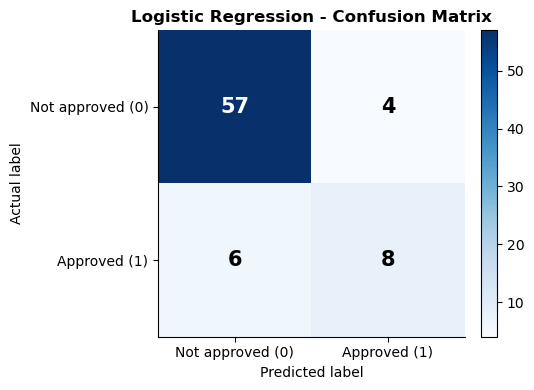

In [26]:
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

print('Confusion matrix:')
print(cm)
print()
print(f'TN = {tn:3d}  Not approved, and the model correctly predicted not approved.')
print(f'FP = {fp:3d}  Not approved, but the model wrongly predicted approved (a risky loan would be given).')
print(f'FN = {fn:3d}  Approved, but the model wrongly predicted not approved (a good customer is turned away).')
print(f'TP = {tp:3d}  Approved, and the model correctly predicted approved.')
print()
print(f'Check: (TN + TP) / total = ({tn} + {tp}) / {cm.sum()} = {(tn + tp) / cm.sum():.4f} = accuracy')

plot_confusion_matrix(cm, ['Not approved (0)', 'Approved (1)'], 'Logistic Regression - Confusion Matrix')
plt.tight_layout()
plt.show()

## 3.8 Precision, recall and F1-score

| Metric | Formula | Question it answers |
|---|---|---|
| **Precision** | $\dfrac{TP}{TP + FP}$ | Of everything predicted positive, how much was actually positive? |
| **Recall** (sensitivity) | $\dfrac{TP}{TP + FN}$ | Of everything actually positive, how much did the model find? |
| **F1-score** | $2 \cdot \dfrac{\text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}}$ | A single score balancing both (their harmonic mean) |

### Worked example
A model flags 10 emails as spam. 8 really are spam (TP = 8) and 2 are legitimate (FP = 2). There were 20 spam emails in total, so 12 were missed (FN = 12).
- Precision = 8 / (8 + 2) = **0.80**: when it says spam, it is usually right.
- Recall = 8 / (8 + 12) = **0.40**: it only catches 40% of all spam.
- F1 = 2 × (0.80 × 0.40) / (0.80 + 0.40) = **0.533**

### Reading the classification report
- One row per class, where each class in turn is treated as the "positive" class.
- **support**: the number of actual samples of that class in the test set.
- **macro avg**: simple average across classes, treating each class equally.
- **weighted avg**: average weighted by support, so larger classes count more.

In [27]:
print(classification_report(y_test, y_pred, target_names=['Not approved (0)', 'Approved (1)'], digits=4))

precision_1 = tp / (tp + fp)
recall_1 = tp / (tp + fn)
f1_1 = 2 * precision_1 * recall_1 / (precision_1 + recall_1)
print('Manual calculation for class 1 (Approved):')
print(f'  Precision = {tp} / ({tp} + {fp}) = {precision_1:.4f}')
print(f'  Recall    = {tp} / ({tp} + {fn}) = {recall_1:.4f}')
print(f'  F1        = {f1_1:.4f}')

                  precision    recall  f1-score   support

Not approved (0)     0.9048    0.9344    0.9194        61
    Approved (1)     0.6667    0.5714    0.6154        14

        accuracy                         0.8667        75
       macro avg     0.7857    0.7529    0.7674        75
    weighted avg     0.8603    0.8667    0.8626        75

Manual calculation for class 1 (Approved):
  Precision = 8 / (8 + 4) = 0.6667
  Recall    = 8 / (8 + 6) = 0.5714
  F1        = 0.6154


## 3.9 Visualising the decision boundary

The true approval rule is a **rectangle**: Credit_Score above 650 and Income above 45000. Logistic regression can only draw a **straight line** as its boundary (the set of points where probability equals 0.5). The plot below shows the model's probability surface with Age fixed at its average. Misclassifications occur mainly near the corner of the rectangle, where a straight line cannot follow the true rule.

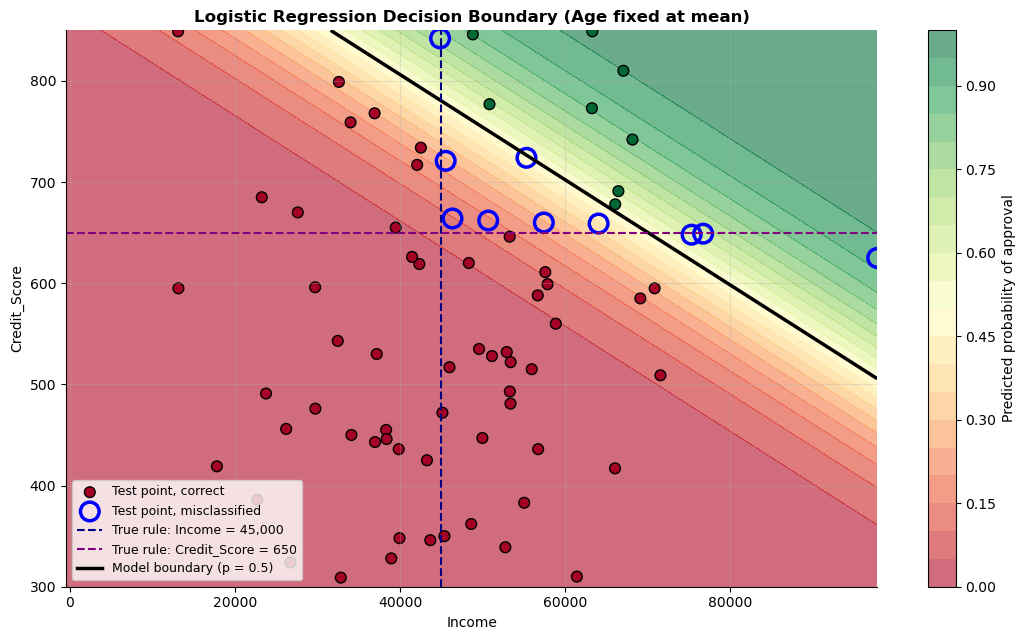

In [28]:
income_grid = np.linspace(df_loan['Income'].min(), df_loan['Income'].max(), 200)
credit_grid = np.linspace(300, 850, 200)
II, CC = np.meshgrid(income_grid, credit_grid)
grid_points = pd.DataFrame({'Age': X_train['Age'].mean(), 'Income': II.ravel(), 'Credit_Score': CC.ravel()})
probs = log_model.predict_proba(scaler.transform(grid_points))[:, 1].reshape(II.shape)

fig, ax = plt.subplots(figsize=(11, 6.5))
contour = ax.contourf(II, CC, probs, levels=20, cmap='RdYlGn', alpha=0.6)
ax.contour(II, CC, probs, levels=[0.5], colors='black', linewidths=2.5)
plt.colorbar(contour, label='Predicted probability of approval')

correct = y_pred == y_test.values
ax.scatter(X_test['Income'][correct], X_test['Credit_Score'][correct], c=y_test[correct], cmap='RdYlGn',
           edgecolor='black', s=60, label='Test point, correct')
ax.scatter(X_test['Income'][~correct], X_test['Credit_Score'][~correct], facecolor='none', edgecolor='blue',
           s=180, linewidths=2.5, label='Test point, misclassified')
ax.axvline(45000, color='navy', ls='--', lw=1.5, label='True rule: Income = 45,000')
ax.axhline(650, color='purple', ls='--', lw=1.5, label='True rule: Credit_Score = 650')
ax.plot([], [], color='black', lw=2.5, label='Model boundary (p = 0.5)')
ax.set_xlabel('Income')
ax.set_ylabel('Credit_Score')
ax.set_title('Logistic Regression Decision Boundary (Age fixed at mean)')
ax.legend(loc='lower left', fontsize=9)
plt.tight_layout()
plt.show()

## 3.10 The precision-recall trade-off

The 0.5 threshold is a choice, not a rule. Raising the threshold makes the model more cautious about predicting class 1: precision rises but recall falls. Lowering it has the opposite effect. The plot shows this trade-off on the test set.

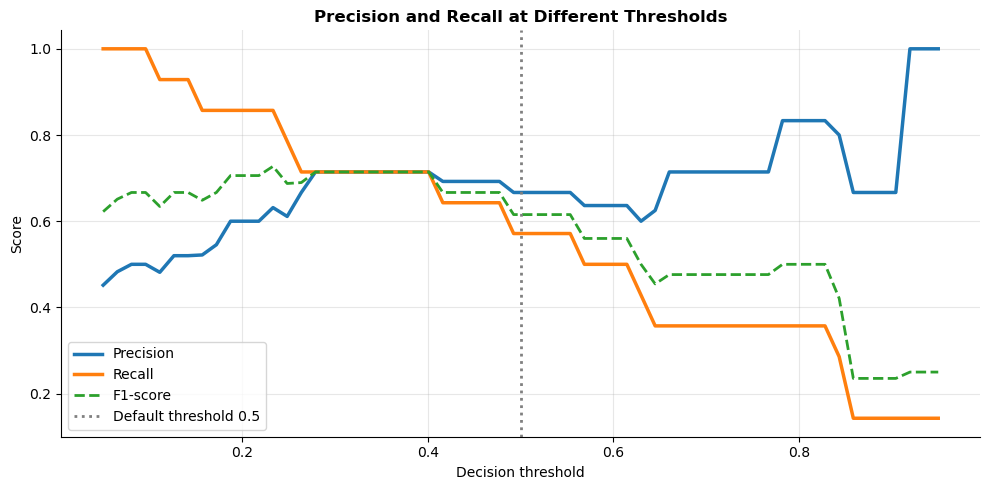

In [29]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = np.linspace(0.05, 0.95, 60)
prec = [precision_score(y_test, (y_proba >= t).astype(int), zero_division=0) for t in thresholds]
rec = [recall_score(y_test, (y_proba >= t).astype(int), zero_division=0) for t in thresholds]
f1s = [f1_score(y_test, (y_proba >= t).astype(int), zero_division=0) for t in thresholds]

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(thresholds, prec, lw=2.5, label='Precision')
ax.plot(thresholds, rec, lw=2.5, label='Recall')
ax.plot(thresholds, f1s, lw=2, ls='--', label='F1-score')
ax.axvline(0.5, color='gray', ls=':', lw=2, label='Default threshold 0.5')
ax.set_xlabel('Decision threshold')
ax.set_ylabel('Score')
ax.set_title('Precision and Recall at Different Thresholds')
ax.legend()
plt.tight_layout()
plt.show()

## 3.11 Discussion

**What is the difference between precision and recall?**
Precision measures how trustworthy the positive predictions are: of all samples predicted positive, the fraction that truly are positive. Recall measures how complete the positive predictions are: of all truly positive samples, the fraction the model managed to find.

**When should one be prioritised over the other?**
Recall is prioritised when missing a positive case is costly, such as cancer screening or fraud detection, where a false negative can be disastrous and some false alarms are acceptable. Precision is prioritised when a false positive is costly, such as spam filtering (an important email must not be hidden) or, in this loan example, approving a risky borrower.

---
# 4. K-Means Clustering (Unsupervised Learning)

## 4.1 Concept

In unsupervised learning there is **no target column**. The algorithm receives only features and must discover structure on its own. Clustering groups samples so that points in the same group are similar to each other and different from points in other groups.

**Example.** A shop has purchase data for thousands of customers but no labels. Clustering might reveal three natural groups: budget shoppers, occasional big spenders, and frequent loyal customers. Nobody defined these groups in advance.

## 4.2 How K-Means works

K-Means represents each cluster by its **centroid**, the average position of its points. The algorithm repeats two simple steps:

1. **Initialise.** Choose $K$ and place $K$ starting centroids.
2. **Assign.** Assign every point to its nearest centroid, using Euclidean distance.
3. **Update.** Move each centroid to the mean of the points assigned to it.
4. **Repeat** steps 2 and 3 until the assignments stop changing.

The quantity K-Means minimises is the **inertia**, also called the within-cluster sum of squares:

$$\text{Inertia} = \sum_{i=1}^{n} \lVert x_i - \mu_{c(i)} \rVert^2$$

where $\mu_{c(i)}$ is the centroid of the cluster that point $x_i$ belongs to. Lower inertia means tighter clusters.

### Worked example (one dimension)
Points: 1, 2, 3, 10, 11, 12. $K = 2$. Start with centroids at 1 and 2.
- **Assign:** 1 goes to centroid 1; 2, 3, 10, 11, 12 all go to centroid 2.
- **Update:** centroid 1 = mean(1) = 1; centroid 2 = mean(2, 3, 10, 11, 12) = 7.6.
- **Assign:** 1, 2, 3 are nearer 1; 10, 11, 12 are nearer 7.6.
- **Update:** centroid 1 = mean(1, 2, 3) = 2; centroid 2 = mean(10, 11, 12) = 11.
- **Assign:** nothing changes. The algorithm has converged with clusters {1, 2, 3} and {10, 11, 12}.

### Parameters used in this lab
- `n_clusters`: the number of clusters $K$.
- `n_init=10`: K-Means is sensitive to the starting centroids, so it is run 10 times with different starts and the result with the lowest inertia is kept.
- `random_state=42`: makes the random starts reproducible.
- Scikit-learn uses **k-means++** initialisation by default, which spreads the starting centroids apart for faster and more reliable convergence.

       Feature_1  Feature_2
count     150.00     150.00
mean       49.87      43.45
std        25.11      13.28
min        12.14      24.04
25%        21.04      31.95
50%        49.96      40.32
75%        77.97      56.94
max        86.94      70.88


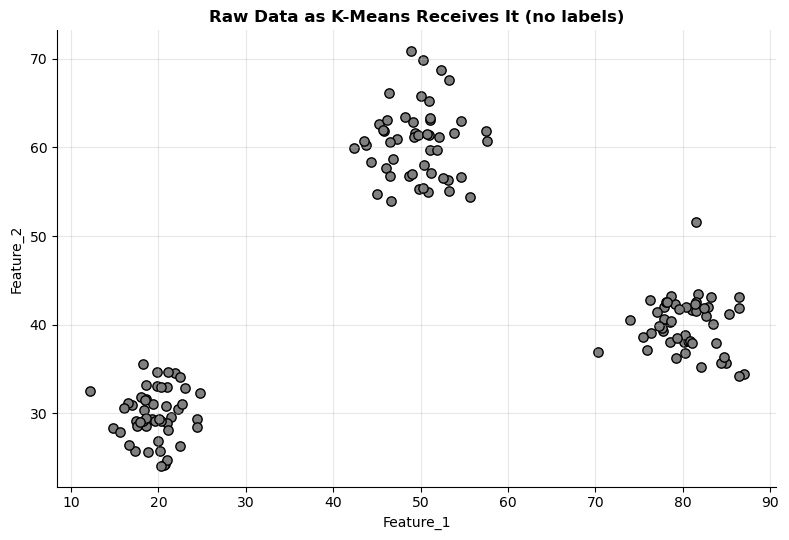

In [30]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples

np.random.seed(42)
cluster1 = np.random.normal(loc=[20, 30], scale=3, size=(50, 2))
cluster2 = np.random.normal(loc=[50, 60], scale=4, size=(50, 2))
cluster3 = np.random.normal(loc=[80, 40], scale=3, size=(50, 2))
X = np.vstack([cluster1, cluster2, cluster3])
df_clust = pd.DataFrame(X, columns=['Feature_1', 'Feature_2'])
true_group = np.repeat([0, 1, 2], 50)   # kept only for checking; K-Means never sees this

print(df_clust.describe().round(2))

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.scatter(df_clust['Feature_1'], df_clust['Feature_2'], color='gray', edgecolor='black', s=45)
ax.set_xlabel('Feature_1'); ax.set_ylabel('Feature_2')
ax.set_title('Raw Data as K-Means Receives It (no labels)')
plt.tight_layout()
plt.show()

## 4.3 Scaling the features

K-Means assigns points using distances, so every feature must contribute fairly. Here both features happen to be on similar ranges, but scaling is still applied as standard practice, because in real data one feature measured in thousands would otherwise decide every assignment.

In [31]:
scaler_km = StandardScaler()
X_scaled = scaler_km.fit_transform(df_clust)
print('Scaled means:', X_scaled.mean(axis=0).round(4))
print('Scaled stds :', X_scaled.std(axis=0).round(4))

Scaled means: [ 0. -0.]
Scaled stds : [1. 1.]


## 4.4 Watching K-Means run, step by step

To show the algorithm in action, the assign-update loop is implemented by hand with two different sets of starting centroids. The red crosses are the centroids.

- **Top row (a workable start):** two centroids begin inside the same group. Within two iterations one of them migrates to the empty group, and inertia falls from about 175 to about 12.
- **Bottom row (a poor start):** two centroids begin in the lower-left group and the third begins in the upper group. The algorithm converges, but to the wrong answer: it splits one real group in two and merges the other two groups. Inertia stops at about 109 and never improves, because no single assign or update step can escape this arrangement.

The bottom row is called a **local minimum**. It is exactly why scikit-learn runs K-Means several times with different starts (`n_init=10`) and keeps the run with the lowest inertia.

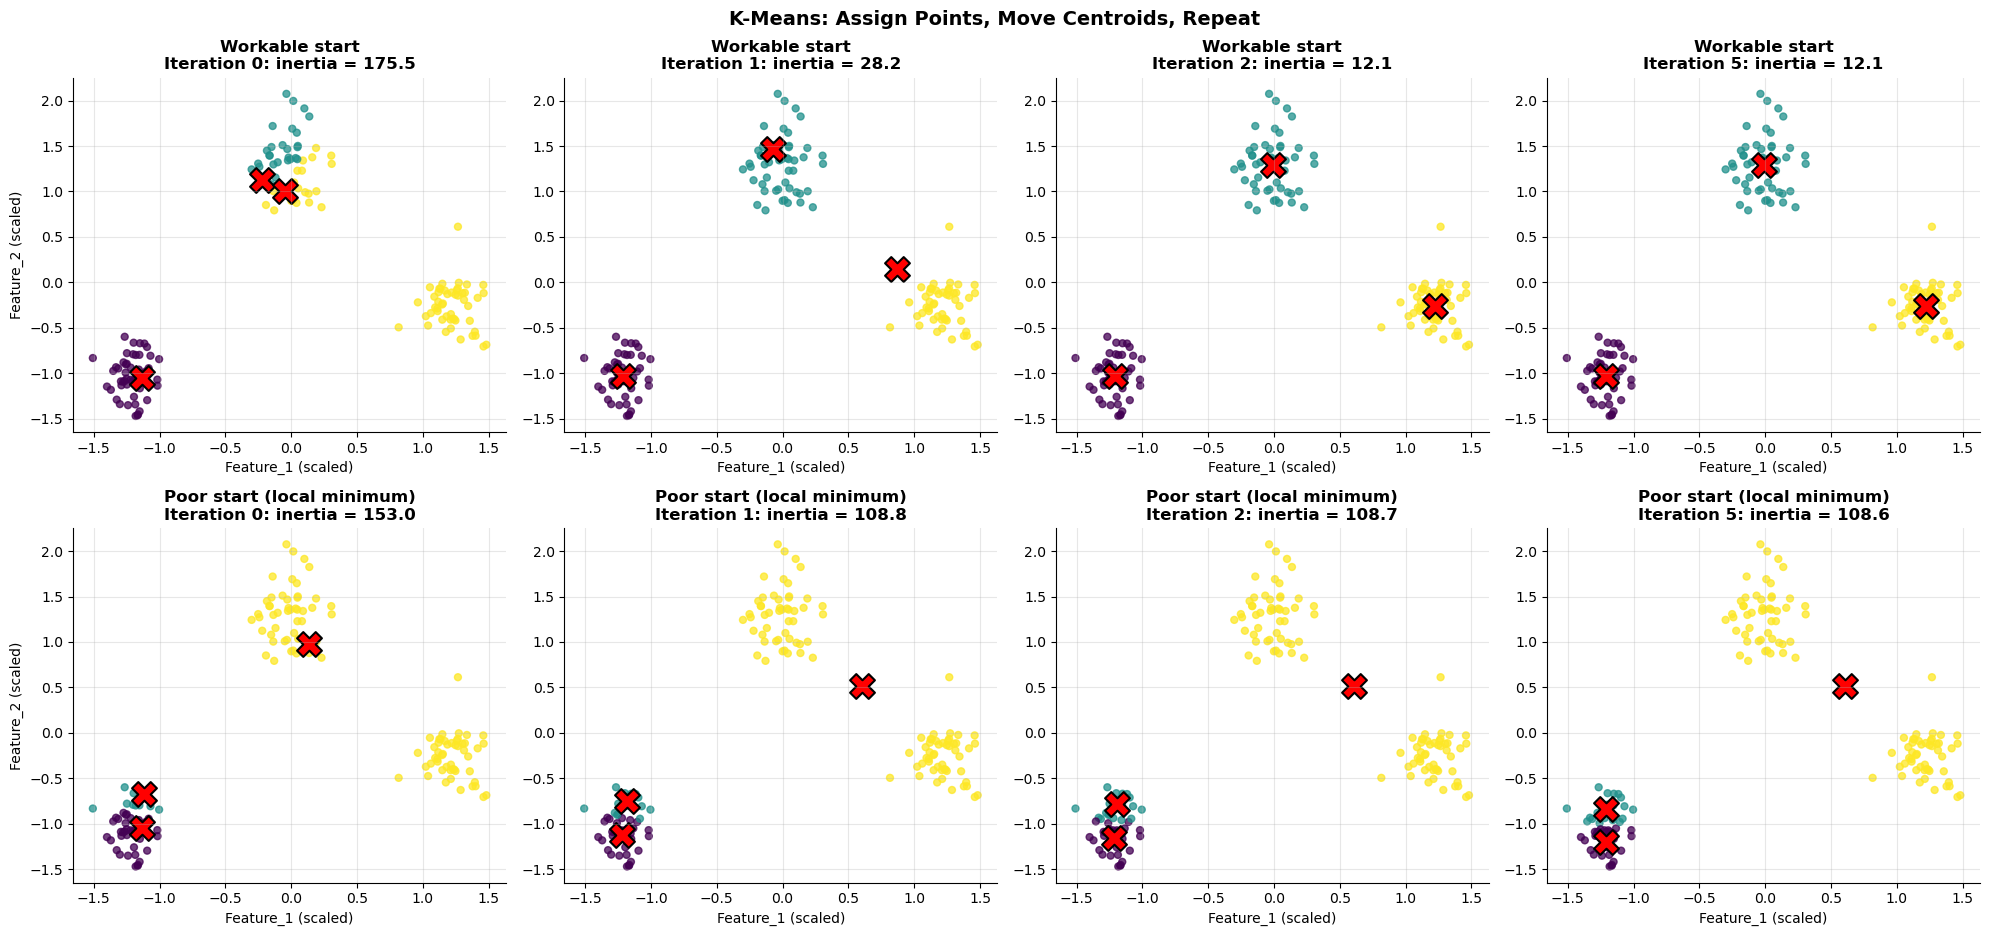

In [32]:
def run_kmeans_by_hand(points, start_idx, n_iter=6):
    cents = points[start_idx].copy()
    history = []
    for iteration in range(n_iter):
        dists = np.linalg.norm(points[:, None, :] - cents[None, :, :], axis=2)
        labs = dists.argmin(axis=1)                                          # assign step
        history.append((iteration, cents.copy(), labs.copy(), np.sum((points - cents[labs]) ** 2)))
        cents = np.array([points[labs == k].mean(axis=0) for k in range(len(cents))])  # update step
    return history

pts = X_scaled
runs = {'Workable start': run_kmeans_by_hand(pts, [0, 50, 51]),
        'Poor start (local minimum)': run_kmeans_by_hand(pts, [0, 1, 60])}

fig, axes = plt.subplots(2, 4, figsize=(20, 9.5))
for row, (run_name, history) in enumerate(runs.items()):
    for ax, idx in zip(axes[row], [0, 1, 2, 5]):
        it, cents, labs, inert = history[idx]
        ax.scatter(pts[:, 0], pts[:, 1], c=labs, cmap='viridis', s=25, alpha=0.75)
        ax.scatter(cents[:, 0], cents[:, 1], c='red', marker='X', s=320, edgecolor='black', linewidths=1.5)
        ax.set_title(f'{run_name}\nIteration {it}: inertia = {inert:.1f}')
        ax.set_xlabel('Feature_1 (scaled)')
    axes[row, 0].set_ylabel('Feature_2 (scaled)')
plt.suptitle('K-Means: Assign Points, Move Centroids, Repeat', fontweight='bold', fontsize=14)
plt.tight_layout()
plt.show()

## 4.5 The Elbow Method

K-Means requires $K$ to be chosen in advance. Inertia always decreases as $K$ increases (with $K$ equal to the number of points, inertia is zero), so the smallest inertia cannot be used to choose $K$.

Instead, inertia is plotted against $K$. At first, adding a cluster reduces inertia dramatically because a genuinely separate group gets its own centroid. Once the true number of groups is reached, extra clusters only split existing groups and the improvement becomes small. The point where the curve bends, like an **elbow**, is the chosen $K$.

 K  Inertia  Reduction from previous K
 1   300.00                        NaN
 2   110.21                     189.79
 3    12.05                      98.16
 4     9.18                       2.87
 5     7.54                       1.64
 6     5.90                       1.64
 7     4.72                       1.18
 8     4.18                       0.54
 9     3.63                       0.56
10     3.15                       0.48


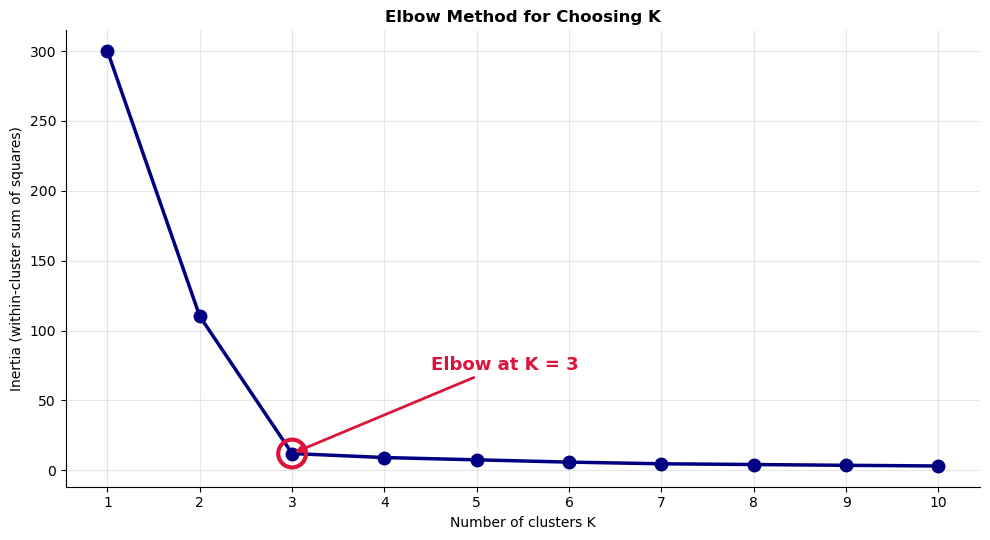

In [33]:
k_values = range(1, 11)
inertias = []
for k in k_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertias.append(km.inertia_)

print(pd.DataFrame({'K': list(k_values), 'Inertia': np.round(inertias, 2),
                    'Reduction from previous K': np.round([np.nan] + list(-np.diff(inertias)), 2)}).to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(list(k_values), inertias, marker='o', markersize=9, lw=2.5, color='navy')
ax.scatter(3, inertias[2], s=400, facecolor='none', edgecolor='crimson', linewidths=3, zorder=5)
ax.annotate('Elbow at K = 3', (3, inertias[2]), xytext=(4.5, inertias[2] + 60),
            arrowprops=dict(arrowstyle='->', color='crimson', lw=2), fontsize=13, color='crimson', fontweight='bold')
ax.set_xticks(list(k_values))
ax.set_xlabel('Number of clusters K')
ax.set_ylabel('Inertia (within-cluster sum of squares)')
ax.set_title('Elbow Method for Choosing K')
plt.tight_layout()
plt.show()

## 4.6 Training the final model (K = 3)

In [34]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans.fit(X_scaled)

df_clust['Cluster'] = kmeans.labels_
print('Number of points in each cluster:')
print(df_clust['Cluster'].value_counts().sort_index())
print()
print(f'Final inertia: {kmeans.inertia_:.4f}')
print(f'Iterations needed to converge: {kmeans.n_iter_}')
print()
print('Check against the hidden true groups (rows = true group, columns = cluster found):')
print(pd.crosstab(true_group, df_clust['Cluster'], rownames=['True group'], colnames=['Cluster']))
print('Each true group maps to exactly one cluster. Cluster numbers are arbitrary, so only the grouping matters.')

Number of points in each cluster:
Cluster
0    50
1    50
2    50
Name: count, dtype: int64

Final inertia: 12.0539
Iterations needed to converge: 2

Check against the hidden true groups (rows = true group, columns = cluster found):
Cluster      0   1   2
True group            
0            0   0  50
1           50   0   0
2            0  50   0
Each true group maps to exactly one cluster. Cluster numbers are arbitrary, so only the grouping matters.


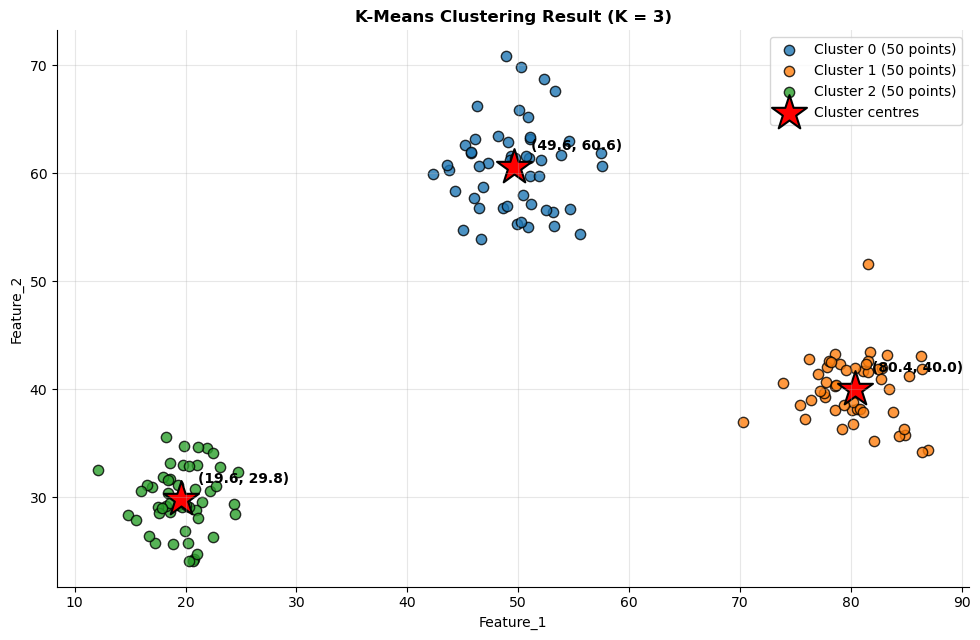

Cluster centres in original units:
   Feature_1  Feature_2
0      49.62      60.56
1      80.39      40.00
2      19.59      29.78
The true centres used to generate the data were (20, 30), (50, 60) and (80, 40).


In [35]:
centers_original = scaler_km.inverse_transform(kmeans.cluster_centers_)   # back to original units for plotting

fig, ax = plt.subplots(figsize=(10, 6.5))
colors = ['tab:blue', 'tab:orange', 'tab:green']
for k in range(3):
    subset = df_clust[df_clust['Cluster'] == k]
    ax.scatter(subset['Feature_1'], subset['Feature_2'], color=colors[k], edgecolor='black', s=55, alpha=0.8,
               label=f'Cluster {k} ({len(subset)} points)')
ax.scatter(centers_original[:, 0], centers_original[:, 1], marker='*', s=700, color='red', edgecolor='black',
           linewidths=1.5, label='Cluster centres')
for k, (cx, cy) in enumerate(centers_original):
    ax.annotate(f'({cx:.1f}, {cy:.1f})', (cx, cy), xytext=(12, 12), textcoords='offset points', fontweight='bold')
ax.set_xlabel('Feature_1')
ax.set_ylabel('Feature_2')
ax.set_title('K-Means Clustering Result (K = 3)')
ax.legend()
plt.tight_layout()
plt.show()

print('Cluster centres in original units:')
print(pd.DataFrame(centers_original, columns=['Feature_1', 'Feature_2']).round(2))
print('The true centres used to generate the data were (20, 30), (50, 60) and (80, 40).')

## 4.7 Silhouette score

Inertia only measures how tight clusters are. The **silhouette score** also measures how well separated they are. For each point $i$:

- $a(i)$ = average distance from $i$ to the other points in **its own** cluster (cohesion)
- $b(i)$ = average distance from $i$ to the points in the **nearest other** cluster (separation)

$$s(i) = \frac{b(i) - a(i)}{\max\big(a(i),\, b(i)\big)}$$

The overall silhouette score is the average of $s(i)$ over all points.

| Score | Meaning |
|---|---|
| Close to +1 | Point is far from other clusters and close to its own: well clustered |
| Around 0 | Point lies on the border between two clusters |
| Negative | Point is probably in the wrong cluster |

### Worked example
A point has an average distance of 2 to its own cluster ($a = 2$) and 10 to the nearest other cluster ($b = 10$). Then $s = (10 - 2) / 10 = 0.8$, a well-clustered point.

Silhouette score for K = 3: 0.8361
Interpretation: strong structure. Clusters are compact and clearly separated.


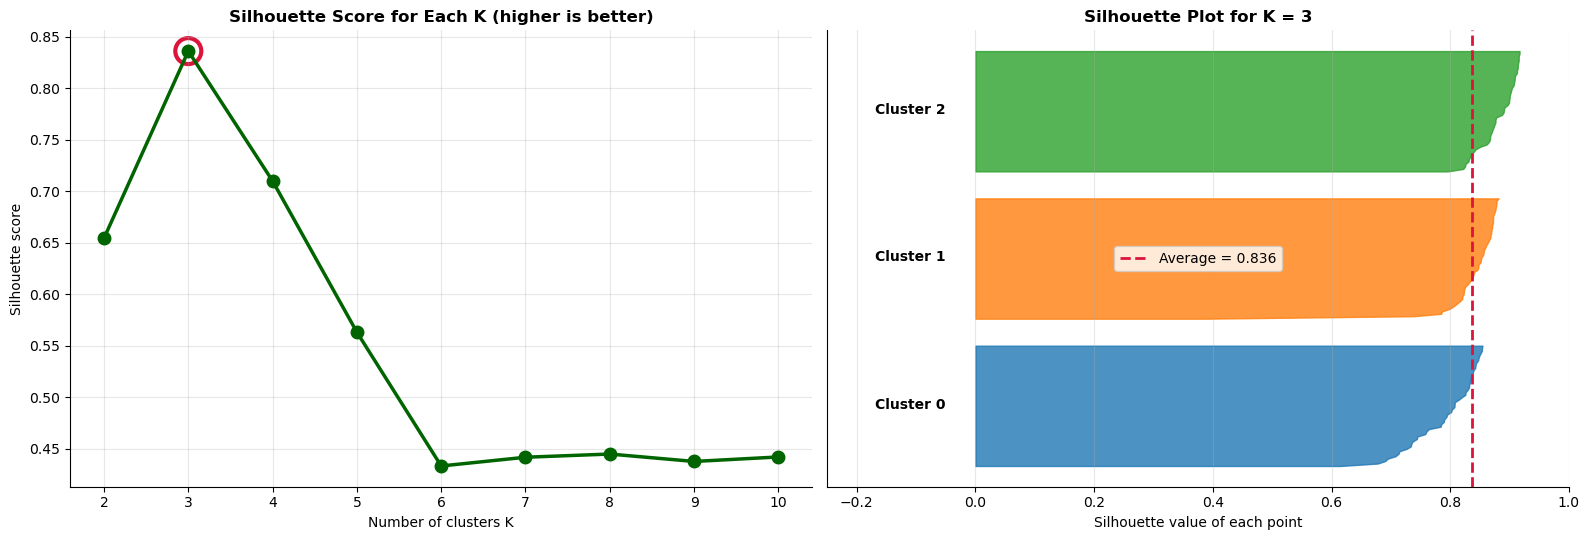

In the silhouette plot, every horizontal bar is one point. All three clusters have bars well above zero.
Lowest individual silhouette value: 0.387; number of negative values: 0.


In [36]:
sil = silhouette_score(X_scaled, kmeans.labels_)
print(f'Silhouette score for K = 3: {sil:.4f}')
if sil > 0.7:
    print('Interpretation: strong structure. Clusters are compact and clearly separated.')
elif sil > 0.5:
    print('Interpretation: reasonable structure.')
else:
    print('Interpretation: weak or overlapping structure.')

sil_by_k = {k: silhouette_score(X_scaled, KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X_scaled))
            for k in range(2, 11)}
sample_sil = silhouette_samples(X_scaled, kmeans.labels_)

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

ax = axes[0]
ax.plot(list(sil_by_k.keys()), list(sil_by_k.values()), marker='o', markersize=9, lw=2.5, color='darkgreen')
ax.scatter(3, sil_by_k[3], s=350, facecolor='none', edgecolor='crimson', linewidths=3)
ax.set_xlabel('Number of clusters K')
ax.set_ylabel('Silhouette score')
ax.set_title('Silhouette Score for Each K (higher is better)')

ax = axes[1]
y_lower = 10
for k in range(3):
    values = np.sort(sample_sil[kmeans.labels_ == k])
    y_upper = y_lower + len(values)
    ax.fill_betweenx(np.arange(y_lower, y_upper), 0, values, color=colors[k], alpha=0.8)
    ax.text(-0.05, y_lower + len(values) / 2, f'Cluster {k}', ha='right', va='center', fontweight='bold')
    y_lower = y_upper + 10
ax.axvline(sil, color='crimson', ls='--', lw=2, label=f'Average = {sil:.3f}')
ax.set_xlim(-0.25, 1)
ax.set_yticks([])
ax.set_xlabel('Silhouette value of each point')
ax.set_title('Silhouette Plot for K = 3')
ax.legend()

plt.tight_layout()
plt.show()
print('In the silhouette plot, every horizontal bar is one point. All three clusters have bars well above zero.')
print(f'Lowest individual silhouette value: {sample_sil.min():.3f}; number of negative values: {int((sample_sil < 0).sum())}.')

## 4.8 Discussion

**How is the Elbow Method used to choose K?**
K-Means is run for a range of K values, and the inertia of each result is plotted against K. The chosen K is the point where the curve bends sharply and further increases in K produce only small reductions in inertia, because beyond that point additional clusters merely split genuine groups rather than capturing new structure.

**Why does K-Means require feature scaling?**
K-Means assigns points to the nearest centroid using Euclidean distance, so a feature with a large numeric range dominates the distance and effectively decides every assignment on its own. Scaling gives each feature an equal opportunity to influence which cluster a point belongs to.

---
# 5. Principal Component Analysis (Dimensionality Reduction)

## 5.1 Concept

Real datasets often have many features, and many of them carry overlapping information. Height and weight, for example, rise together; knowing one tells a lot about the other. PCA creates a **smaller set of new features**, called **principal components**, that capture most of the information in the original features.

**Analogy.** A shadow is a two-dimensional picture of a three-dimensional object. If the light is positioned well, the shadow still shows the object's shape clearly. PCA finds the best "angle of light" so that the lower-dimensional picture preserves as much of the data's spread as possible.

In PCA, **information is measured as variance** (spread). A direction in which the data varies a lot is informative; a direction in which all points are nearly identical carries little information.

## 5.2 How PCA works

1. **Standardise** each feature to mean 0 and standard deviation 1.
2. **Compute the covariance matrix**, which records how every pair of features varies together.
3. **Find the eigenvectors and eigenvalues** of that matrix.
   - Each **eigenvector** is a direction in feature space: a principal component.
   - Its **eigenvalue** is the amount of variance along that direction.
4. **Sort** components by eigenvalue, from largest to smallest.
5. **Project** the data onto the top $k$ components to obtain the reduced dataset.

Key properties:
- **PC1** is the direction of maximum variance. **PC2** is the direction of maximum remaining variance that is perpendicular to PC1, and so on.
- Components are **uncorrelated** with each other.
- Each component is a **weighted combination** of the original features. The weights are called **loadings** and are stored in `components_`.

$$\text{Explained variance ratio of PC}_j = \frac{\lambda_j}{\sum_{i} \lambda_i}$$

### Worked example
With 8 standardised features, the total variance is 8 (each contributes 1). If PC1 has eigenvalue $\lambda_1 = 2.0$, it explains $2.0 / 8 = 25\%$ of the total variance, the same information as two whole original features.

### Why scaling is mandatory
Without scaling, Income (standard deviation around 15,000) would have a variance millions of times larger than Age. PC1 would simply point along Income, and PCA would discover nothing except which feature uses the largest units.

In [37]:
from sklearn.decomposition import PCA

np.random.seed(42)
n = 200
df_pca = pd.DataFrame({
    'Height': np.random.normal(170, 10, n),
    'Weight': np.random.normal(70, 15, n),
    'Age': np.random.randint(18, 60, n),
    'Income': np.random.normal(50000, 15000, n),
    'Experience': np.random.randint(1, 20, n),
    'Score_A': np.random.normal(75, 10, n),
    'Score_B': np.random.normal(80, 12, n),
    'Score_C': np.random.normal(70, 8, n)
})
df_pca['Weight'] = df_pca['Height'] * 0.5 + np.random.normal(0, 5, n)
df_pca['Score_B'] = df_pca['Score_A'] * 0.8 + np.random.normal(0, 5, n)

print(df_pca.describe().round(2))

       Height  Weight     Age    Income  Experience  Score_A  Score_B  Score_C
count  200.00  200.00  200.00    200.00      200.00   200.00   200.00   200.00
mean   169.59   85.13   37.74  51427.69       10.20    76.60    61.42    70.38
std      9.31    7.15   12.14  16743.10        5.31     9.61     9.01     7.79
min    143.80   67.00   18.00  -3523.08        1.00    50.76    38.28    49.27
25%    162.95   80.68   27.00  40627.26        6.00    69.61    55.72    65.03
50%    169.96   85.11   38.00  52314.04       10.50    76.95    61.78    70.56
75%    175.01   89.82   48.00  62130.55       15.00    82.50    67.66    75.33
max    197.20  110.45   59.00  97616.63       19.00   100.27    84.66    89.94


### Correlation between features

The dataset was built with two correlated pairs: **Height-Weight** and **Score_A-Score_B**. All other features are independent. The heatmap confirms this. Correlated pairs are exactly the redundancy PCA can compress.

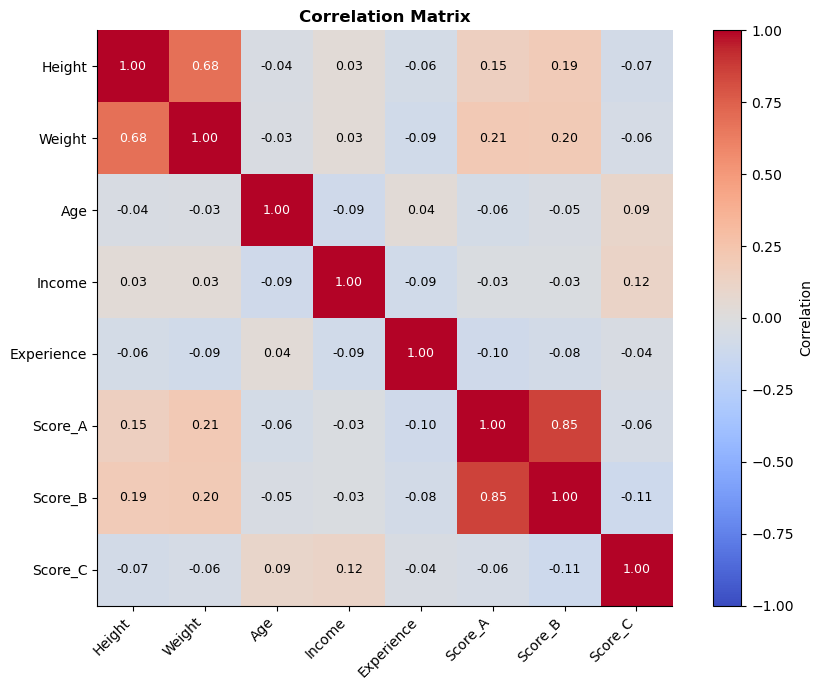

In [38]:
corr = df_pca.corr()
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=45, ha='right')
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
ax.grid(False)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=9,
                color='white' if abs(corr.iloc[i, j]) > 0.5 else 'black')
plt.colorbar(im, label='Correlation')
ax.set_title('Correlation Matrix')
plt.tight_layout()
plt.show()

### Visual intuition with two features

Using only Height and Weight (standardised), PCA finds two perpendicular directions. PC1 (red) runs along the long axis of the cloud, where the data spreads the most. PC2 (blue) runs across it. The right panel projects every point onto PC1 alone: one number per person that still captures most of the variation in both height and weight.

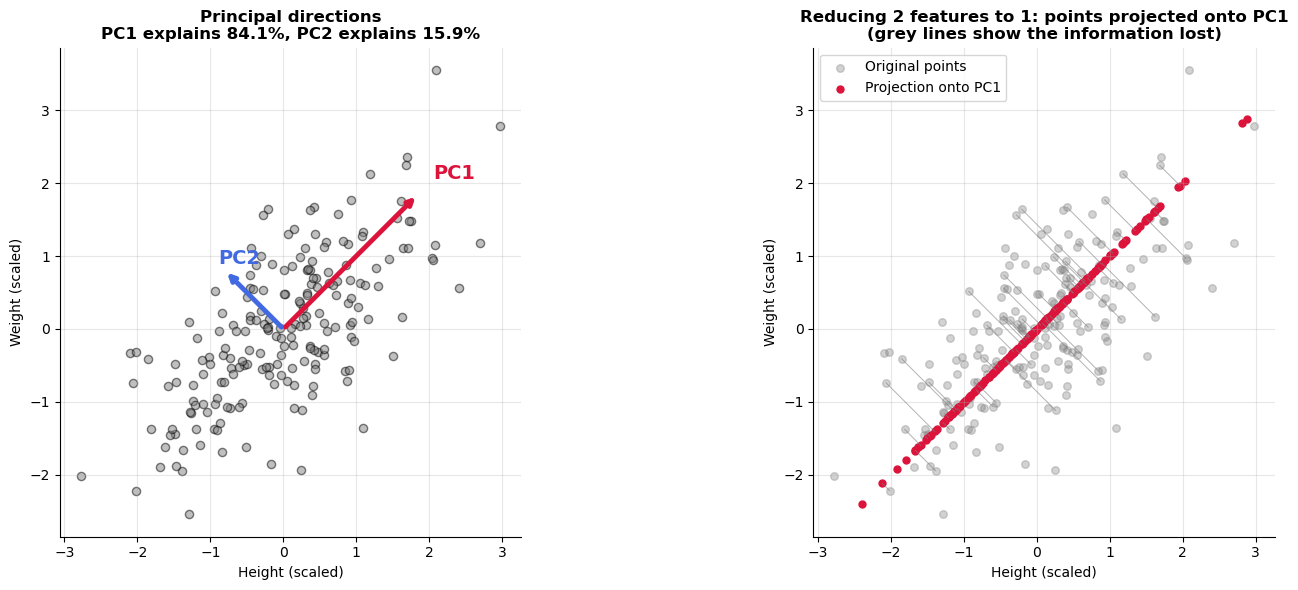

In [39]:
hw = StandardScaler().fit_transform(df_pca[['Height', 'Weight']])
pca_hw = PCA(n_components=2).fit(hw)
center = hw.mean(axis=0)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
ax = axes[0]
ax.scatter(hw[:, 0], hw[:, 1], color='gray', alpha=0.5, edgecolor='black', s=35)
for comp, var, col, name in zip(pca_hw.components_, pca_hw.explained_variance_, ['crimson', 'royalblue'], ['PC1', 'PC2']):
    vec = comp * 2 * np.sqrt(var)
    ax.annotate('', xy=center + vec, xytext=center, arrowprops=dict(arrowstyle='->', lw=3.5, color=col))
    ax.text(*(center + vec * 1.12), name, color=col, fontsize=14, fontweight='bold')
ax.set_aspect('equal')
ax.set_xlabel('Height (scaled)'); ax.set_ylabel('Weight (scaled)')
ax.set_title(f'Principal directions\nPC1 explains {pca_hw.explained_variance_ratio_[0]:.1%}, '
             f'PC2 explains {pca_hw.explained_variance_ratio_[1]:.1%}')

ax = axes[1]
proj = pca_hw.transform(hw)
recon = pca_hw.inverse_transform(np.c_[proj[:, 0], np.zeros(len(proj))])
for p, r in zip(hw[:60], recon[:60]):
    ax.plot([p[0], r[0]], [p[1], r[1]], color='gray', lw=0.7, alpha=0.6)
ax.scatter(hw[:, 0], hw[:, 1], color='gray', alpha=0.35, s=30, label='Original points')
ax.scatter(recon[:, 0], recon[:, 1], color='crimson', s=25, label='Projection onto PC1')
ax.set_aspect('equal')
ax.set_xlabel('Height (scaled)'); ax.set_ylabel('Weight (scaled)')
ax.set_title('Reducing 2 features to 1: points projected onto PC1\n(grey lines show the information lost)')
ax.legend()
plt.tight_layout()
plt.show()

## 5.3 Scaling all features

In [40]:
scaler_pca = StandardScaler()
X_pca_scaled = scaler_pca.fit_transform(df_pca)
print('Shape:', X_pca_scaled.shape)
print('Means:', X_pca_scaled.mean(axis=0).round(4))
print('Stds :', X_pca_scaled.std(axis=0).round(4))
print('Total variance of the scaled data (sum of 8 unit variances):', X_pca_scaled.var(axis=0).sum().round(4))

Shape: (200, 8)
Means: [ 0. -0. -0. -0. -0. -0.  0.  0.]
Stds : [1. 1. 1. 1. 1. 1. 1. 1.]
Total variance of the scaled data (sum of 8 unit variances): 8.0


## 5.4 PCA with 2 components

In [41]:
pca2 = PCA(n_components=2)
X_pc2 = pca2.fit_transform(X_pca_scaled)

print('Reduced data shape:', X_pc2.shape, '(8 features compressed into 2)')
print()
for i, ratio in enumerate(pca2.explained_variance_ratio_, start=1):
    print(f'PC{i} explained variance ratio: {ratio:.4f}  ({ratio:.2%})')
print(f'Total variance kept by 2 components: {pca2.explained_variance_ratio_.sum():.2%}')

Reduced data shape: (200, 2) (8 features compressed into 2)

PC1 explained variance ratio: 0.2755  (27.55%)
PC2 explained variance ratio: 0.1743  (17.43%)
Total variance kept by 2 components: 44.98%


## 5.5 Cumulative explained variance: how many components reach 90%?

A PCA with all 8 components is fitted so the variance of every component is available. The **cumulative** sum shows how much total variance is retained when keeping the first $k$ components.

Component  Eigenvalue  Explained ratio  Cumulative
      PC1      2.2154           0.2755      0.2755
      PC2      1.4015           0.1743      0.4498
      PC3      1.1734           0.1459      0.5958
      PC4      1.0716           0.1333      0.7291
      PC5      0.9182           0.1142      0.8433
      PC6      0.7970           0.0991      0.9424
      PC7      0.3197           0.0398      0.9822
      PC8      0.1434           0.0178      1.0000

Components needed to explain at least 90% of the variance: 6
Only two correlated pairs exist; the other four features are independent and each carries unique
information, so the variance is spread across many components and cannot be compressed into very few.

Manual eigenvalues of the covariance matrix: [2.2154 1.4015 1.1734 1.0716 0.9182 0.797  0.3197 0.1434]
Match PCA explained_variance_           : True


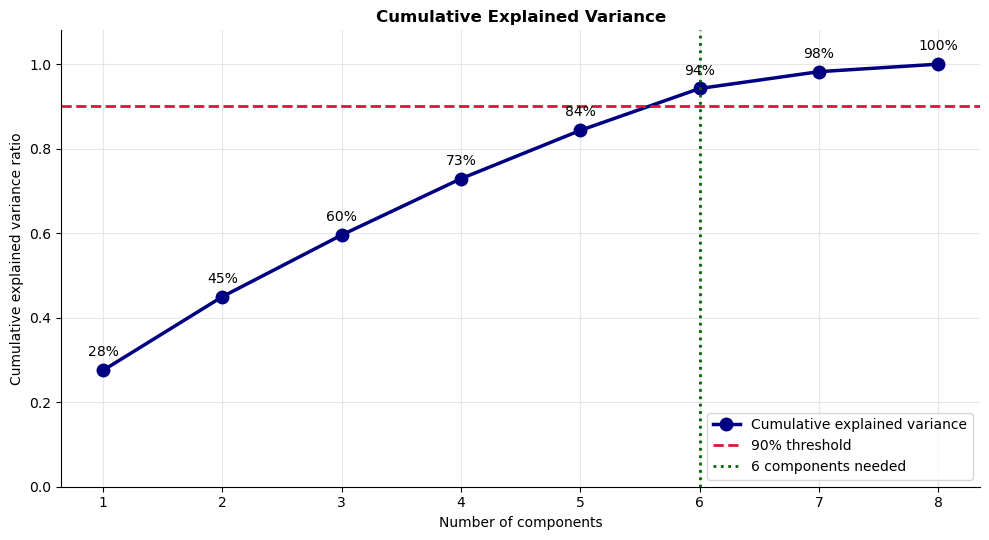

In [42]:
pca_full = PCA()
pca_full.fit(X_pca_scaled)

ratios = pca_full.explained_variance_ratio_
cumulative = np.cumsum(ratios)
n_90 = int(np.argmax(cumulative >= 0.90) + 1)

print(pd.DataFrame({
    'Component': [f'PC{i}' for i in range(1, 9)],
    'Eigenvalue': pca_full.explained_variance_.round(4),
    'Explained ratio': ratios.round(4),
    'Cumulative': cumulative.round(4),
}).to_string(index=False))
print()
print(f'Components needed to explain at least 90% of the variance: {n_90}')
print('Only two correlated pairs exist; the other four features are independent and each carries unique')
print('information, so the variance is spread across many components and cannot be compressed into very few.')

# Verify against a manual eigen-decomposition of the covariance matrix
cov = np.cov(X_pca_scaled, rowvar=False)
eigenvalues = np.sort(np.linalg.eigvalsh(cov))[::-1]
print()
print('Manual eigenvalues of the covariance matrix:', eigenvalues.round(4))
print('Match PCA explained_variance_           :', np.allclose(eigenvalues, pca_full.explained_variance_))

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(range(1, 9), cumulative, marker='o', markersize=9, lw=2.5, color='navy', label='Cumulative explained variance')
ax.axhline(0.90, color='crimson', ls='--', lw=2, label='90% threshold')
ax.axvline(n_90, color='darkgreen', ls=':', lw=2, label=f'{n_90} components needed')
for i, c in enumerate(cumulative, start=1):
    ax.annotate(f'{c:.0%}', (i, c), xytext=(0, 10), textcoords='offset points', ha='center')
ax.set_xticks(range(1, 9))
ax.set_ylim(0, 1.08)
ax.set_xlabel('Number of components')
ax.set_ylabel('Cumulative explained variance ratio')
ax.set_title('Cumulative Explained Variance')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

## 5.6 Scatter plot of PC1 versus PC2, coloured by age group

`pd.cut` converts a continuous column into categories by specifying bin edges. Ages are grouped as Young (18 to 30), Middle (31 to 45) and Senior (46 to 59).

Age_Group
Young     63
Middle    76
Senior    61
Name: count, dtype: int64


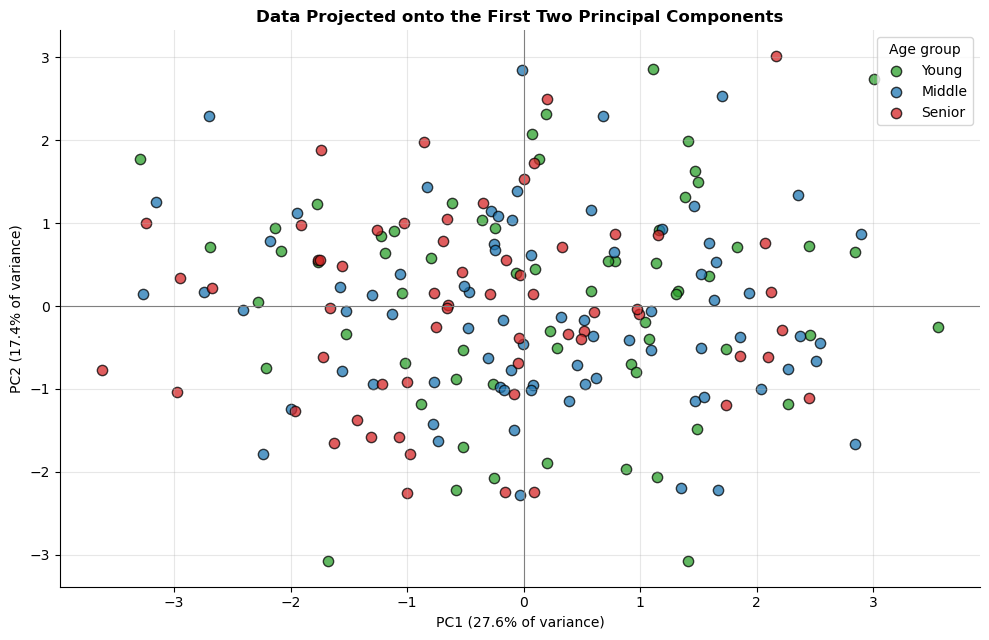

The age groups overlap completely. Age is independent of the correlated pairs that drive PC1 and PC2,
so these two components do not separate people by age.


In [43]:
df_pca['Age_Group'] = pd.cut(df_pca['Age'], bins=[17, 30, 45, 60], labels=['Young', 'Middle', 'Senior'])
print(df_pca['Age_Group'].value_counts().sort_index())

fig, ax = plt.subplots(figsize=(10, 6.5))
group_colors = {'Young': 'tab:green', 'Middle': 'tab:blue', 'Senior': 'tab:red'}
for group, color in group_colors.items():
    mask = (df_pca['Age_Group'] == group).values
    ax.scatter(X_pc2[mask, 0], X_pc2[mask, 1], color=color, edgecolor='black', s=55, alpha=0.75, label=group)
ax.axhline(0, color='gray', lw=0.8); ax.axvline(0, color='gray', lw=0.8)
ax.set_xlabel(f'PC1 ({pca2.explained_variance_ratio_[0]:.1%} of variance)')
ax.set_ylabel(f'PC2 ({pca2.explained_variance_ratio_[1]:.1%} of variance)')
ax.set_title('Data Projected onto the First Two Principal Components')
ax.legend(title='Age group')
plt.tight_layout()
plt.show()
print('The age groups overlap completely. Age is independent of the correlated pairs that drive PC1 and PC2,')
print('so these two components do not separate people by age.')

## 5.7 The components (loadings) matrix

`components_` has one row per principal component and one column per original feature. Each value is the weight of that feature in the component. A large **absolute** value means the feature contributes strongly; the sign only indicates direction.

PCA components_ matrix (loadings):
     Height  Weight     Age  Income  Experience  Score_A  Score_B  Score_C
PC1  0.4234  0.4421 -0.0893  0.0044     -0.1318   0.5359   0.5447  -0.1263
PC2  0.5488  0.5263 -0.0138  0.1894     -0.0720  -0.4397  -0.4282   0.0616

PC1: strongest contributors -> Score_B (+0.545), Score_A (+0.536)
PC2: strongest contributors -> Height (+0.549), Weight (+0.526)


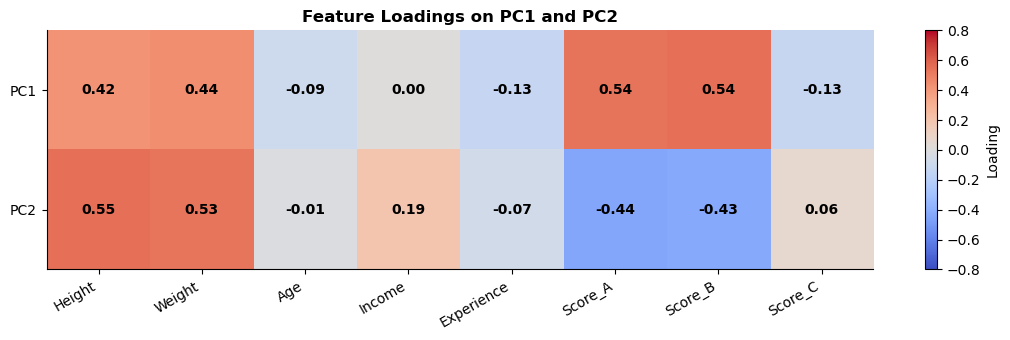

Each of the first two components is dominated by one correlated pair, which is exactly the redundancy built into the data.


In [44]:
loadings = pd.DataFrame(pca2.components_, columns=df_pca.columns[:8], index=['PC1', 'PC2'])
print('PCA components_ matrix (loadings):')
print(loadings.round(4))
print()
for pc in loadings.index:
    top = loadings.loc[pc].abs().sort_values(ascending=False)
    print(f'{pc}: strongest contributors -> {top.index[0]} ({loadings.loc[pc, top.index[0]]:+.3f}), '
          f'{top.index[1]} ({loadings.loc[pc, top.index[1]]:+.3f})')

fig, ax = plt.subplots(figsize=(11, 3.5))
im = ax.imshow(loadings, cmap='coolwarm', vmin=-0.8, vmax=0.8, aspect='auto')
ax.set_xticks(range(8)); ax.set_xticklabels(loadings.columns, rotation=30, ha='right')
ax.set_yticks(range(2)); ax.set_yticklabels(loadings.index)
ax.grid(False)
for i in range(2):
    for j in range(8):
        ax.text(j, i, f'{loadings.iloc[i, j]:.2f}', ha='center', va='center', fontweight='bold')
plt.colorbar(im, label='Loading')
ax.set_title('Feature Loadings on PC1 and PC2')
plt.tight_layout()
plt.show()
print('Each of the first two components is dominated by one correlated pair, which is exactly the redundancy built into the data.')

## 5.8 Explained variance for all 8 components

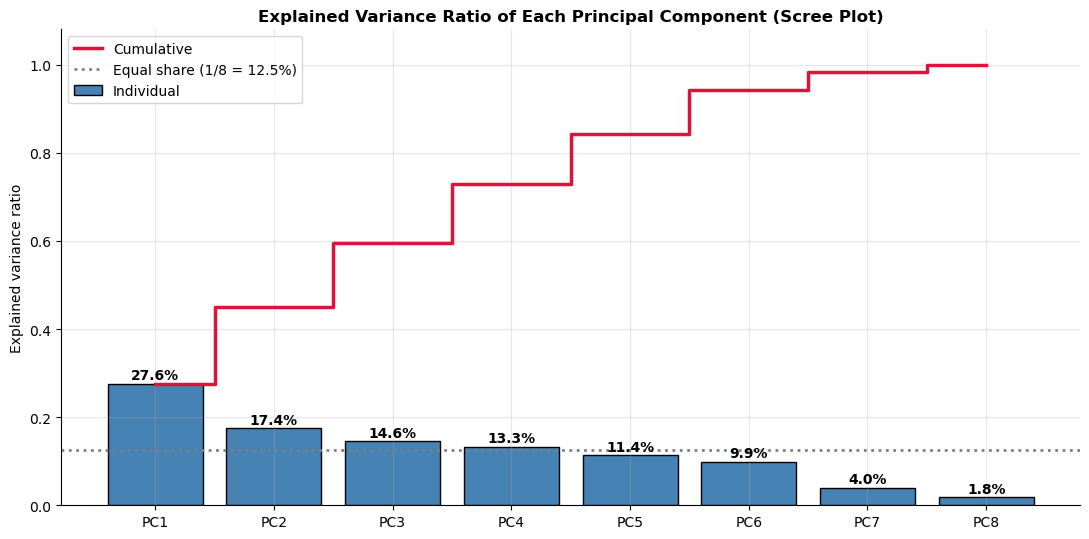

The last two components explain very little variance. They correspond to the small, independent noise
within the correlated pairs, and dropping them loses almost no information.


In [45]:
fig, ax = plt.subplots(figsize=(11, 5.5))
bars = ax.bar([f'PC{i}' for i in range(1, 9)], ratios, color='steelblue', edgecolor='black', label='Individual')
ax.step(range(8), cumulative, where='mid', color='crimson', lw=2.5, label='Cumulative')
ax.axhline(1 / 8, color='gray', ls=':', lw=2, label='Equal share (1/8 = 12.5%)')
for bar, r in zip(bars, ratios):
    ax.text(bar.get_x() + bar.get_width() / 2, r + 0.01, f'{r:.1%}', ha='center', fontweight='bold')
ax.set_ylabel('Explained variance ratio')
ax.set_title('Explained Variance Ratio of Each Principal Component (Scree Plot)')
ax.set_ylim(0, 1.08)
ax.legend()
plt.tight_layout()
plt.show()
print('The last two components explain very little variance. They correspond to the small, independent noise')
print('within the correlated pairs, and dropping them loses almost no information.')

## 5.9 Discussion

**Why is PCA useful during EDA?**
PCA compresses many features into two or three components that can be plotted, making it possible to see clusters, outliers and overall structure in data that would otherwise be impossible to visualise. Its loadings also reveal which features move together, exposing redundancy in the dataset.

**What is lost and what is gained?**
Dimensionality reduction discards the variance contained in the dropped components, and the new components are combinations of features rather than directly interpretable measurements such as "Height". In return, the data becomes smaller, less redundant and less noisy, which speeds up training, reduces the risk of overfitting and enables visualisation.

---
# 6. Decision Tree Classifier

## 6.1 Concept

A decision tree makes predictions by asking a sequence of yes/no questions about the features, exactly like a flowchart.

```
                 Is Credit_Score <= 549.5 ?
                 /                        \
               yes                         no
               /                            \
         Risk = High              Is Employment = Unemployed ?
                                     /                 \
                                   yes                  no
                                   /                     \
                             Risk = High          Is Income <= 35,000 ?
                                                      ...
```

Vocabulary:
- **Root node**: the first question, applied to all data.
- **Internal node**: a question partway down the tree.
- **Branch**: the path taken for a yes or no answer.
- **Leaf node**: an end point that gives the prediction (the majority class of the training samples that reach it).
- **Depth**: the number of questions from the root to the deepest leaf.

## 6.2 How the tree chooses its questions

At each node, the tree tries **every feature** and **every possible threshold**, and chooses the split that makes the resulting groups as **pure** as possible. A pure group contains only one class.

### Gini impurity
$$\text{Gini} = 1 - \sum_{k} p_k^2$$

where $p_k$ is the proportion of class $k$ in the node. Gini is 0 for a perfectly pure node and 0.5 for a 50/50 two-class node, the most mixed case.

### Entropy (the alternative criterion)
$$\text{Entropy} = -\sum_{k} p_k \log_2 p_k$$

Entropy is 0 for a pure node and 1 for a 50/50 two-class node. In practice, Gini and entropy usually produce very similar trees. Scikit-learn uses Gini by default.

### Worked example
A node contains 10 customers: 6 High risk and 4 Low risk.

$$\text{Gini}_{parent} = 1 - (0.6^2 + 0.4^2) = 1 - (0.36 + 0.16) = 0.48$$

Candidate split: "Credit_Score <= 550".
- Left child: 5 High, 0 Low. $\text{Gini} = 1 - (1^2 + 0^2) = 0$ (pure)
- Right child: 1 High, 4 Low. $\text{Gini} = 1 - (0.2^2 + 0.8^2) = 0.32$

Weighted Gini after the split, weighting each child by its share of samples:
$$\text{Gini}_{split} = \tfrac{5}{10}(0) + \tfrac{5}{10}(0.32) = 0.16$$

**Impurity decrease** = 0.48 - 0.16 = **0.32**. The tree computes this for every possible split and picks the one with the largest decrease. It then repeats the process inside each child until a stopping rule is met, such as `max_depth`.

### Feature importance
A feature's importance is the **total impurity decrease** it produced across all splits in the tree, weighted by the number of samples reaching those splits and normalised so that all importances sum to 1.

Gini of parent node      : 0.4800
Gini of left child       : 0.0000
Gini of right child      : 0.3200
Weighted Gini after split: 0.1600
Impurity decrease        : 0.3200


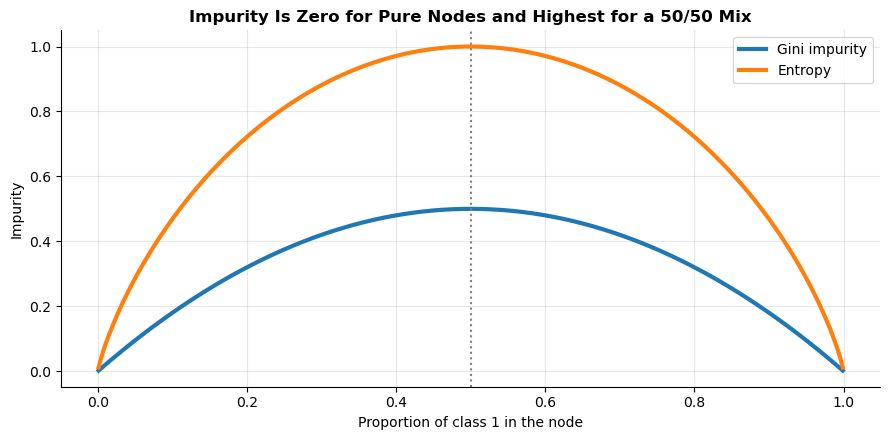

In [46]:
def gini(counts):
    p = np.array(counts) / np.sum(counts)
    return 1 - np.sum(p ** 2)

parent = gini([6, 4])
left, right = gini([5, 0]), gini([1, 4])
weighted = 5 / 10 * left + 5 / 10 * right
print(f'Gini of parent node      : {parent:.4f}')
print(f'Gini of left child       : {left:.4f}')
print(f'Gini of right child      : {right:.4f}')
print(f'Weighted Gini after split: {weighted:.4f}')
print(f'Impurity decrease        : {parent - weighted:.4f}')

p = np.linspace(0.001, 0.999, 300)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(p, 1 - (p ** 2 + (1 - p) ** 2), lw=3, label='Gini impurity')
ax.plot(p, -(p * np.log2(p) + (1 - p) * np.log2(1 - p)), lw=3, label='Entropy')
ax.axvline(0.5, color='gray', ls=':', lw=1.5)
ax.set_xlabel('Proportion of class 1 in the node')
ax.set_ylabel('Impurity')
ax.set_title('Impurity Is Zero for Pure Nodes and Highest for a 50/50 Mix')
ax.legend()
plt.tight_layout()
plt.show()

## 6.3 The dataset

A customer is **High** risk if the credit score is below 550, **or** income is below 35,000, **or** the customer is unemployed. Otherwise the customer is **Low** risk.

In [47]:
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.preprocessing import LabelEncoder

np.random.seed(42)
n = 250
df_tree = pd.DataFrame({
    'Age': np.random.randint(18, 65, n),
    'Income': np.random.normal(50000, 15000, n),
    'Credit_Score': np.random.randint(300, 850, n),
    'Employment': np.random.choice(['Employed', 'Self-Employed', 'Unemployed'], n)
})
df_tree['Risk'] = np.where(
    (df_tree['Credit_Score'] < 550) | (df_tree['Income'] < 35000) | (df_tree['Employment'] == 'Unemployed'),
    'High', 'Low'
)
print(df_tree.head())
print()
print(df_tree['Risk'].value_counts())

   Age        Income  Credit_Score     Employment  Risk
0   56  38251.200615           340       Employed  High
1   46  45169.077257           801     Unemployed  High
2   32  62202.758261           444     Unemployed  High
3   60  31537.035253           500  Self-Employed  High
4   25  53411.899019           760  Self-Employed   Low

Risk
High    179
Low      71
Name: count, dtype: int64


## 6.4 Encoding the Employment feature and the Risk target

LabelEncoder is used for `Employment` as the assignment specifies. For a decision tree this is acceptable even though the column has three categories: a tree never multiplies the code by a coefficient, it only asks threshold questions. A split such as `Employment_encoded <= 1.5` cleanly separates Unemployed (code 2) from the other two groups. For linear models, one-hot encoding would be required instead.

In [48]:
le_emp = LabelEncoder()
df_tree['Employment_encoded'] = le_emp.fit_transform(df_tree['Employment'])
print('Employment mapping:', {c: int(i) for c, i in zip(le_emp.classes_, le_emp.transform(le_emp.classes_))})

feature_names = ['Age', 'Income', 'Credit_Score', 'Employment_encoded']
X = df_tree[feature_names]

le_risk = LabelEncoder()
y = le_risk.fit_transform(df_tree['Risk'])
print('Risk mapping      :', {c: int(i) for c, i in zip(le_risk.classes_, le_risk.transform(le_risk.classes_))})

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print()
print(f'Training rows: {len(X_train)}   Test rows: {len(X_test)}')
X.head()

Employment mapping: {'Employed': 0, 'Self-Employed': 1, 'Unemployed': 2}
Risk mapping      : {'High': 0, 'Low': 1}

Training rows: 200   Test rows: 50


,Age,Income,Credit_Score,Employment_encoded
0,56,38251.200615,340,0
1,46,45169.077257,801,2
2,32,62202.758261,444,2
3,60,31537.035253,500,1
4,25,53411.899019,760,1


## 6.5 Training the tree (max_depth = 4) and feature importances

Scaling is **not** needed for decision trees, because a split threshold works the same regardless of the feature's units.

Feature importances:
Employment_encoded    0.4812
Credit_Score          0.3584
Income                0.1603
Age                   0.0000
dtype: float64

Sum of importances: 1.00
Tree depth: 3   Number of leaves: 4


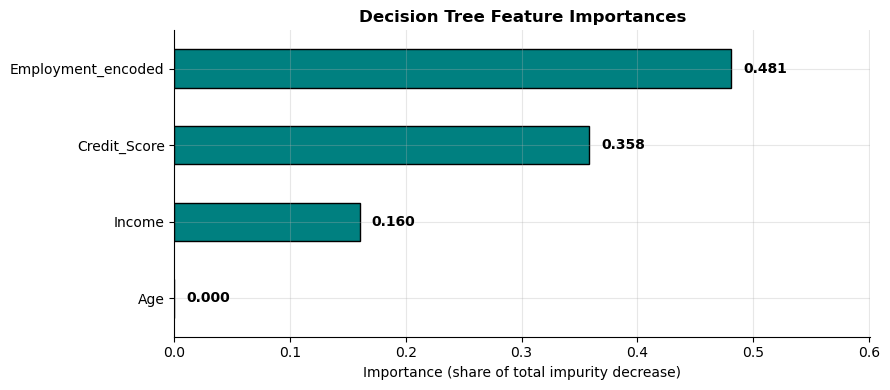

Age has zero or near-zero importance, which is correct: it plays no role in the rule that defines Risk.


In [49]:
tree_model = DecisionTreeClassifier(max_depth=4, random_state=42)
tree_model.fit(X_train, y_train)

importances = pd.Series(tree_model.feature_importances_, index=feature_names).sort_values(ascending=False)
print('Feature importances:')
print(importances.round(4))
print()
print(f'Sum of importances: {importances.sum():.2f}')
print(f'Tree depth: {tree_model.get_depth()}   Number of leaves: {tree_model.get_n_leaves()}')

fig, ax = plt.subplots(figsize=(9, 4))
importances.sort_values().plot.barh(ax=ax, color='teal', edgecolor='black')
for i, v in enumerate(importances.sort_values()):
    ax.text(v + 0.01, i, f'{v:.3f}', va='center', fontweight='bold')
ax.set_xlabel('Importance (share of total impurity decrease)')
ax.set_title('Decision Tree Feature Importances')
ax.set_xlim(0, importances.max() + 0.12)
plt.tight_layout()
plt.show()
print('Age has zero or near-zero importance, which is correct: it plays no role in the rule that defines Risk.')

## 6.6 Visualising the tree

### How to read each box
| Line in the box | Meaning |
|---|---|
| `Credit_Score <= 549.5` | The question asked. **True goes left**, False goes right. (Leaves have no question.) |
| `gini = 0.42` | Impurity of the samples at this node |
| `samples = 200` | Number of training samples reaching this node |
| `value = [140, 60]` | Count of each class at this node, in the order [High, Low] |
| `class = High` | The majority class, which is the prediction if this were a leaf |

With `filled=True`, the box colour shows the majority class, and a deeper shade means a purer node.

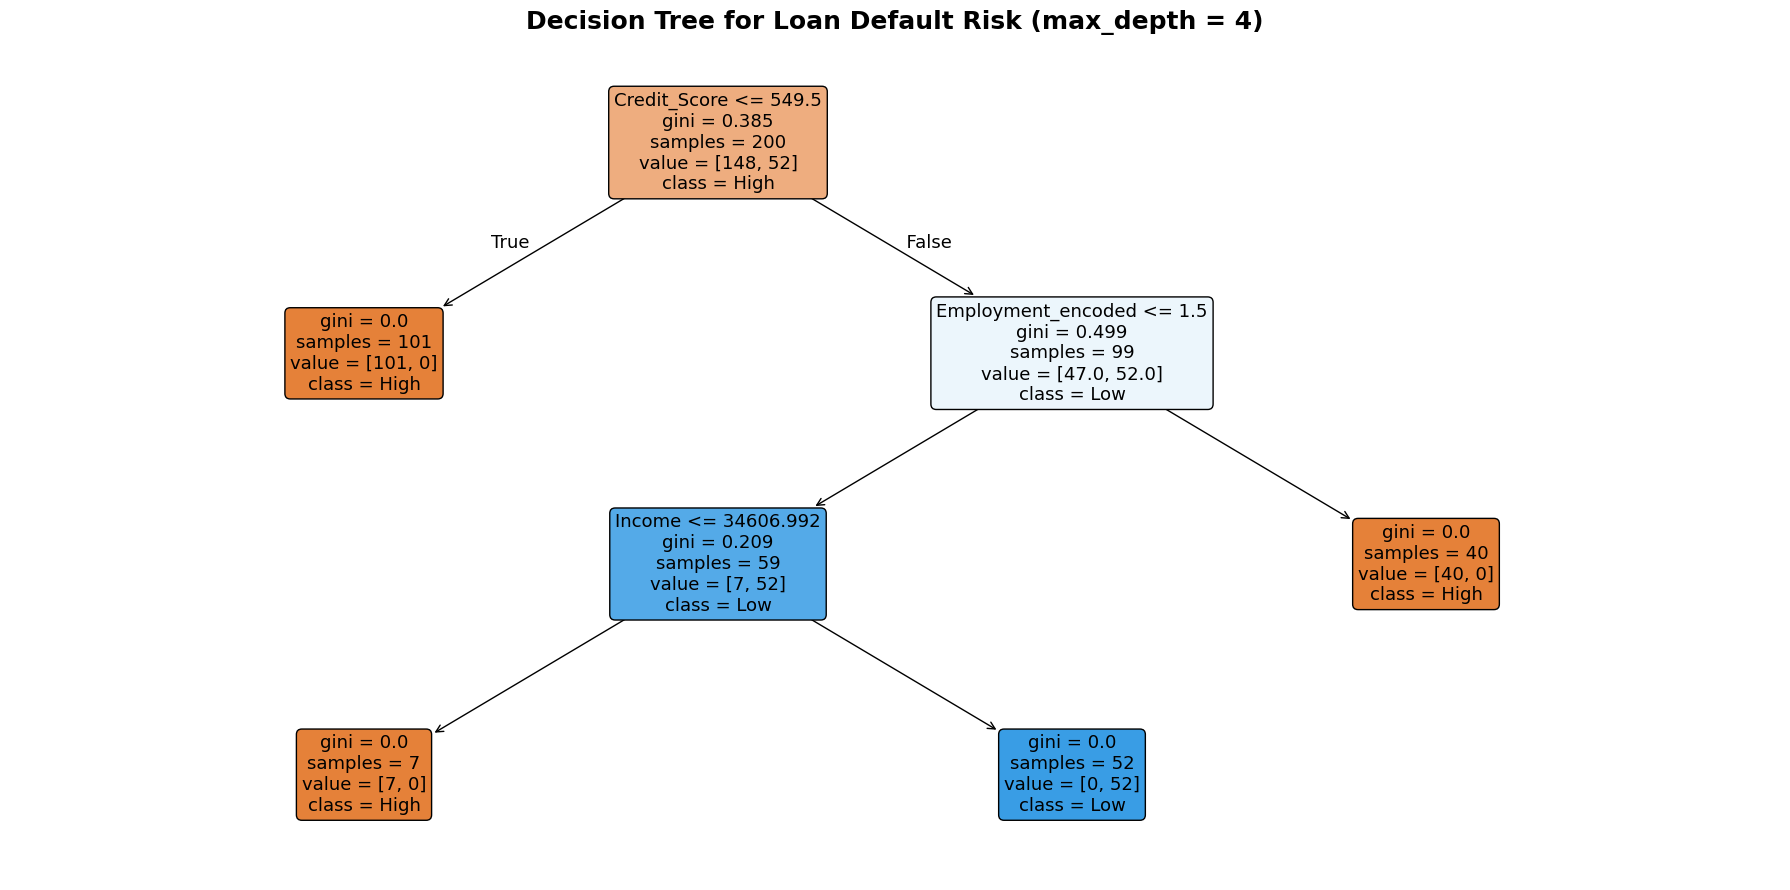

In [50]:
fig, ax = plt.subplots(figsize=(18, 9))
plot_tree(
    tree_model,
    feature_names=feature_names,
    class_names=list(le_risk.classes_),
    filled=True,
    rounded=True,
    fontsize=13,
    impurity=True,
    ax=ax,
)
ax.set_title('Decision Tree for Loan Default Risk (max_depth = 4)', fontsize=18, fontweight='bold')
plt.tight_layout()
plt.show()

The same tree can also be printed as plain-text rules, which shows directly why decision trees are called interpretable:

In [51]:
print(export_text(tree_model, feature_names=feature_names, class_names=list(le_risk.classes_), decimals=1))

|--- Credit_Score <= 549.5
|   |--- class: High
|--- Credit_Score >  549.5
|   |--- Employment_encoded <= 1.5
|   |   |--- Income <= 34607.0
|   |   |   |--- class: High
|   |   |--- Income >  34607.0
|   |   |   |--- class: Low
|   |--- Employment_encoded >  1.5
|   |   |--- class: High



## 6.7 Evaluation on the test set

Test accuracy: 0.9800  (98.0%)

Confusion matrix (rows = actual, columns = predicted, order = [High, Low]):
[[30  1]
 [ 0 19]]


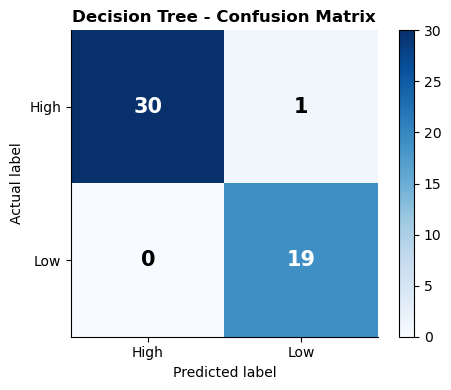

In [52]:
y_pred_tree = tree_model.predict(X_test)
tree_acc = accuracy_score(y_test, y_pred_tree)
cm_tree = confusion_matrix(y_test, y_pred_tree)

print(f'Test accuracy: {tree_acc:.4f}  ({tree_acc:.1%})')
print()
print('Confusion matrix (rows = actual, columns = predicted, order = [High, Low]):')
print(cm_tree)

plot_confusion_matrix(cm_tree, list(le_risk.classes_), 'Decision Tree - Confusion Matrix')
plt.tight_layout()
plt.show()

## 6.8 Predicting risk for a new customer

The new customer must be encoded with the **same** LabelEncoder fitted earlier, so that "Unemployed" receives the same code the tree was trained on. Creating a new encoder could assign a different number.

In [53]:
new_customer = pd.DataFrame({
    'Age': [30],
    'Income': [40000],
    'Credit_Score': [520],
    'Employment_encoded': le_emp.transform(['Unemployed']),
})
print('Encoded input:')
print(new_customer)

pred_code = tree_model.predict(new_customer)[0]
pred_label = le_risk.inverse_transform([pred_code])[0]
proba = tree_model.predict_proba(new_customer)[0]

print()
print(f'Predicted risk: {pred_label}')
print('Class probabilities:', {c: round(float(p), 3) for c, p in zip(le_risk.classes_, proba)})
print()
print('This agrees with the true rule twice over: Credit_Score 520 is below 550, and the customer is Unemployed.')

path = tree_model.decision_path(new_customer)
node_ids = path.indices
t = tree_model.tree_
print()
print('Path taken through the tree:')
for node in node_ids:
    if t.children_left[node] == t.children_right[node]:
        print(f'  Leaf node {node}: predict {le_risk.classes_[np.argmax(t.value[node])]}')
    else:
        feat = feature_names[t.feature[node]]
        thr = t.threshold[node]
        val = new_customer.iloc[0][feat]
        print(f'  Node {node}: {feat} = {val} <= {thr:.1f} ? {"yes, go left" if val <= thr else "no, go right"}')

Encoded input:
   Age  Income  Credit_Score  Employment_encoded
0   30   40000           520                   2

Predicted risk: High
Class probabilities: {'High': 1.0, 'Low': 0.0}

This agrees with the true rule twice over: Credit_Score 520 is below 550, and the customer is Unemployed.

Path taken through the tree:
  Node 0: Credit_Score = 520 <= 549.5 ? yes, go left
  Leaf node 1: predict High


## 6.9 The effect of max_depth: overfitting

A deeper tree can ask more questions and fit the training data more closely. Beyond a certain depth, however, it starts memorising noise and individual samples. The plot below trains trees of increasing depth: training accuracy keeps rising toward 100%, while test accuracy stops improving. The widening gap between the two curves is **overfitting**.

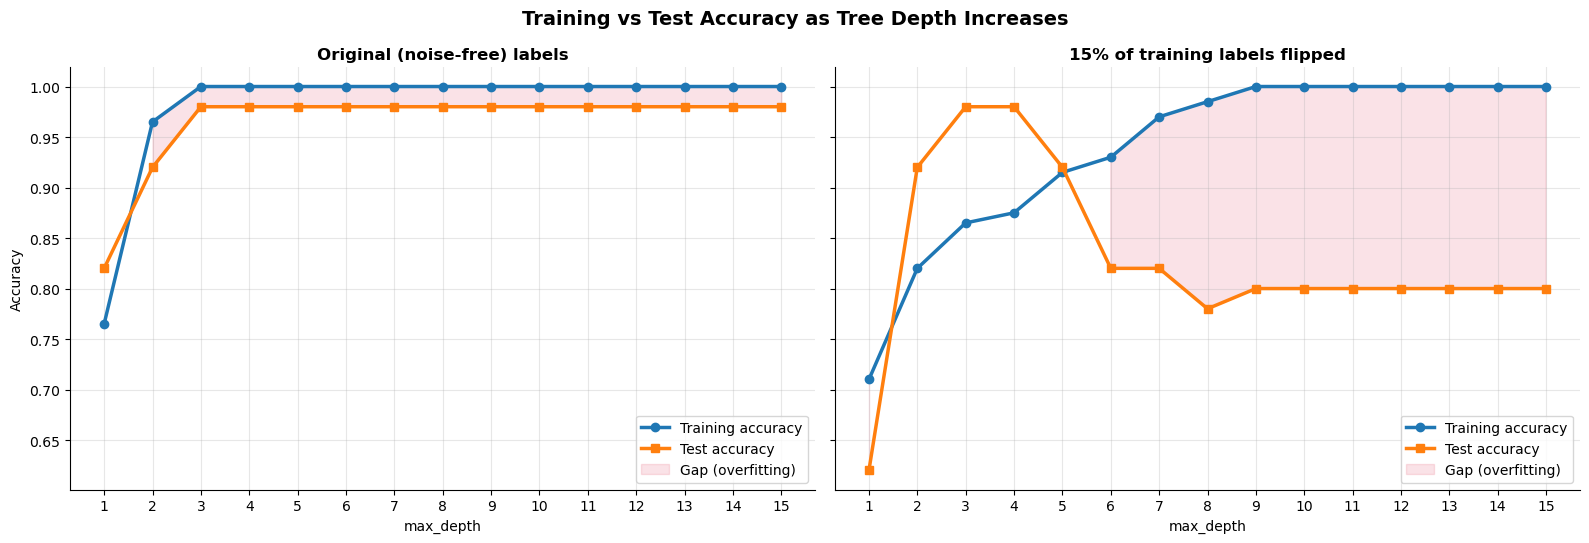

Left: the Risk rule is simple and noise-free, so the tree finds it within a few levels and extra depth
changes nothing, because every leaf is already pure.
Right: with noisy labels, training accuracy climbs to 100% as the tree memorises the flipped records,
while test accuracy peaks at depth 3 (98%) and then declines to 80% at depth 15.
Real data almost always contains noise, which is why limiting max_depth matters.


In [54]:
depths = range(1, 16)

# Version with 15% of training labels flipped, to mimic real-world noise and mislabelled records
rng_noise = np.random.RandomState(0)
y_train_noisy = y_train.copy()
flip = rng_noise.rand(len(y_train_noisy)) < 0.15
y_train_noisy[flip] = 1 - y_train_noisy[flip]

curves = {}
for label, y_tr in [('Original (noise-free) labels', y_train), ('15% of training labels flipped', y_train_noisy)]:
    tr, te = [], []
    for d in depths:
        m = DecisionTreeClassifier(max_depth=d, random_state=42).fit(X_train, y_tr)
        tr.append(m.score(X_train, y_tr))
        te.append(m.score(X_test, y_test))
    curves[label] = (tr, te)

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), sharey=True)
for ax, (label, (tr, te)) in zip(axes, curves.items()):
    ax.plot(list(depths), tr, marker='o', lw=2.5, label='Training accuracy')
    ax.plot(list(depths), te, marker='s', lw=2.5, label='Test accuracy')
    ax.fill_between(list(depths), te, tr, where=np.array(tr) > np.array(te), color='crimson', alpha=0.12,
                    label='Gap (overfitting)')
    ax.set_xticks(list(depths))
    ax.set_xlabel('max_depth')
    ax.set_title(label)
    ax.legend(loc='lower right')
axes[0].set_ylabel('Accuracy')
plt.suptitle('Training vs Test Accuracy as Tree Depth Increases', fontweight='bold', fontsize=14)
plt.tight_layout()
plt.show()

tr, te = curves['15% of training labels flipped']
best_d = int(np.argmax(te)) + 1
print('Left: the Risk rule is simple and noise-free, so the tree finds it within a few levels and extra depth')
print('changes nothing, because every leaf is already pure.')
print(f'Right: with noisy labels, training accuracy climbs to {tr[-1]:.0%} as the tree memorises the flipped records,')
print(f'while test accuracy peaks at depth {best_d} ({max(te):.0%}) and then declines to {te[-1]:.0%} at depth 15.')
print('Real data almost always contains noise, which is why limiting max_depth matters.')

## 6.10 Discussion

**Why are decision trees considered interpretable models?**
Every prediction follows an explicit path of simple threshold questions, such as "Credit_Score <= 549.5", which can be drawn, printed as if-then rules and explained to a non-technical person. It is always possible to state exactly why a particular customer received a particular prediction.

**What is the risk of setting max_depth too high?**
A very deep tree keeps splitting until its leaves contain only a few samples, so it memorises noise and outliers in the training data instead of learning the general pattern. This is overfitting: training accuracy approaches 100% while accuracy on new data stagnates or falls, and the tree becomes too large to interpret.

---
# 7. Cross-Validation and Model Comparison

## 7.1 Concept: the weakness of a single split

A single train-test split gives one accuracy number, and that number depends on **which rows happened to land in the test set**. A lucky split containing easy examples overstates performance; an unlucky split understates it. With small datasets the difference can be several percentage points.

## 7.2 K-fold cross-validation

K-fold cross-validation removes this dependence on a single split:

1. Divide the data into $K$ equal parts called **folds**.
2. Train on $K-1$ folds and test on the remaining fold.
3. Repeat $K$ times so that **every fold serves as the test set exactly once**.
4. Report the **mean** and **standard deviation** of the $K$ scores.

Every sample is used for testing exactly once and for training $K-1$ times. The mean gives a more reliable performance estimate, and the standard deviation shows how much performance varies from one subset of data to another.

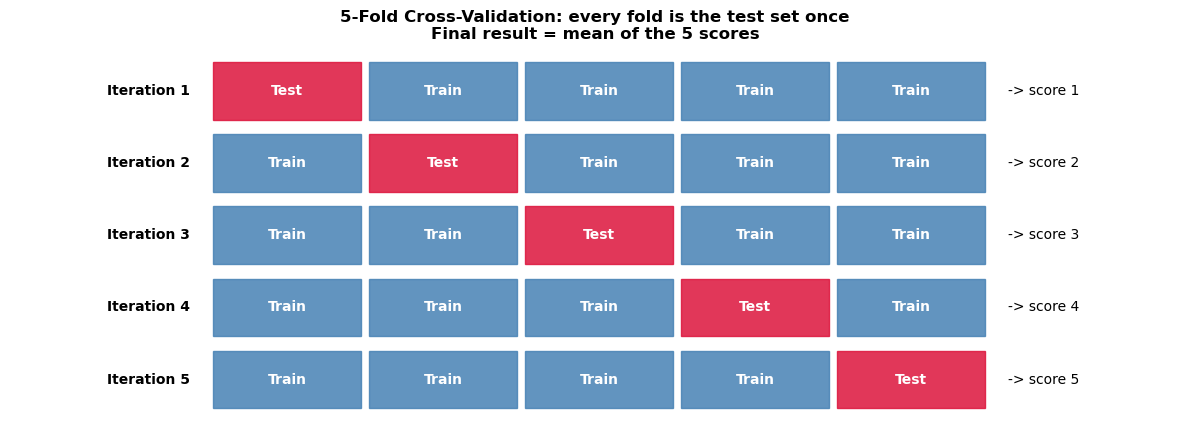

In [55]:
fig, ax = plt.subplots(figsize=(12, 4.5))
k = 5
for fold in range(k):
    for part in range(k):
        is_test = part == fold
        ax.add_patch(plt.Rectangle((part, k - fold - 1), 0.95, 0.8,
                                   color='crimson' if is_test else 'steelblue', alpha=0.85))
        ax.text(part + 0.475, k - fold - 0.6, 'Test' if is_test else 'Train',
                ha='center', va='center', color='white', fontweight='bold')
    ax.text(-0.15, k - fold - 0.6, f'Iteration {fold + 1}', ha='right', va='center', fontweight='bold')
    ax.text(k + 0.1, k - fold - 0.6, f'-> score {fold + 1}', ha='left', va='center')
ax.set_xlim(-1.3, k + 1.2)
ax.set_ylim(-0.3, k)
ax.axis('off')
ax.set_title('5-Fold Cross-Validation: every fold is the test set once\nFinal result = mean of the 5 scores',
             fontweight='bold')
plt.tight_layout()
plt.show()

## 7.3 The dataset and scaling

In [56]:
from sklearn.model_selection import cross_val_score, StratifiedKFold, KFold
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import make_scorer, f1_score

np.random.seed(42)
n = 400
df_cv = pd.DataFrame({
    'Feature1': np.random.normal(50, 10, n),
    'Feature2': np.random.normal(30, 8, n),
    'Feature3': np.random.normal(70, 15, n),
    'Feature4': np.random.normal(20, 5, n)
})
df_cv['Target'] = (df_cv['Feature1'] + df_cv['Feature2'] * 0.5 - df_cv['Feature3'] * 0.3 > 40).astype(int)

X_cv = StandardScaler().fit_transform(df_cv.drop(columns='Target'))
y_cv = df_cv['Target'].values

print('Scaled feature matrix shape:', X_cv.shape)
print('Class distribution:', {int(k): int(v) for k, v in zip(*np.unique(y_cv, return_counts=True))})
print(f'Proportion of class 1: {y_cv.mean():.1%}')

Scaled feature matrix shape: (400, 4)
Class distribution: {0: 148, 1: 252}
Proportion of class 1: 63.0%


**Note on methodology.** The assignment scales the full dataset once before cross-validation. Strictly, this lets each test fold influence the mean and standard deviation used for scaling, a mild form of data leakage. With simple standardisation on 400 rows the effect is negligible, but the fully correct approach, placing the scaler inside a Pipeline so it is refitted within every fold, is demonstrated in Section 10.

## 7.4 Logistic Regression: 5-fold cross-validation

`cross_val_score` performs the entire loop from the diagram above: it splits, trains a fresh copy of the model on each training portion, scores each test fold, and returns an array of scores.

For classifiers, passing an integer such as `cv=5` makes scikit-learn use **StratifiedKFold** automatically, without shuffling.

In [57]:
lr_cv = LogisticRegression(max_iter=1000)
lr_scores = cross_val_score(lr_cv, X_cv, y_cv, cv=5, scoring='accuracy')

for i, s in enumerate(lr_scores, start=1):
    print(f'Fold {i}: accuracy = {s:.4f}')
print(f'Mean accuracy: {lr_scores.mean():.4f}')
print(f'Std deviation: {lr_scores.std():.4f}')

Fold 1: accuracy = 0.9500
Fold 2: accuracy = 0.9750
Fold 3: accuracy = 0.9875
Fold 4: accuracy = 1.0000
Fold 5: accuracy = 0.9250
Mean accuracy: 0.9675
Std deviation: 0.0269


## 7.5 Decision Tree (max_depth = 5): 5-fold cross-validation

In [58]:
dt_cv = DecisionTreeClassifier(max_depth=5, random_state=42)
dt_scores = cross_val_score(dt_cv, X_cv, y_cv, cv=5, scoring='accuracy')

for i, s in enumerate(dt_scores, start=1):
    print(f'Fold {i}: accuracy = {s:.4f}')
print(f'Mean accuracy: {dt_scores.mean():.4f}')
print()
diff = lr_scores.mean() - dt_scores.mean()
better = 'Logistic Regression' if diff > 0 else 'Decision Tree'
print(f'Logistic Regression mean: {lr_scores.mean():.4f}')
print(f'Decision Tree mean      : {dt_scores.mean():.4f}')
print(f'{better} is better by {abs(diff):.4f} ({abs(diff):.1%}).')
print()
print('The target is defined by a weighted sum of features, a linear rule. Logistic regression draws exactly')
print('that kind of straight boundary, whereas a tree must approximate a diagonal line with a staircase of')
print('axis-aligned splits, which costs accuracy.')

Fold 1: accuracy = 0.8625
Fold 2: accuracy = 0.9000
Fold 3: accuracy = 0.9375
Fold 4: accuracy = 0.8250
Fold 5: accuracy = 0.8625
Mean accuracy: 0.8775

Logistic Regression mean: 0.9675
Decision Tree mean      : 0.8775
Logistic Regression is better by 0.0900 (9.0%).

The target is defined by a weighted sum of features, a linear rule. Logistic regression draws exactly
that kind of straight boundary, whereas a tree must approximate a diagonal line with a staircase of
axis-aligned splits, which costs accuracy.


## 7.6 Random Forest (n_estimators = 100): 5-fold cross-validation

In [59]:
rf_cv = RandomForestClassifier(n_estimators=100, random_state=42)
rf_scores = cross_val_score(rf_cv, X_cv, y_cv, cv=5, scoring='accuracy')

for i, s in enumerate(rf_scores, start=1):
    print(f'Fold {i}: accuracy = {s:.4f}')
print(f'Mean accuracy     : {rf_scores.mean():.4f}')
print(f'Standard deviation: {rf_scores.std():.4f}')

Fold 1: accuracy = 0.9250
Fold 2: accuracy = 0.8625
Fold 3: accuracy = 0.9500
Fold 4: accuracy = 0.8500
Fold 5: accuracy = 0.8250
Mean accuracy     : 0.8825
Standard deviation: 0.0472


## 7.7 StratifiedKFold

### Why stratification matters
Plain **KFold** cuts the data into consecutive blocks. If the rows happen to be ordered by class, or if one class is rare, a fold can end up with very few or even zero samples of a class. Training on such a fold teaches a distorted picture, and testing on it gives a misleading score.

**StratifiedKFold** builds each fold so that it has the **same class proportions as the full dataset**. If 40% of all samples are class 1, every fold contains about 40% class 1.

The demonstration below makes the danger visible by sorting the rows by class, a situation that occurs in real data exported from databases.

Share of class 1 in each test fold when data is sorted by class:
Method  KFold (no shuffle)  StratifiedKFold
Fold                                       
1                     0.00            0.625
2                     0.15            0.625
3                     1.00            0.625
4                     1.00            0.638
5                     1.00            0.638
Share of class 1 in the full dataset: 0.630


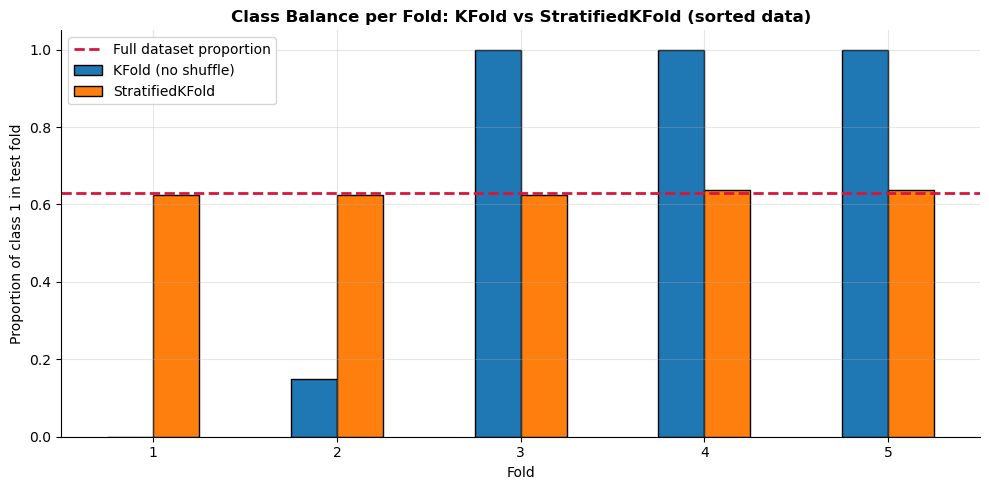

Logistic Regression scores with plain KFold on sorted data: [0.762 0.912 0.938 0.975 0.988]
Three of the five test folds contain only class 1, and the training folds are correspondingly distorted, so
the scores swing widely and do not describe how the model performs on the real class mix.


In [60]:
order = np.argsort(y_cv)             # rows sorted by class: all 0s first, then all 1s
y_sorted = y_cv[order]

rows = []
for name, splitter in [('KFold (no shuffle)', KFold(n_splits=5)),
                       ('StratifiedKFold', StratifiedKFold(n_splits=5, shuffle=True, random_state=42))]:
    for fold, (tr, te) in enumerate(splitter.split(np.zeros(len(y_sorted)), y_sorted), start=1):
        rows.append({'Method': name, 'Fold': fold, 'Class 1 share in test fold': y_sorted[te].mean()})
props = pd.DataFrame(rows).pivot(index='Fold', columns='Method', values='Class 1 share in test fold')
print('Share of class 1 in each test fold when data is sorted by class:')
print(props.round(3))
print(f'Share of class 1 in the full dataset: {y_cv.mean():.3f}')

ax = props.plot.bar(figsize=(10, 5), edgecolor='black', rot=0)
ax.axhline(y_cv.mean(), color='crimson', ls='--', lw=2, label='Full dataset proportion')
ax.set_ylabel('Proportion of class 1 in test fold')
ax.set_title('Class Balance per Fold: KFold vs StratifiedKFold (sorted data)')
ax.legend()
plt.tight_layout()
plt.show()

# The damage this causes to evaluation
bad = cross_val_score(LogisticRegression(max_iter=1000), X_cv[order], y_sorted, cv=KFold(n_splits=5))
print('Logistic Regression scores with plain KFold on sorted data:', bad.round(3))
print('Three of the five test folds contain only class 1, and the training folds are correspondingly distorted, so')
print('the scores swing widely and do not describe how the model performs on the real class mix.')

In [61]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Decision Tree (depth 5)': DecisionTreeClassifier(max_depth=5, random_state=42),
    'Random Forest (100 trees)': RandomForestClassifier(n_estimators=100, random_state=42),
    'SVC (additional)': SVC(),
}

f1_scorer = make_scorer(f1_score)
results, all_scores = [], {}
for name, model in models.items():
    acc = cross_val_score(model, X_cv, y_cv, cv=skf, scoring='accuracy')
    f1 = cross_val_score(model, X_cv, y_cv, cv=skf, scoring=f1_scorer)
    all_scores[name] = acc
    results.append({'Model': name, 'Mean accuracy': acc.mean(), 'Std accuracy': acc.std(),
                    'Mean F1': f1.mean(), 'Std F1': f1.std()})

print('Per-fold accuracy with StratifiedKFold (5 splits, shuffled):')
for name, s in all_scores.items():
    print(f'  {name:<27}: {np.round(s, 3)}')

Per-fold accuracy with StratifiedKFold (5 splits, shuffled):
  Logistic Regression        : [0.975 1.    0.95  0.962 0.975]
  Decision Tree (depth 5)    : [0.888 0.85  0.888 0.962 0.8  ]
  Random Forest (100 trees)  : [0.925 0.9   0.925 0.938 0.8  ]
  SVC (additional)           : [0.938 0.925 0.925 0.962 0.925]


## 7.8 Comparison table

The SVC row is included for additional context (it is imported in the assignment's starter code). F1-score, computed through `make_scorer(f1_score)`, is reported alongside accuracy.

                    Model  Mean accuracy  Std accuracy  Mean F1  Std F1
      Logistic Regression         0.9725        0.0166   0.9787  0.0129
         SVC (additional)         0.9350        0.0146   0.9495  0.0110
Random Forest (100 trees)         0.8975        0.0502   0.9172  0.0432
  Decision Tree (depth 5)         0.8775        0.0533   0.9036  0.0427

Best of the three required models: Logistic Regression (mean accuracy 0.9725 +/- 0.0166)


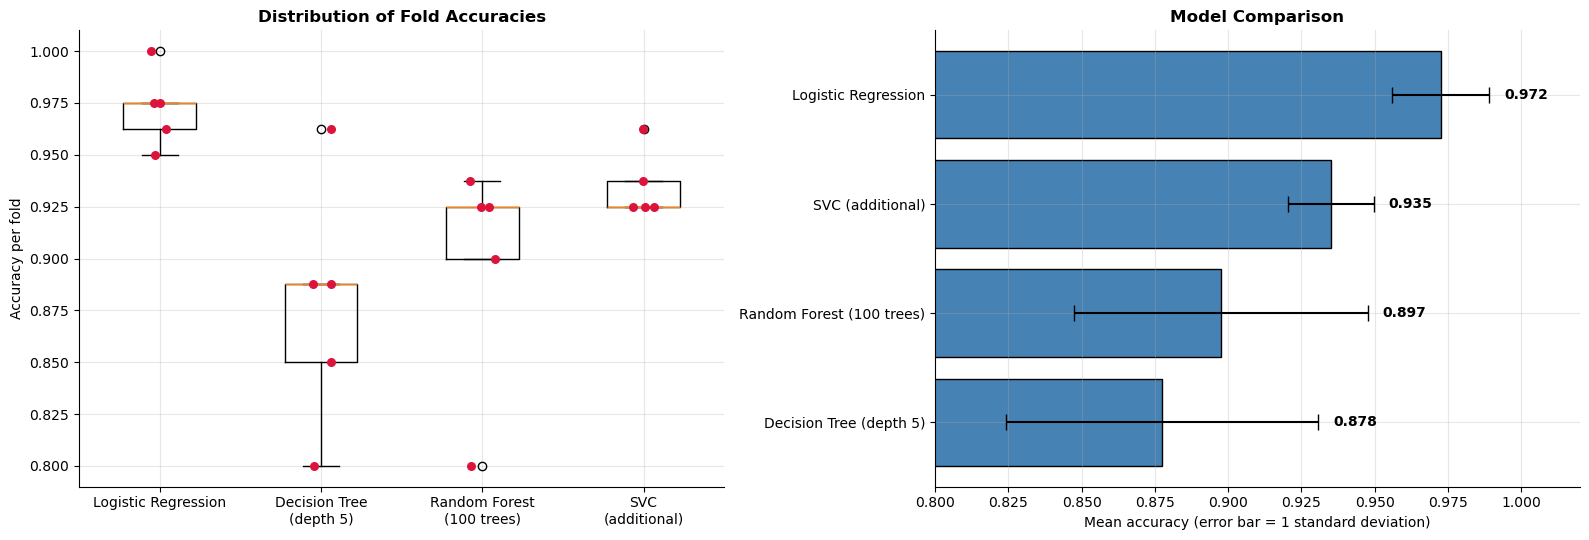

In [62]:
comparison = pd.DataFrame(results).sort_values('Mean accuracy', ascending=False).reset_index(drop=True)
print(comparison.round(4).to_string(index=False))
print()
required = comparison[comparison['Model'] != 'SVC (additional)'].iloc[0]
print(f'Best of the three required models: {required["Model"]} '
      f'(mean accuracy {required["Mean accuracy"]:.4f} +/- {required["Std accuracy"]:.4f})')

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
ax = axes[0]
ax.boxplot(list(all_scores.values()))
ax.set_xticks(range(1, len(all_scores) + 1))
ax.set_xticklabels([n.replace(' (', '\n(') for n in all_scores.keys()])
for i, s in enumerate(all_scores.values(), start=1):
    ax.scatter(np.full(len(s), i) + np.random.uniform(-0.08, 0.08, len(s)), s, color='crimson', zorder=3, s=30)
ax.set_ylabel('Accuracy per fold')
ax.set_title('Distribution of Fold Accuracies')

ax = axes[1]
comp_sorted = comparison.sort_values('Mean accuracy')
ax.barh(comp_sorted['Model'], comp_sorted['Mean accuracy'], xerr=comp_sorted['Std accuracy'],
        color='steelblue', edgecolor='black', capsize=6)
for i, (m, s) in enumerate(zip(comp_sorted['Mean accuracy'], comp_sorted['Std accuracy'])):
    ax.text(m + s + 0.005, i, f'{m:.3f}', va='center', fontweight='bold')
ax.set_xlim(0.8, 1.02)
ax.set_xlabel('Mean accuracy (error bar = 1 standard deviation)')
ax.set_title('Model Comparison')
plt.tight_layout()
plt.show()

## 7.9 Discussion

**Why is cross-validation more reliable than a single train-test split?**
A single split produces one score that depends heavily on which rows happened to be placed in the test set, whereas cross-validation tests the model on every part of the data and averages the results. The mean of several scores is far less affected by a lucky or unlucky split, and every sample contributes to both training and evaluation.

**What does the standard deviation of CV scores indicate?**
The standard deviation measures how much performance changes across different subsets of the data. A small value means the model is stable and its mean score can be trusted, while a large value means performance depends strongly on the particular data it sees, a sign of high variance, overfitting, or too little data.

---
# 8. Random Forest and Feature Importance

## 8.1 Concept

A single decision tree is easy to interpret but **unstable**: a small change in the training data can produce a completely different tree. It also tends to overfit.

A random forest is an **ensemble**: it trains many decision trees, each slightly different, and combines their votes. Individual trees make different mistakes; when their predictions are combined, many of those mistakes cancel out.

**Analogy.** Asking one person to estimate the number of sweets in a jar gives a noisy guess. Averaging the guesses of 100 people who reason independently is usually far closer to the truth. This is often called the wisdom of crowds.

## 8.2 How a random forest makes its trees different

Two sources of randomness ensure that the trees are not identical copies:

1. **Bootstrap sampling (bagging).** Each tree is trained on a random sample of the training rows drawn **with replacement**, the same size as the original. Some rows appear several times and, on average, about 37% of rows are left out of any given tree.
2. **Random feature subsets.** At every split, each tree may only consider a random subset of the features. For classification the default is $\sqrt{p}$ features out of $p$. This stops every tree from always splitting on the same dominant feature.

**Prediction:**
- Classification: each tree votes, and the majority class wins (scikit-learn averages the trees' predicted probabilities).
- Regression: the forest prediction is the average of the trees' predictions.

### Key hyperparameters
| Parameter | Meaning |
|---|---|
| `n_estimators` | Number of trees. More trees give more stable results, with diminishing returns and higher computation cost. |
| `max_depth` | Maximum depth of each tree. |
| `max_features` | Number of features considered at each split. |
| `random_state` | Makes the random sampling reproducible. |

In [63]:
rng = np.random.RandomState(0)
original_rows = np.arange(10)
print('Original training rows :', original_rows)
for t in range(3):
    sample = rng.choice(original_rows, size=10, replace=True)
    left_out = sorted(int(v) for v in set(original_rows) - set(sample))
    print(f'Bootstrap sample tree {t + 1}: {np.sort(sample)}   rows left out: {left_out}')
print()
print('Each tree sees a different version of the data, so each tree learns slightly different splits.')

Original training rows : [0 1 2 3 4 5 6 7 8 9]
Bootstrap sample tree 1: [0 2 3 3 3 4 5 5 7 9]   rows left out: [1, 6, 8]
Bootstrap sample tree 2: [1 1 6 6 7 7 7 8 8 8]   rows left out: [0, 2, 3, 4, 5, 9]
Bootstrap sample tree 3: [0 0 3 3 4 5 5 8 9 9]   rows left out: [1, 2, 6, 7]

Each tree sees a different version of the data, so each tree learns slightly different splits.


## 8.3 The dataset

Rain occurs only when **all three** conditions hold: Humidity > 65, Cloud_Cover > 60 and Pressure < 1010. Temperature and Wind_Speed are irrelevant.

In [64]:
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import accuracy_score, mean_squared_error, r2_score, f1_score

np.random.seed(42)
n = 500
df_rain = pd.DataFrame({
    'Temperature': np.random.normal(25, 5, n),
    'Humidity': np.random.normal(60, 10, n),
    'Wind_Speed': np.random.normal(15, 5, n),
    'Pressure': np.random.normal(1013, 20, n),
    'Cloud_Cover': np.random.uniform(0, 100, n)
})
df_rain['Rain'] = np.where(
    (df_rain['Humidity'] > 65) & (df_rain['Cloud_Cover'] > 60) & (df_rain['Pressure'] < 1010), 1, 0
)
print(df_rain.head().round(2))
print()
print('Rain distribution:', df_rain['Rain'].value_counts().to_dict())
print(f'Rainy days: {df_rain["Rain"].mean():.1%}. The positive class is rare, so accuracy alone can be misleading.')

   Temperature  Humidity  Wind_Speed  Pressure  Cloud_Cover  Rain
0        27.48     69.26       22.00   1028.57        40.71     0
1        24.31     79.09       19.62   1001.98         6.60     0
2        28.24     46.01       15.30    996.64        34.88     0
3        32.62     65.63       11.77   1012.93        11.10     0
4        23.83     53.49       18.49   1009.60        80.82     0

Rain distribution: {0: 462, 1: 38}
Rainy days: 7.6%. The positive class is rare, so accuracy alone can be misleading.




Rain distribution: {0: 462, 1: 38}
Rainy days: 7.6%. The positive class is rare, so accuracy alone can be misleading.


## 8.4 Split (80-20) and scale

Tree-based models do not require scaling. It is applied here because the assignment specifies it; the results would be identical without it.

In [65]:
features = ['Temperature', 'Humidity', 'Wind_Speed', 'Pressure', 'Cloud_Cover']
X = df_rain[features]
y = df_rain['Rain']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler_rf = StandardScaler()
X_train_s = scaler_rf.fit_transform(X_train)
X_test_s = scaler_rf.transform(X_test)

print(f'Training rows: {len(X_train)}  (rainy: {int(y_train.sum())})')
print(f'Test rows    : {len(X_test)}  (rainy: {int(y_test.sum())})')

Training rows: 400  (rainy: 30)
Test rows    : 100  (rainy: 8)


## 8.5 Training the Random Forest Classifier

In [66]:
rf = RandomForestClassifier(n_estimators=100, max_depth=6, random_state=42)
rf.fit(X_train_s, y_train)
print(f'Number of trees in the forest: {len(rf.estimators_)}')
print(f'Features considered at each split (sqrt of 5, rounded down): {rf.estimators_[0].max_features_}')

Number of trees in the forest: 100
Features considered at each split (sqrt of 5, rounded down): 2


## 8.6 Feature importances

Random forest importance is the impurity decrease each feature produces, **averaged over all 100 trees**. Averaging makes it considerably more reliable than the importance from a single tree.

Feature importances (descending):
Humidity       0.3491
Cloud_Cover    0.2983
Pressure       0.2546
Wind_Speed     0.0572
Temperature    0.0408
dtype: float64


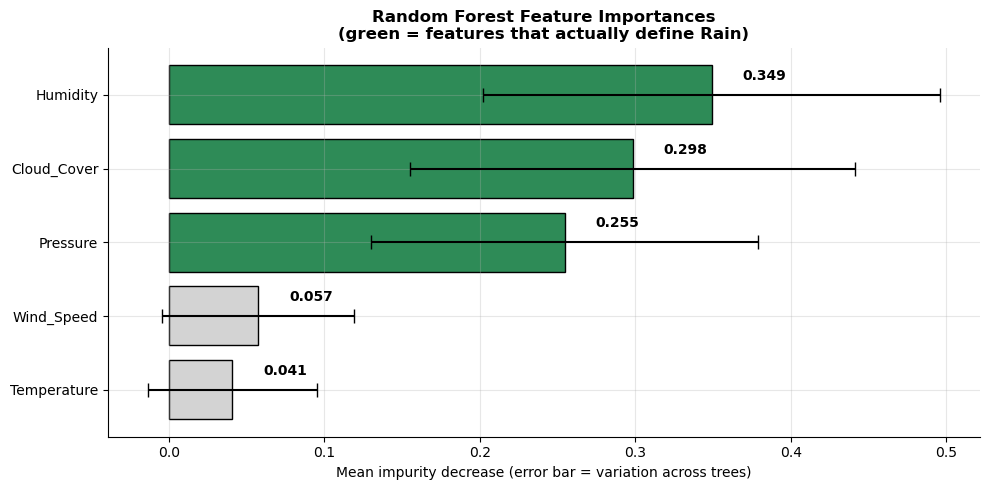

The three features used in the rain rule rank highest; Temperature and Wind_Speed are close to zero.


In [67]:
rf_importance = pd.Series(rf.feature_importances_, index=features).sort_values(ascending=False)
print('Feature importances (descending):')
print(rf_importance.round(4))

tree_std = np.std([t.feature_importances_ for t in rf.estimators_], axis=0)
rf_imp_sorted = rf_importance.sort_values()
std_sorted = pd.Series(tree_std, index=features)[rf_imp_sorted.index]

fig, ax = plt.subplots(figsize=(10, 5))
colors_imp = ['seagreen' if f in ['Humidity', 'Cloud_Cover', 'Pressure'] else 'lightgray' for f in rf_imp_sorted.index]
ax.barh(rf_imp_sorted.index, rf_imp_sorted.values, xerr=std_sorted.values, color=colors_imp, edgecolor='black', capsize=5)
for i, v in enumerate(rf_imp_sorted.values):
    ax.text(v + 0.02, i + 0.2, f'{v:.3f}', fontweight='bold')
ax.set_xlabel('Mean impurity decrease (error bar = variation across trees)')
ax.set_title('Random Forest Feature Importances\n(green = features that actually define Rain)')
plt.tight_layout()
plt.show()
print('The three features used in the rain rule rank highest; Temperature and Wind_Speed are close to zero.')

## 8.7 Accuracy: Random Forest versus a single Decision Tree

                      Model  Train accuracy  Test accuracy  Test F1 (rain class)
Baseline (always "no rain")             NaN           0.92                   0.0
       Single Decision Tree             1.0           1.00                   1.0
  Random Forest (100 trees)             1.0           1.00                   1.0

Single tree depth: 3 (unrestricted), leaves: 4


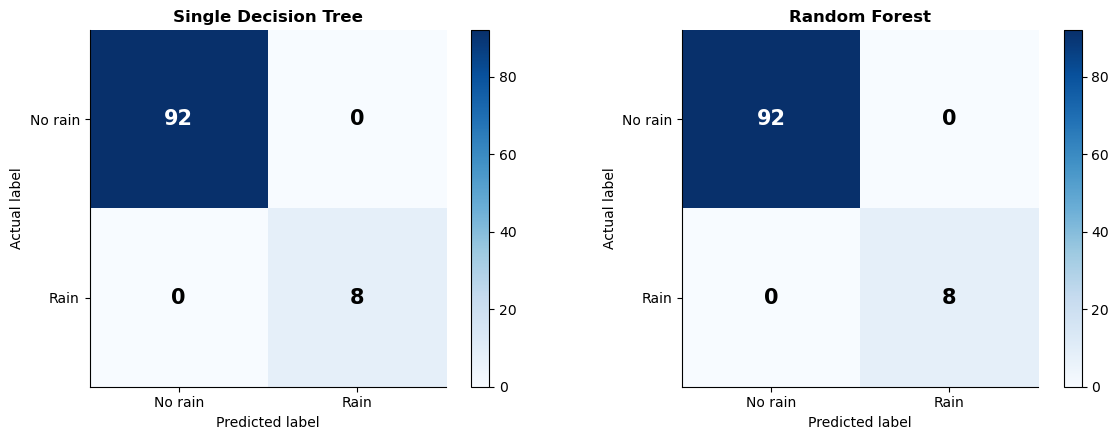

In [68]:
y_pred_rf = rf.predict(X_test_s)
dt_single = DecisionTreeClassifier(random_state=42).fit(X_train_s, y_train)
y_pred_dt = dt_single.predict(X_test_s)

baseline = (y_test == 0).mean()
summary = pd.DataFrame({
    'Model': ['Baseline (always "no rain")', 'Single Decision Tree', 'Random Forest (100 trees)'],
    'Train accuracy': [np.nan, dt_single.score(X_train_s, y_train), rf.score(X_train_s, y_train)],
    'Test accuracy': [baseline, accuracy_score(y_test, y_pred_dt), accuracy_score(y_test, y_pred_rf)],
    'Test F1 (rain class)': [0.0, f1_score(y_test, y_pred_dt), f1_score(y_test, y_pred_rf)],
})
print(summary.round(4).to_string(index=False))
print()
print(f'Single tree depth: {dt_single.get_depth()} (unrestricted), leaves: {dt_single.get_n_leaves()}')

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
plot_confusion_matrix(confusion_matrix(y_test, y_pred_dt), ['No rain', 'Rain'], 'Single Decision Tree', ax=axes[0])
plot_confusion_matrix(confusion_matrix(y_test, y_pred_rf), ['No rain', 'Rain'], 'Random Forest', ax=axes[1])
plt.tight_layout()
plt.show()

### How good are the individual trees inside the forest?

Each tree in the forest is tested on its own. Individual trees vary in quality because each saw a different bootstrap sample and different feature subsets. The forest, combining all of them, performs at or above the level of a typical individual tree and is far more consistent.

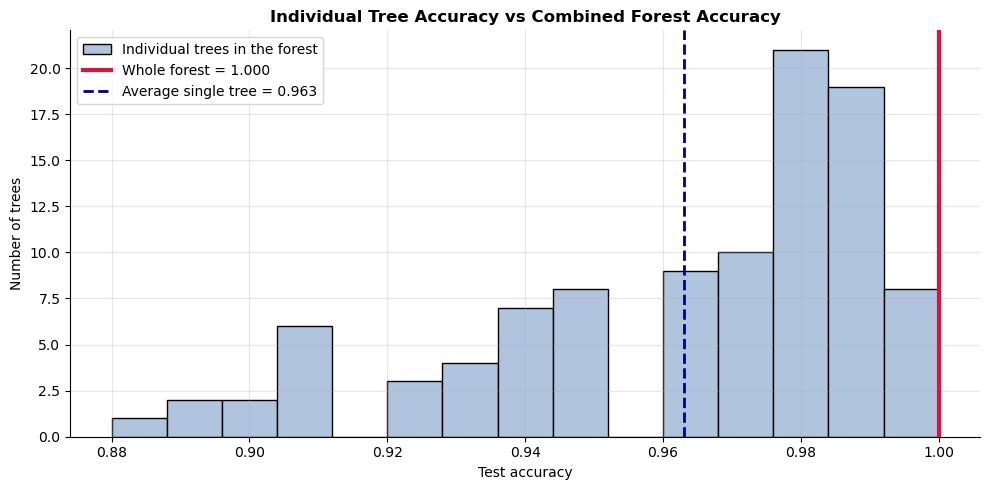

Individual tree accuracy ranges from 0.880 to 1.000.


In [69]:
individual = [accuracy_score(y_test, t.predict(X_test_s)) for t in rf.estimators_]
forest_acc = accuracy_score(y_test, y_pred_rf)

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(individual, bins=15, color='lightsteelblue', edgecolor='black', label='Individual trees in the forest')
ax.axvline(forest_acc, color='crimson', lw=3, label=f'Whole forest = {forest_acc:.3f}')
ax.axvline(np.mean(individual), color='navy', ls='--', lw=2, label=f'Average single tree = {np.mean(individual):.3f}')
ax.set_xlabel('Test accuracy')
ax.set_ylabel('Number of trees')
ax.set_title('Individual Tree Accuracy vs Combined Forest Accuracy')
ax.legend()
plt.tight_layout()
plt.show()
print(f'Individual tree accuracy ranges from {min(individual):.3f} to {max(individual):.3f}.')

### Where the forest's advantage appears: noisy data

On this dataset both models reach perfect test accuracy, because the rain rule is simple and the labels contain no errors. The advantage of a forest becomes visible when the training data is noisy. Below, 10% of the training labels are flipped at random (the test labels remain correct), and both models are retrained with 10 different noise patterns. The single unrestricted tree memorises the wrong labels; the forest's averaging absorbs much of that noise.

Single Decision Tree : mean test accuracy 0.885  (std 0.041)
Random Forest        : mean test accuracy 0.988  (std 0.009)


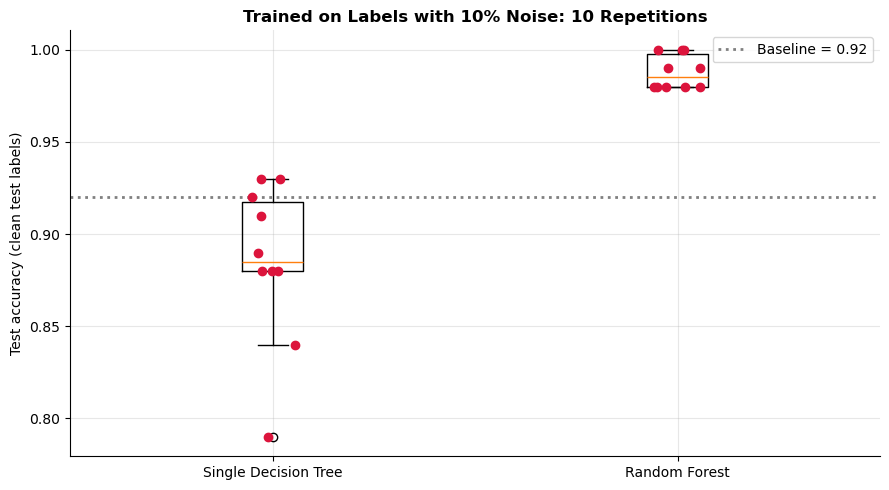

In [70]:
dt_noisy_acc, rf_noisy_acc = [], []
for seed in range(10):
    rng_n = np.random.RandomState(seed)
    y_noisy = y_train.values.copy()
    flip = rng_n.rand(len(y_noisy)) < 0.10
    y_noisy[flip] = 1 - y_noisy[flip]
    dt_noisy_acc.append(accuracy_score(y_test, DecisionTreeClassifier(random_state=42).fit(X_train_s, y_noisy).predict(X_test_s)))
    rf_noisy_acc.append(accuracy_score(y_test, RandomForestClassifier(n_estimators=100, max_depth=6, random_state=42)
                                       .fit(X_train_s, y_noisy).predict(X_test_s)))

print(f'Single Decision Tree : mean test accuracy {np.mean(dt_noisy_acc):.3f}  (std {np.std(dt_noisy_acc):.3f})')
print(f'Random Forest        : mean test accuracy {np.mean(rf_noisy_acc):.3f}  (std {np.std(rf_noisy_acc):.3f})')

fig, ax = plt.subplots(figsize=(9, 5))
ax.boxplot([dt_noisy_acc, rf_noisy_acc])
ax.set_xticks([1, 2])
ax.set_xticklabels(['Single Decision Tree', 'Random Forest'])
for i, vals in enumerate([dt_noisy_acc, rf_noisy_acc], start=1):
    ax.scatter(np.full(len(vals), i) + np.random.uniform(-0.06, 0.06, len(vals)), vals, color='crimson', zorder=3)
ax.axhline(baseline, color='gray', ls=':', lw=2, label=f'Baseline = {baseline:.2f}')
ax.set_ylabel('Test accuracy (clean test labels)')
ax.set_title('Trained on Labels with 10% Noise: 10 Repetitions')
ax.legend()
plt.tight_layout()
plt.show()

## 8.8 Random Forest Regressor: predicting Humidity

The regressor works in the same way but averages the numeric predictions of its trees.

`Rain` is excluded from the features, because Rain was **computed from** Humidity. Including it would let the model partly read the answer from a derived column, which is target leakage.

R² on test set : -0.0233
MSE on test set: 111.8973   (RMSE = 10.58)
Variance of Humidity in test set: 109.3539
Train R²       : 0.3889

Interpretation: Humidity was generated independently of every other feature, so no real relationship
exists to learn. An R² near or below zero, with MSE roughly equal to the variance of Humidity, is the
correct outcome: the model cannot beat simply predicting the average. The higher training R² shows the
forest fitting noise. This is an important lesson: a model cannot find signal that is not in the data.


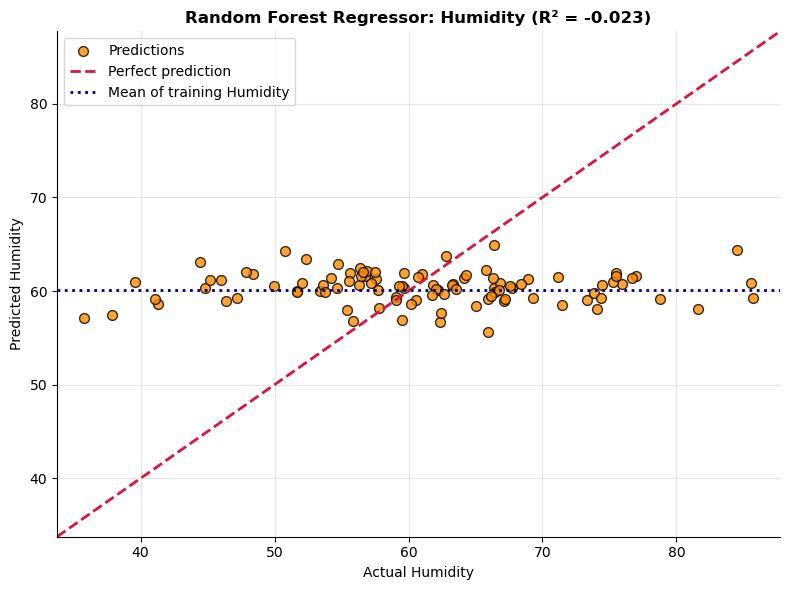

In [71]:
reg_features = ['Temperature', 'Wind_Speed', 'Pressure', 'Cloud_Cover']
Xr = df_rain[reg_features]
yr = df_rain['Humidity']

Xr_train, Xr_test, yr_train, yr_test = train_test_split(Xr, yr, test_size=0.2, random_state=42)
scaler_reg = StandardScaler()
Xr_train_s = scaler_reg.fit_transform(Xr_train)
Xr_test_s = scaler_reg.transform(Xr_test)

rf_reg = RandomForestRegressor(n_estimators=100, max_depth=6, random_state=42)
rf_reg.fit(Xr_train_s, yr_train)
yr_pred = rf_reg.predict(Xr_test_s)

r2_reg = r2_score(yr_test, yr_pred)
mse_reg = mean_squared_error(yr_test, yr_pred)
print(f'R² on test set : {r2_reg:.4f}')
print(f'MSE on test set: {mse_reg:.4f}   (RMSE = {np.sqrt(mse_reg):.2f})')
print(f'Variance of Humidity in test set: {yr_test.var(ddof=0):.4f}')
print(f'Train R²       : {r2_score(yr_train, rf_reg.predict(Xr_train_s)):.4f}')
print()
print('Interpretation: Humidity was generated independently of every other feature, so no real relationship')
print('exists to learn. An R² near or below zero, with MSE roughly equal to the variance of Humidity, is the')
print('correct outcome: the model cannot beat simply predicting the average. The higher training R² shows the')
print('forest fitting noise. This is an important lesson: a model cannot find signal that is not in the data.')

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(yr_test, yr_pred, color='darkorange', edgecolor='black', s=50, alpha=0.8, label='Predictions')
lims = [yr_test.min() - 2, yr_test.max() + 2]
ax.plot(lims, lims, color='crimson', ls='--', lw=2, label='Perfect prediction')
ax.axhline(yr_train.mean(), color='navy', ls=':', lw=2, label='Mean of training Humidity')
ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_xlabel('Actual Humidity'); ax.set_ylabel('Predicted Humidity')
ax.set_title(f'Random Forest Regressor: Humidity (R² = {r2_reg:.3f})')
ax.legend()
plt.tight_layout()
plt.show()

## 8.9 Effect of the number of trees (n_estimators)

Required values from the assignment:
  n_estimators =  50: accuracy = 1.0000   F1 = 1.0000
  n_estimators = 100: accuracy = 1.0000   F1 = 1.0000
  n_estimators = 200: accuracy = 1.0000   F1 = 1.0000


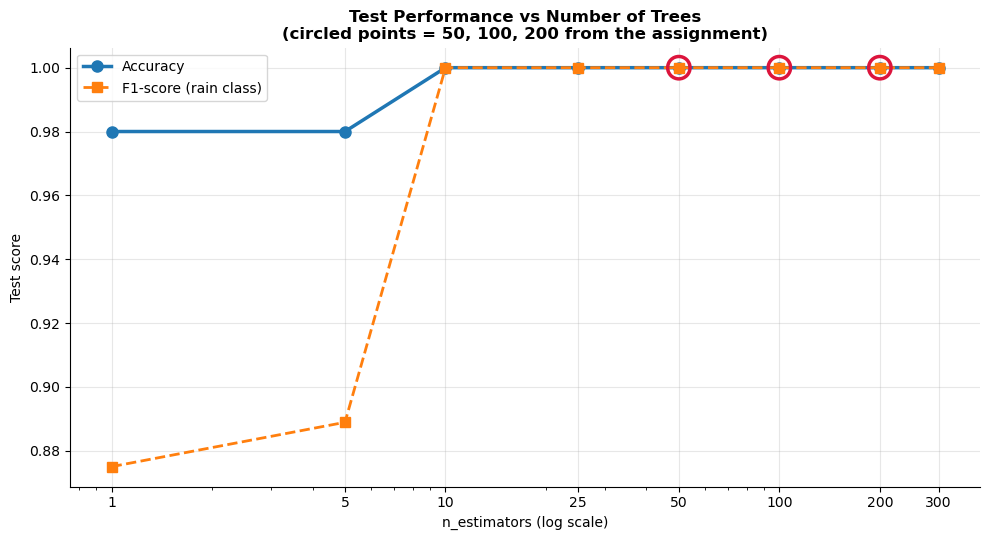

All n_estimators values: {1: 0.98, 5: 0.98, 10: 1.0, 25: 1.0, 50: 1.0, 100: 1.0, 200: 1.0, 300: 1.0}
The rain rule is simple and noise-free, and the test set has only 8 rainy days, so accuracy saturates almost
immediately and 50, 100 and 200 trees perform identically here. In general, performance improves quickly over
the first few dozen trees and then levels off; extra trees add computation time but do not cause overfitting.


In [72]:
required = [50, 100, 200]
n_values = [1, 5, 10, 25, 50, 100, 200, 300]
acc_by_n, f1_by_n = [], []
for n_est in n_values:
    m = RandomForestClassifier(n_estimators=n_est, max_depth=6, random_state=42).fit(X_train_s, y_train)
    pred = m.predict(X_test_s)
    acc_by_n.append(accuracy_score(y_test, pred))
    f1_by_n.append(f1_score(y_test, pred))

print('Required values from the assignment:')
for n_est in required:
    i = n_values.index(n_est)
    print(f'  n_estimators = {n_est:3d}: accuracy = {acc_by_n[i]:.4f}   F1 = {f1_by_n[i]:.4f}')

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(n_values, acc_by_n, marker='o', lw=2.5, markersize=8, label='Accuracy')
ax.plot(n_values, f1_by_n, marker='s', lw=2, ls='--', markersize=7, label='F1-score (rain class)')
for n_est in required:
    i = n_values.index(n_est)
    ax.scatter(n_est, acc_by_n[i], s=260, facecolor='none', edgecolor='crimson', linewidths=2.5, zorder=5)
ax.set_xscale('log')
ax.set_xticks(n_values)
ax.set_xticklabels(n_values)
ax.set_xlabel('n_estimators (log scale)')
ax.set_ylabel('Test score')
ax.set_title('Test Performance vs Number of Trees\n(circled points = 50, 100, 200 from the assignment)')
ax.legend()
plt.tight_layout()
plt.show()
print('All n_estimators values:', {k: round(float(v), 3) for k, v in zip(n_values, acc_by_n)})
print('The rain rule is simple and noise-free, and the test set has only 8 rainy days, so accuracy saturates almost')
print('immediately and 50, 100 and 200 trees perform identically here. In general, performance improves quickly over')
print('the first few dozen trees and then levels off; extra trees add computation time but do not cause overfitting.')

## 8.10 Discussion

**How does a Random Forest reduce overfitting compared to a single Decision Tree?**
Each tree is trained on a different bootstrap sample and considers only a random subset of features at each split, so the trees make different, partly independent errors. Averaging their predictions cancels much of this individual noise, reducing variance while keeping the flexibility of decision trees.

**Why is feature importance useful during EDA?**
Feature importance quickly identifies which variables actually drive the target, helping to confirm domain assumptions, detect irrelevant or suspicious features (such as a column that leaks the answer) and select a smaller set of features for later modelling. Here it correctly highlighted Humidity, Cloud_Cover and Pressure while assigning almost no weight to Temperature and Wind_Speed.

---
# 9. Hyperparameter Tuning with GridSearchCV

## 9.1 Parameters versus hyperparameters

| | Model parameters | Hyperparameters |
|---|---|---|
| **Set by** | Learned automatically during `fit` | Chosen by the practitioner before training |
| **Examples** | Coefficients in linear regression, split thresholds in a tree, support vectors in SVC | `C` and `kernel` in SVC, `max_depth` and `n_estimators` in a random forest |
| **Stored as** | Attributes ending in `_`, such as `coef_` | Arguments to the constructor, such as `SVC(C=10)` |

**Analogy.** When baking, the oven temperature and baking time are chosen in advance (hyperparameters). How the dough rises is determined by the process itself (parameters).

## 9.2 The Support Vector Classifier (SVC)

### Concept
Many straight lines can separate two classes. SVC chooses the line that leaves the **widest possible gap**, called the **margin**, between the classes. A wide margin generalises better, because new points near the boundary are less likely to fall on the wrong side.

- The points lying on the edge of the margin are the **support vectors**. They alone determine the boundary; moving any other point does not change it.
- In higher dimensions the line becomes a flat surface called a **hyperplane**.

### The hyperparameters tuned in this lab

| Hyperparameter | Meaning | Small value | Large value |
|---|---|---|---|
| `C` | Penalty for misclassifying training points | Wide, tolerant margin; simpler model (risk of underfitting) | Narrow margin that tries to classify every training point; complex model (risk of overfitting) |
| `kernel` | Shape of the boundary | `linear`: a straight line or flat plane | `rbf`: flexible, curved boundaries |
| `gamma` | For `rbf`: how far the influence of one training point reaches | Far-reaching influence; smooth boundary | Very local influence; wiggly boundary (risk of overfitting) |

`gamma='scale'` sets $\gamma = 1 / (\text{n\_features} \times \text{variance of X})$ and `gamma='auto'` sets $\gamma = 1 / \text{n\_features}$. On standardised data (variance 1) the two are identical. `gamma` has no effect when `kernel='linear'`.

### The kernel trick
Some data cannot be separated by a straight line in its original space. The RBF kernel implicitly maps the data into a higher-dimensional space where a flat separating surface exists. When mapped back to the original space, that surface appears as a curved boundary.

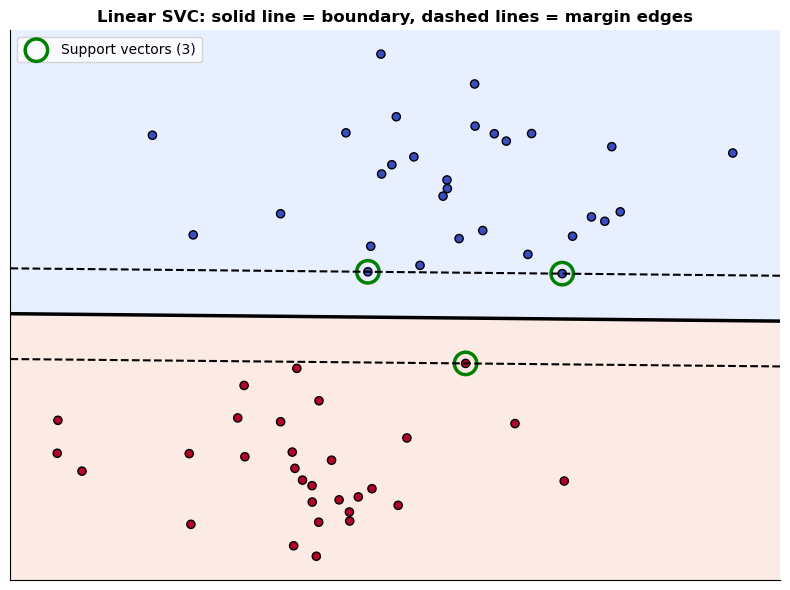

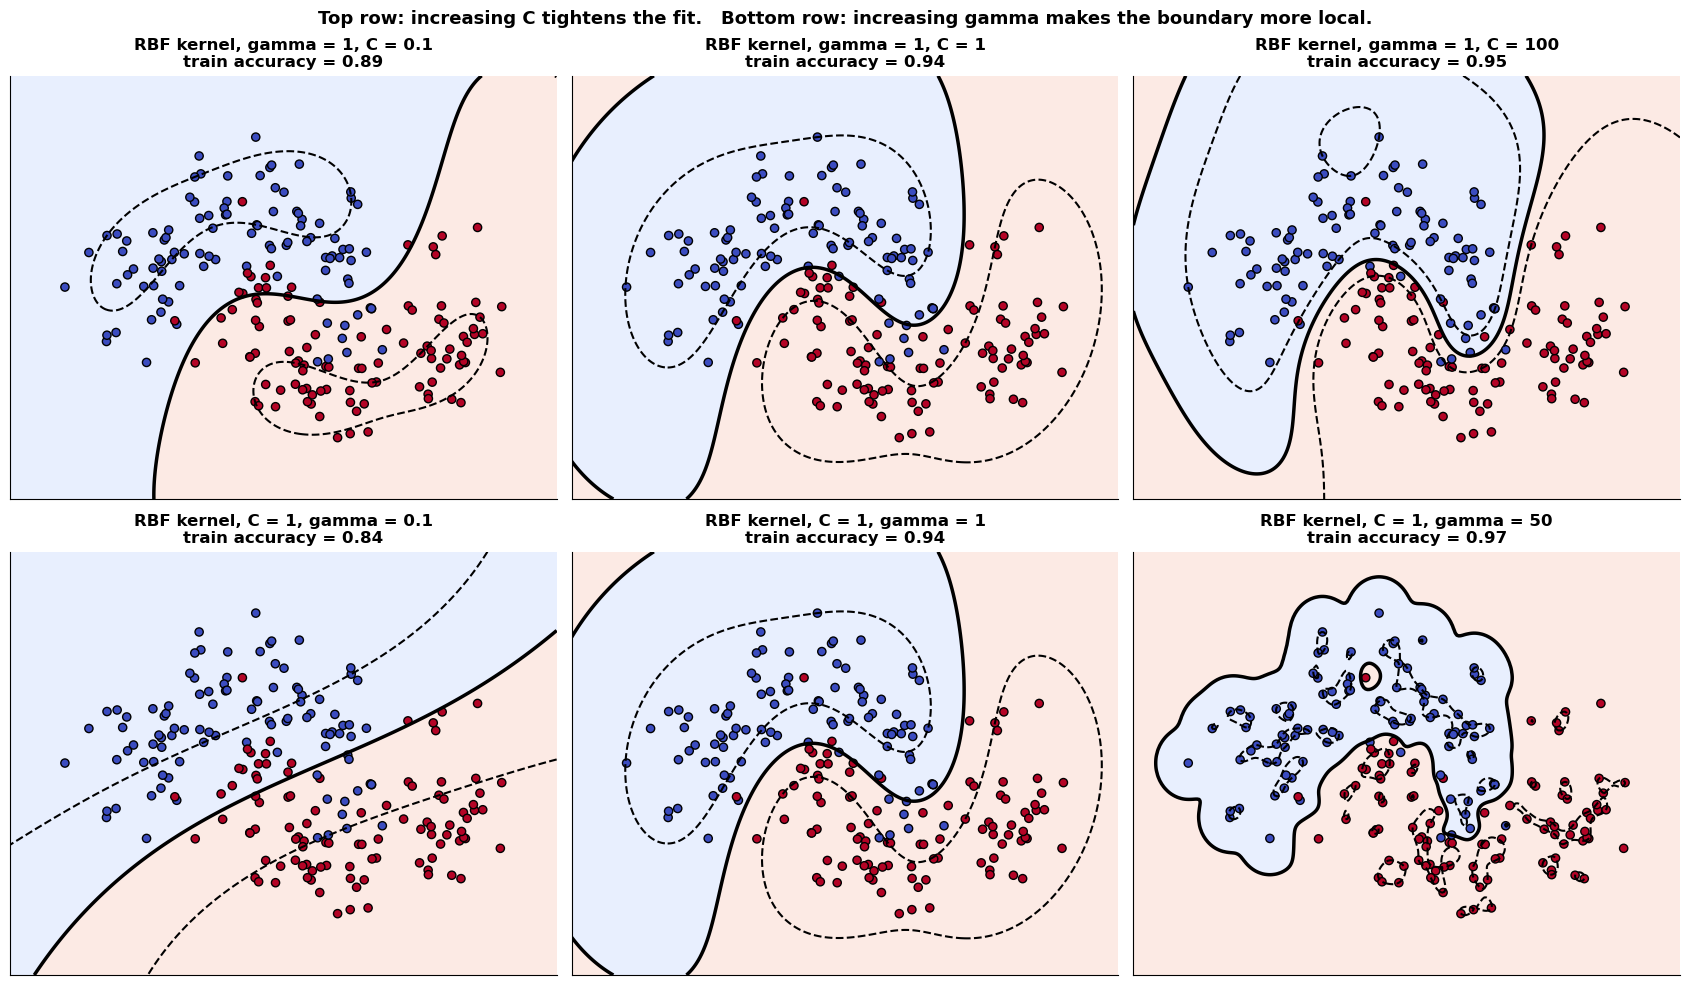

In [73]:
from sklearn.datasets import make_blobs, make_moons
from sklearn.svm import SVC

def draw_svc(ax, model, X, y, title):
    xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - 0.5, X[:, 0].max() + 0.5, 300),
                         np.linspace(X[:, 1].min() - 0.5, X[:, 1].max() + 0.5, 300))
    Z = model.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z > 0, alpha=0.2, cmap='coolwarm')
    ax.contour(xx, yy, Z, levels=[-1, 0, 1], colors='black', linestyles=['--', '-', '--'], linewidths=[1.5, 2.5, 1.5])
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap='coolwarm', edgecolor='black', s=35)
    ax.set_title(title)
    ax.set_xticks([]); ax.set_yticks([])

# Linear SVC: margin and support vectors
Xb, yb = make_blobs(n_samples=60, centers=2, random_state=6, cluster_std=1.2)
svc_lin = SVC(kernel='linear', C=1).fit(Xb, yb)
fig, ax = plt.subplots(figsize=(8, 6))
draw_svc(ax, svc_lin, Xb, yb, 'Linear SVC: solid line = boundary, dashed lines = margin edges')
ax.scatter(svc_lin.support_vectors_[:, 0], svc_lin.support_vectors_[:, 1], s=260, facecolor='none',
           edgecolor='green', linewidths=2.5, label=f'Support vectors ({len(svc_lin.support_vectors_)})')
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

# Effect of C and gamma with an RBF kernel on curved data
Xm, ym = make_moons(n_samples=200, noise=0.25, random_state=42)
fig, axes = plt.subplots(2, 3, figsize=(17, 10))
for ax, C in zip(axes[0], [0.1, 1, 100]):
    m = SVC(kernel='rbf', C=C, gamma=1).fit(Xm, ym)
    draw_svc(ax, m, Xm, ym, f'RBF kernel, gamma = 1, C = {C}\ntrain accuracy = {m.score(Xm, ym):.2f}')
for ax, g in zip(axes[1], [0.1, 1, 50]):
    m = SVC(kernel='rbf', C=1, gamma=g).fit(Xm, ym)
    draw_svc(ax, m, Xm, ym, f'RBF kernel, C = 1, gamma = {g}\ntrain accuracy = {m.score(Xm, ym):.2f}')
plt.suptitle('Top row: increasing C tightens the fit.   Bottom row: increasing gamma makes the boundary more local.',
             fontweight='bold', fontsize=13)
plt.tight_layout()
plt.show()

## 9.3 How GridSearchCV works

Choosing hyperparameters by hand is slow and unreliable. GridSearchCV automates the process:

1. Define a **grid**: a list of candidate values for each hyperparameter.
2. Form **every combination** of those values.
3. Evaluate each combination with **K-fold cross-validation** on the training data.
4. Select the combination with the best mean CV score.
5. By default (`refit=True`), retrain a final model with the best combination on the **entire** training set, available as `best_estimator_`.

For the SVC grid in this lab: $3 \text{ values of C} \times 2 \text{ kernels} \times 2 \text{ gamma options} = 12$ combinations. With 5-fold CV that is $12 \times 5 = 60$ model fits, plus 1 final refit.

The test set is never used during the search. It is used once, at the end, to report an unbiased final score.

In [74]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

np.random.seed(42)
n = 300
df_gs = pd.DataFrame({
    'Feature1': np.random.normal(0, 1, n),
    'Feature2': np.random.normal(0, 1, n),
    'Feature3': np.random.normal(0, 1, n)
})
df_gs['Target'] = (df_gs['Feature1'] * 2 + df_gs['Feature2'] * -1 + df_gs['Feature3'] * 0.5 > 0).astype(int)

X = df_gs[['Feature1', 'Feature2', 'Feature3']]
y = df_gs['Target']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

scaler_gs = StandardScaler()
X_train_s = scaler_gs.fit_transform(X_train)
X_test_s = scaler_gs.transform(X_test)

print(f'Training rows: {len(X_train)}   Test rows: {len(X_test)}')
print('Class distribution in training set:', y_train.value_counts().to_dict())

Training rows: 225   Test rows: 75
Class distribution in training set: {0: 114, 1: 111}


## 9.4 Parameter grid for SVC

In [75]:
svc_param_grid = {
    'C': [0.1, 1, 10],
    'kernel': ['rbf', 'linear'],
    'gamma': ['scale', 'auto'],
}
n_combos = np.prod([len(v) for v in svc_param_grid.values()])
print('SVC parameter grid:', svc_param_grid)
print(f'Combinations: {n_combos}   Total CV fits with 5 folds: {n_combos * 5}')

SVC parameter grid: {'C': [0.1, 1, 10], 'kernel': ['rbf', 'linear'], 'gamma': ['scale', 'auto']}
Combinations: 12   Total CV fits with 5 folds: 60


## 9.5 Running GridSearchCV for SVC

In [76]:
svc_grid = GridSearchCV(SVC(), svc_param_grid, cv=5, scoring='accuracy', n_jobs=-1)
svc_grid.fit(X_train_s, y_train)

print('Best parameters          :', svc_grid.best_params_)
print(f'Best cross-validation score: {svc_grid.best_score_:.4f}')
print()

cv_table = pd.DataFrame(svc_grid.cv_results_)[
    ['param_C', 'param_kernel', 'param_gamma', 'mean_test_score', 'std_test_score', 'rank_test_score']
].sort_values('rank_test_score')
print('All combinations ranked:')
print(cv_table.round(4).to_string(index=False))

Best parameters          : {'C': 10, 'gamma': 'scale', 'kernel': 'linear'}
Best cross-validation score: 0.9822

All combinations ranked:
 param_C param_kernel param_gamma  mean_test_score  std_test_score  rank_test_score
    10.0       linear        auto           0.9822          0.0166                1
    10.0       linear       scale           0.9822          0.0166                1
     1.0       linear        auto           0.9733          0.0259                3
     1.0       linear       scale           0.9733          0.0259                3
     0.1          rbf       scale           0.9689          0.0178                5
     0.1          rbf        auto           0.9689          0.0178                5
     0.1       linear        auto           0.9556          0.0281                7
     0.1       linear       scale           0.9556          0.0281                7
     1.0          rbf        auto           0.9422          0.0333                9
     1.0          rbf  

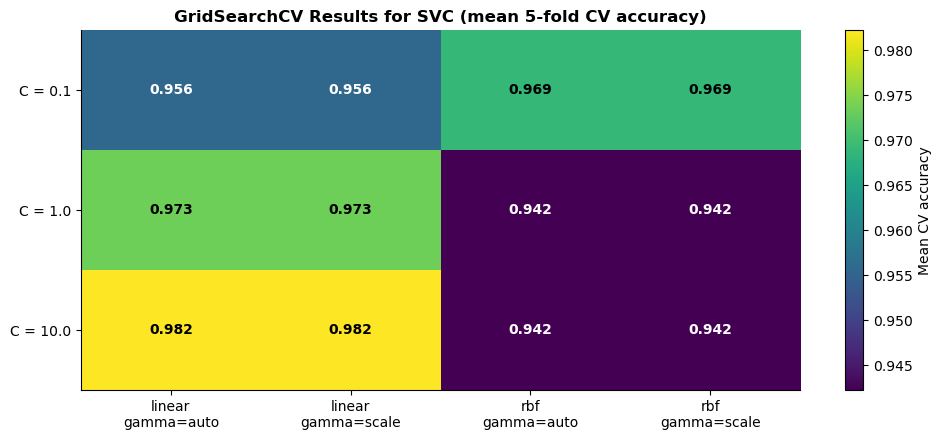

The linear columns are identical for both gamma values, confirming gamma has no effect on a linear kernel.
On standardised data, gamma="scale" and gamma="auto" also give identical rbf results.


In [77]:
res = pd.DataFrame(svc_grid.cv_results_)
res['setting'] = res['param_kernel'].astype(str) + '\ngamma=' + res['param_gamma'].astype(str)
heat = res.pivot(index='param_C', columns='setting', values='mean_test_score')

fig, ax = plt.subplots(figsize=(10, 4.5))
im = ax.imshow(heat.values, cmap='viridis', aspect='auto')
ax.set_xticks(range(heat.shape[1])); ax.set_xticklabels(heat.columns)
ax.set_yticks(range(heat.shape[0])); ax.set_yticklabels([f'C = {c}' for c in heat.index])
ax.grid(False)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        ax.text(j, i, f'{heat.values[i, j]:.3f}', ha='center', va='center', fontweight='bold',
                color='black' if heat.values[i, j] > heat.values.mean() else 'white')
plt.colorbar(im, label='Mean CV accuracy')
ax.set_title('GridSearchCV Results for SVC (mean 5-fold CV accuracy)')
plt.tight_layout()
plt.show()
print('The linear columns are identical for both gamma values, confirming gamma has no effect on a linear kernel.')
print('On standardised data, gamma="scale" and gamma="auto" also give identical rbf results.')

## 9.6 Training the best SVC on the full training data and evaluating on the test set

In [78]:
best_svc = SVC(**svc_grid.best_params_)
best_svc.fit(X_train_s, y_train)
svc_test_acc = accuracy_score(y_test, best_svc.predict(X_test_s))

print('Best SVC configuration:', svc_grid.best_params_)
print(f'Test accuracy of the best SVC: {svc_test_acc:.4f}')
print(f'Same result from best_estimator_ (already refitted by GridSearchCV): '
      f'{accuracy_score(y_test, svc_grid.best_estimator_.predict(X_test_s)):.4f}')

Best SVC configuration: {'C': 10, 'gamma': 'scale', 'kernel': 'linear'}
Test accuracy of the best SVC: 0.9867
Same result from best_estimator_ (already refitted by GridSearchCV): 0.9867


## 9.7 GridSearchCV for Random Forest

`criterion` selects the impurity measure used to choose splits: `gini` or `entropy`, both explained in Section 6.

In [79]:
rf_param_grid = {
    'n_estimators': [50, 100],
    'max_depth': [3, 5, 7],
    'criterion': ['gini', 'entropy'],
}
print(f'Combinations: {np.prod([len(v) for v in rf_param_grid.values()])}')

rf_grid = GridSearchCV(RandomForestClassifier(random_state=42), rf_param_grid, cv=5, scoring='accuracy', n_jobs=-1)
rf_grid.fit(X_train_s, y_train)

print('Best parameters          :', rf_grid.best_params_)
print(f'Best cross-validation score: {rf_grid.best_score_:.4f}')

best_rf = RandomForestClassifier(random_state=42, **rf_grid.best_params_).fit(X_train_s, y_train)
rf_test_acc = accuracy_score(y_test, best_rf.predict(X_test_s))
print(f'Test accuracy of the best Random Forest: {rf_test_acc:.4f}')
print()
print(pd.DataFrame(rf_grid.cv_results_)[['param_n_estimators', 'param_max_depth', 'param_criterion',
                                          'mean_test_score', 'rank_test_score']]
      .sort_values('rank_test_score').round(4).to_string(index=False))

Combinations: 12
Best parameters          : {'criterion': 'gini', 'max_depth': 5, 'n_estimators': 100}
Best cross-validation score: 0.9289
Test accuracy of the best Random Forest: 0.9200

 param_n_estimators  param_max_depth param_criterion  mean_test_score  rank_test_score
                100                5            gini           0.9289                1
                100                7            gini           0.9244                2
                 50                7         entropy           0.9244                2
                100                7         entropy           0.9244                2
                100                3            gini           0.9244                5
                100                5         entropy           0.9200                6
                 50                7            gini           0.9200                6
                 50                5            gini           0.9200                6
                 50          

Best parameters          : {'criterion': 'gini', 'max_depth': 5, 'n_estimators': 100}
Best cross-validation score: 0.9289
Test accuracy of the best Random Forest: 0.9200

 param_n_estimators  param_max_depth param_criterion  mean_test_score  rank_test_score
                100                5            gini           0.9289                1
                100                7            gini           0.9244                2
                 50                7         entropy           0.9244                2
                100                7         entropy           0.9244                2
                100                3            gini           0.9244                5
                100                5         entropy           0.9200                6
                 50                7            gini           0.9200                6
                 50                5            gini           0.9200                6
                 50                5         e

## 9.8 Comparing the tuned models

              Model                                            Best parameters  Best CV accuracy  Test accuracy
          Tuned SVC            {'C': 10, 'gamma': 'scale', 'kernel': 'linear'}            0.9822         0.9867
Tuned Random Forest {'criterion': 'gini', 'max_depth': 5, 'n_estimators': 100}            0.9289         0.9200

Better model on this dataset: Tuned SVC

The target is a linear combination of the features (2*F1 - F2 + 0.5*F3 > 0), so the true boundary is a flat
plane. A linear SVM matches that shape exactly, while a random forest must approximate a diagonal plane
with many axis-aligned splits, which limits its accuracy.


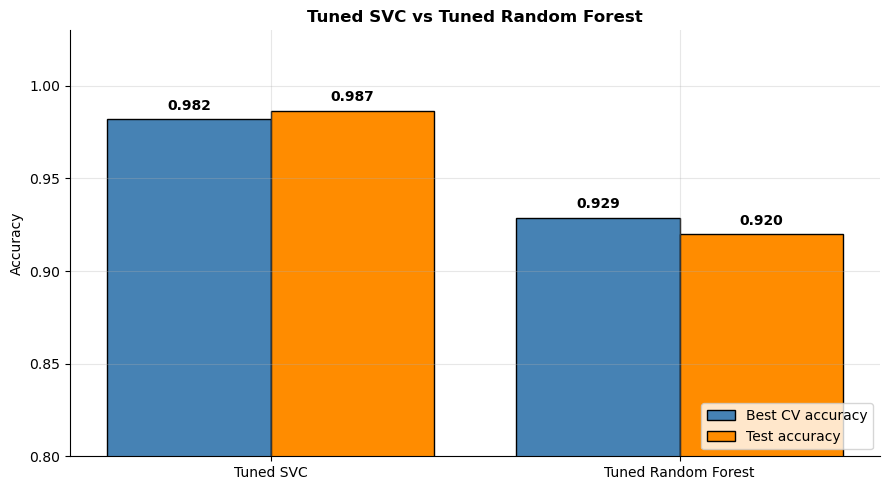

In [80]:
final = pd.DataFrame({
    'Model': ['Tuned SVC', 'Tuned Random Forest'],
    'Best parameters': [str(svc_grid.best_params_), str(rf_grid.best_params_)],
    'Best CV accuracy': [svc_grid.best_score_, rf_grid.best_score_],
    'Test accuracy': [svc_test_acc, rf_test_acc],
})
print(final.round(4).to_string(index=False))
print()
winner = final.loc[final['Test accuracy'].idxmax(), 'Model']
print(f'Better model on this dataset: {winner}')
print()
print('The target is a linear combination of the features (2*F1 - F2 + 0.5*F3 > 0), so the true boundary is a flat')
print('plane. A linear SVM matches that shape exactly, while a random forest must approximate a diagonal plane')
print('with many axis-aligned splits, which limits its accuracy.')

fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(2)
ax.bar(x - 0.2, final['Best CV accuracy'], 0.4, label='Best CV accuracy', color='steelblue', edgecolor='black')
ax.bar(x + 0.2, final['Test accuracy'], 0.4, label='Test accuracy', color='darkorange', edgecolor='black')
for i in range(2):
    ax.text(i - 0.2, final['Best CV accuracy'][i] + 0.005, f'{final["Best CV accuracy"][i]:.3f}', ha='center', fontweight='bold')
    ax.text(i + 0.2, final['Test accuracy'][i] + 0.005, f'{final["Test accuracy"][i]:.3f}', ha='center', fontweight='bold')
ax.set_xticks(x); ax.set_xticklabels(final['Model'])
ax.set_ylim(0.8, 1.03)
ax.set_ylabel('Accuracy')
ax.set_title('Tuned SVC vs Tuned Random Forest')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

## 9.9 Discussion

**What is the difference between a hyperparameter and a model parameter?**
Model parameters, such as regression coefficients or tree split thresholds, are learned automatically from the data during training. Hyperparameters, such as `C`, `kernel` or `max_depth`, are set before training and control how the learning happens, so they must be chosen through experimentation such as grid search.

**Why is cross-validation used inside GridSearchCV instead of a single validation set?**
Comparing many combinations on one validation split risks choosing the combination that simply got lucky on those particular rows, which would overfit the hyperparameters to that split. Averaging each combination's score over several folds gives a more stable and trustworthy ranking and uses all of the training data for both training and validation.

---
# 10. Complete Machine Learning Pipeline

## 10.1 Concept: data leakage

**Data leakage** occurs when information from outside the training data influences the model during training. The resulting evaluation looks better than the model's true performance on new data.

### Worked example
Suppose the median Age of the full dataset is 44, while the median of the training rows alone is 43. If missing ages are filled with 44 before splitting, the training data has been shaped by statistics that include the test rows. The model has indirectly "seen" the test set. Every preprocessing step that learns something from data (imputers, scalers, encoders, PCA) can leak in this way.

The rule is: **every step that learns from data must be fitted on training data only**, and inside cross-validation it must be refitted on each training fold. Doing this manually is tedious and error-prone. Pipelines do it automatically.

## 10.2 The tools

| Tool | Purpose |
|---|---|
| `SimpleImputer` | Fills missing values. `strategy='median'` for numeric columns (robust to outliers), `strategy='most_frequent'` for categorical columns. |
| `ColumnTransformer` | Applies different preprocessing to different columns, then joins the results side by side. |
| `Pipeline` | Chains steps in order. Calling `fit` runs `fit_transform` on each preprocessing step and `fit` on the final model; calling `predict` runs `transform` on each step and `predict` on the model. |

## 10.3 Structure of the pipeline built in this section

```
                          Raw DataFrame (with missing values and text)
                                          |
                    +---------------------+---------------------+
                    |                                           |
      Numeric: Age, Income, Score                 Categorical: Gender, City
                    |                                           |
     SimpleImputer(strategy='median')          SimpleImputer(strategy='most_frequent')
                    |                                           |
             StandardScaler()                     OneHotEncoder(handle_unknown='ignore')
                    |                                           |
                    +---------------------+---------------------+
                                          |
                          ColumnTransformer joins the columns
                                          |
                     RandomForestClassifier  or  LogisticRegression
                                          |
                                     Prediction
```

The whole diagram behaves like a single model object: one `fit`, one `predict`.

In [81]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import classification_report, confusion_matrix
from sklearn import set_config

np.random.seed(42)
n = 400
df_pipe = pd.DataFrame({
    'Age': np.random.randint(18, 70, n),
    'Income': np.random.normal(50000, 15000, n),
    'Gender': np.random.choice(['Male', 'Female'], n),
    'City': np.random.choice(['NY', 'LA', 'Chicago', 'Houston'], n),
    'Score': np.random.normal(75, 15, n)
})
df_pipe.loc[np.random.choice(df_pipe.index, 30), 'Age'] = np.nan
df_pipe.loc[np.random.choice(df_pipe.index, 20), 'Income'] = np.nan
df_pipe['Purchased'] = ((df_pipe['Age'] > 30) & (df_pipe['Income'] > 45000) & (df_pipe['Score'] > 70)).astype(int)

print(df_pipe.head(8))
print()
print('Missing values per column:')
print(df_pipe.isna().sum())
print()
print('Target distribution:', df_pipe['Purchased'].value_counts().to_dict(),
      f'({df_pipe["Purchased"].mean():.1%} purchased)')
print()
print('Note: np.random.choice samples with replacement, so slightly fewer than 30 and 20 distinct rows are affected.')

    Age        Income  Gender     City      Score  Purchased
0  56.0  32784.200408  Female  Houston  70.753365          0
1  69.0  70844.042422  Female       NY  61.769590          0
2  46.0  37171.392217    Male       LA  69.135921          0
3  32.0  34594.073616    Male  Houston  64.943526          0
4  60.0  63242.564908  Female  Chicago  74.303694          1
5  25.0  43260.434209    Male  Houston  70.051279          0
6   NaN  56279.592038    Male  Chicago  69.732890          0
7  56.0  39077.311260    Male  Chicago  91.610826          0

Missing values per column:
Age          28
Income       18
Gender        0
City          0
Score         0
Purchased     0
dtype: int64

Target distribution: {0: 290, 1: 110} (27.5% purchased)

Note: np.random.choice samples with replacement, so slightly fewer than 30 and 20 distinct rows are affected.


## 10.4 Separating features and target, and identifying column types

In [82]:
X = df_pipe.drop(columns='Purchased')
y = df_pipe['Purchased']

numeric_features = X.select_dtypes(include=['number']).columns.tolist()
categorical_features = X.select_dtypes(include=['object', 'category', 'string']).columns.tolist()
print('Numeric columns    :', numeric_features)
print('Categorical columns:', categorical_features)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print()
print(f'Training rows: {len(X_train)}   Test rows: {len(X_test)}')
print('stratify=y keeps the purchase rate equal in both sets:',
      f'train {y_train.mean():.1%}, test {y_test.mean():.1%}')

Numeric columns    : ['Age', 'Income', 'Score']
Categorical columns: ['Gender', 'City']

Training rows: 320   Test rows: 80
stratify=y keeps the purchase rate equal in both sets: train 27.5%, test 27.5%


## 10.5 Building the ColumnTransformer with imputation

Each branch is a small Pipeline, so imputation always happens **before** scaling or encoding. `handle_unknown='ignore'` ensures that a city never seen in training produces all-zero dummy columns instead of an error.

In [83]:
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore')),
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features),
])

# Inspect what the preprocessor produces on its own (fitted on training data only)
X_train_transformed = preprocessor.fit_transform(X_train)
print('Shape before preprocessing:', X_train.shape)
print('Shape after preprocessing :', X_train_transformed.shape)
print('Output feature names      :', list(preprocessor.get_feature_names_out()))
print('Missing values remaining  :', int(np.isnan(X_train_transformed).sum()))
print()
num_imputer = preprocessor.named_transformers_['num'].named_steps['imputer']
print('Medians learned from the TRAINING set:', {f: float(v) for f, v in zip(numeric_features, num_imputer.statistics_.round(2))})
print('Medians of the FULL dataset (unused) :', X[numeric_features].median().round(2).to_dict())

Shape before preprocessing: (320, 5)
Shape after preprocessing : (320, 9)
Output feature names      : ['num__Age', 'num__Income', 'num__Score', 'cat__Gender_Female', 'cat__Gender_Male', 'cat__City_Chicago', 'cat__City_Houston', 'cat__City_LA', 'cat__City_NY']
Missing values remaining  : 0

Medians learned from the TRAINING set: {'Age': 44.5, 'Income': 50356.27, 'Score': 75.61}
Medians of the FULL dataset (unused) : {'Age': 45.0, 'Income': 50674.69, 'Score': 76.32}


## 10.6 Pipeline 1: preprocessing + Random Forest

In [84]:
set_config(display='diagram')   # renders pipelines as an interactive diagram in Jupyter

rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(n_estimators=100, random_state=42)),
])
rf_pipeline.fit(X_train, y_train)     # one call: impute -> scale/encode -> train
rf_pipeline

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Age', 'Income', 'Score']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Gender', 'City'])])),
                ('classifier', RandomForestClassifier(random_state=42))])

## 10.7 Pipeline 2: preprocessing + Logistic Regression, and test accuracy comparison

Random Forest pipeline       - test accuracy: 0.9750
Logistic Regression pipeline - test accuracy: 0.8625
Baseline (always predict 0)  - test accuracy: 0.7250

Random Forest classification report:
               precision    recall  f1-score   support

Not purchased     0.9828    0.9828    0.9828        58
    Purchased     0.9545    0.9545    0.9545        22

     accuracy                         0.9750        80
    macro avg     0.9687    0.9687    0.9687        80
 weighted avg     0.9750    0.9750    0.9750        80

Logistic Regression classification report:
               precision    recall  f1-score   support

Not purchased     0.8983    0.9138    0.9060        58
    Purchased     0.7619    0.7273    0.7442        22

     accuracy                         0.8625        80
    macro avg     0.8301    0.8205    0.8251        80
 weighted avg     0.8608    0.8625    0.8615        80



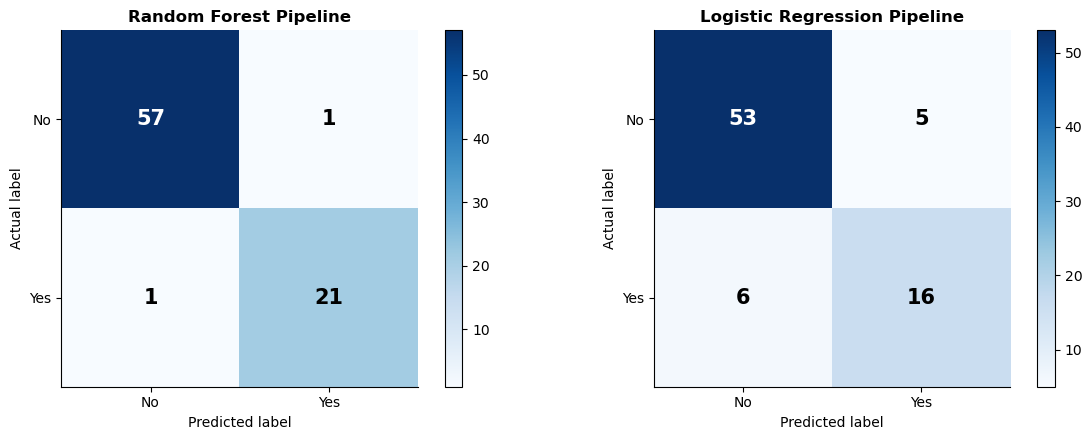

The purchase rule requires three thresholds to be met at once (an AND of conditions). Tree-based models
represent such rectangular regions naturally, while logistic regression can only draw one flat boundary.


In [85]:
lr_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000)),
])
lr_pipeline.fit(X_train, y_train)

rf_test_acc = accuracy_score(y_test, rf_pipeline.predict(X_test))
lr_test_acc = accuracy_score(y_test, lr_pipeline.predict(X_test))
print(f'Random Forest pipeline       - test accuracy: {rf_test_acc:.4f}')
print(f'Logistic Regression pipeline - test accuracy: {lr_test_acc:.4f}')
print(f'Baseline (always predict 0)  - test accuracy: {(y_test == 0).mean():.4f}')
print()
print('Random Forest classification report:')
print(classification_report(y_test, rf_pipeline.predict(X_test), target_names=['Not purchased', 'Purchased'], digits=4))
print('Logistic Regression classification report:')
print(classification_report(y_test, lr_pipeline.predict(X_test), target_names=['Not purchased', 'Purchased'], digits=4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
plot_confusion_matrix(confusion_matrix(y_test, rf_pipeline.predict(X_test)), ['No', 'Yes'], 'Random Forest Pipeline', ax=axes[0])
plot_confusion_matrix(confusion_matrix(y_test, lr_pipeline.predict(X_test)), ['No', 'Yes'], 'Logistic Regression Pipeline', ax=axes[1])
plt.tight_layout()
plt.show()
print('The purchase rule requires three thresholds to be met at once (an AND of conditions). Tree-based models')
print('represent such rectangular regions naturally, while logistic regression can only draw one flat boundary.')

## 10.8 Cross-validation directly on the pipelines

When the **whole pipeline** is passed to `cross_val_score`, the imputer, scaler and encoder are refitted inside each training fold, and each validation fold is transformed using only the statistics from its training folds. This is leakage-free cross-validation, obtained with a single line of code.

Random Forest pipeline fold scores      : [0.9    0.9375 0.9375 0.95   0.9625]
Random Forest pipeline mean CV accuracy : 0.9375 (+/- 0.0209)

Logistic Regression pipeline fold scores: [0.7625 0.825  0.825  0.825  0.9   ]
Logistic Regression mean CV accuracy    : 0.8275 (+/- 0.0436)


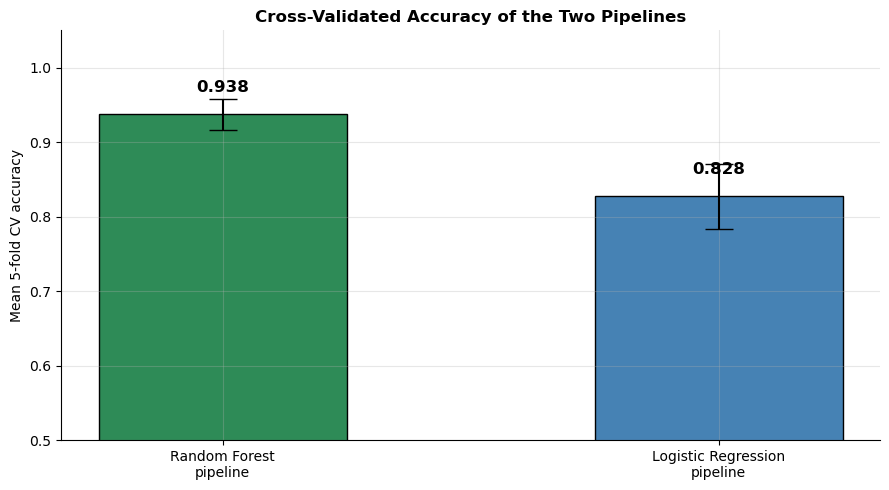

In [86]:
cv_splitter = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rf_cv_scores = cross_val_score(rf_pipeline, X, y, cv=cv_splitter, scoring='accuracy')
lr_cv_scores = cross_val_score(lr_pipeline, X, y, cv=cv_splitter, scoring='accuracy')

print('Random Forest pipeline fold scores      :', rf_cv_scores.round(4))
print(f'Random Forest pipeline mean CV accuracy : {rf_cv_scores.mean():.4f} (+/- {rf_cv_scores.std():.4f})')
print()
print('Logistic Regression pipeline fold scores:', lr_cv_scores.round(4))
print(f'Logistic Regression mean CV accuracy    : {lr_cv_scores.mean():.4f} (+/- {lr_cv_scores.std():.4f})')

fig, ax = plt.subplots(figsize=(9, 5))
names = ['Random Forest\npipeline', 'Logistic Regression\npipeline']
means = [rf_cv_scores.mean(), lr_cv_scores.mean()]
stds = [rf_cv_scores.std(), lr_cv_scores.std()]
bars = ax.bar(names, means, yerr=stds, capsize=10, color=['seagreen', 'steelblue'], edgecolor='black', width=0.5)
for bar, m in zip(bars, means):
    ax.text(bar.get_x() + bar.get_width() / 2, m + 0.03, f'{m:.3f}', ha='center', fontweight='bold', fontsize=12)
ax.set_ylim(0.5, 1.05)
ax.set_ylabel('Mean 5-fold CV accuracy')
ax.set_title('Cross-Validated Accuracy of the Two Pipelines')
plt.tight_layout()
plt.show()

## 10.9 Predicting for a new customer

The new customer is passed as a **raw DataFrame** with text values and original units. The pipeline performs imputation, scaling and encoding internally, exactly as it did during training.

In [87]:
best_pipeline, best_name = (rf_pipeline, 'Random Forest') if rf_cv_scores.mean() >= lr_cv_scores.mean() \
    else (lr_pipeline, 'Logistic Regression')
print(f'Best pipeline by mean CV accuracy: {best_name}')

new_customer = pd.DataFrame({
    'Age': [35],
    'Income': [55000],
    'Gender': ['Female'],
    'City': ['LA'],
    'Score': [80],
})
print()
print('New customer (raw input):')
print(new_customer)

prediction = best_pipeline.predict(new_customer)[0]
probability = best_pipeline.predict_proba(new_customer)[0]
print()
print(f'Predicted outcome: {"Purchased (1)" if prediction == 1 else "Not purchased (0)"}')
print(f'Probability of purchase: {probability[1]:.3f}')
print()
print('Check against the true rule: Age 35 > 30, Income 55,000 > 45,000 and Score 80 > 70, so a purchase is expected.')
print()
print('What the model actually received after preprocessing:')
print(pd.DataFrame(best_pipeline.named_steps['preprocessor'].transform(new_customer),
                   columns=best_pipeline.named_steps['preprocessor'].get_feature_names_out()).round(3))

Best pipeline by mean CV accuracy: Random Forest

New customer (raw input):
   Age  Income  Gender City  Score
0   35   55000  Female   LA     80

Predicted outcome: Purchased (1)
Probability of purchase: 0.650

Check against the true rule: Age 35 > 30, Income 55,000 > 45,000 and Score 80 > 70, so a purchase is expected.

What the model actually received after preprocessing:
   num__Age  num__Income  num__Score  cat__Gender_Female  cat__Gender_Male  cat__City_Chicago  cat__City_Houston  cat__City_LA  \
0    -0.613        0.363       0.223                 1.0               0.0                0.0                0.0           1.0   

   cat__City_NY  
0           0.0  


## 10.10 Discussion

**Why is using a Pipeline better than manually preprocessing data before modelling?**
A Pipeline guarantees that exactly the same sequence of transformations, with the same learned values, is applied during training, evaluation and prediction, so steps cannot be forgotten, applied in the wrong order or fitted on the wrong data. It also packages preprocessing and model as a single object that can be cross-validated, tuned with GridSearchCV and saved for deployment.

**What errors occur if preprocessing is fit on the entire dataset instead of just the training set?**
The imputation medians, scaling statistics and encoder categories would include information from the test rows, so the model is indirectly exposed to the test set, a form of data leakage. The resulting accuracy is over-optimistic, and the model may perform noticeably worse on genuinely new data than the evaluation suggested.

---
# 11. Summary and Reference

## 11.1 Algorithms covered

| Algorithm | Task | Core idea | Needs scaling? | Key hyperparameters | Main strength | Main weakness |
|---|---|---|---|---|---|---|
| Linear Regression | Regression | Weighted sum of features fitted by least squares | Not for accuracy; helps compare coefficients | None (basic form) | Simple, fast, interpretable coefficients | Only captures linear relationships |
| Logistic Regression | Classification | Linear score passed through a sigmoid to give a probability | Yes | `C`, `max_iter` | Probabilities, interpretable, fast | Linear decision boundary only |
| K-Means | Clustering | Assign to nearest centroid, move centroids to cluster means, repeat | Yes | `n_clusters`, `n_init` | Simple, scalable | K must be chosen; assumes round, similar-size clusters |
| PCA | Dimensionality reduction | Project onto directions of maximum variance | Yes | `n_components` | Compression, visualisation, removes redundancy | Components are hard to interpret; linear only |
| Decision Tree | Classification / Regression | Sequence of threshold questions chosen to maximise purity | No | `max_depth`, `criterion`, `min_samples_split` | Highly interpretable, handles non-linear rules | Overfits easily, unstable |
| Random Forest | Classification / Regression | Many randomised trees, predictions combined by vote or average | No | `n_estimators`, `max_depth`, `max_features` | Accurate, robust, feature importances | Less interpretable, slower |
| SVC | Classification | Maximum-margin boundary; kernels allow curved boundaries | Yes | `C`, `kernel`, `gamma` | Strong on small to medium data, flexible via kernels | Slow on large datasets, sensitive to hyperparameters |

## 11.2 Evaluation metrics

| Metric | Task | Formula | Best value |
|---|---|---|---|
| MSE | Regression | $\frac{1}{n}\sum (y - \hat{y})^2$ | 0 |
| RMSE | Regression | $\sqrt{\text{MSE}}$ | 0 |
| R² | Regression | $1 - \frac{\sum (y-\hat{y})^2}{\sum (y-\bar{y})^2}$ | 1 |
| Accuracy | Classification | $\frac{TP + TN}{\text{total}}$ | 1 |
| Precision | Classification | $\frac{TP}{TP + FP}$ | 1 |
| Recall | Classification | $\frac{TP}{TP + FN}$ | 1 |
| F1-score | Classification | $2 \cdot \frac{P \cdot R}{P + R}$ | 1 |
| Inertia | Clustering | $\sum \lVert x - \mu_c \rVert^2$ | Lower is tighter (not comparable across K) |
| Silhouette | Clustering | $\frac{b - a}{\max(a, b)}$ | 1 |
| Explained variance ratio | PCA | $\lambda_j / \sum \lambda$ | Higher means more information kept |

## 11.3 Preprocessing choices

| Situation | Tool |
|---|---|
| Numeric features, general use | `StandardScaler` |
| Numeric features that must lie in a fixed range | `MinMaxScaler` |
| Binary category, or encoding the target `y` | `LabelEncoder` |
| Unordered category with more than two values | `OneHotEncoder` |
| Ordered category | Manual mapping with `map()` or `OrdinalEncoder` |
| Missing numeric values | `SimpleImputer(strategy='median')` |
| Missing categorical values | `SimpleImputer(strategy='most_frequent')` |
| Different treatment for different columns | `ColumnTransformer` |
| Chaining preprocessing and model safely | `Pipeline` |

## 11.4 Common mistakes and how to avoid them

| Mistake | Consequence | Correct practice |
|---|---|---|
| Fitting a scaler or imputer on the full dataset | Data leakage, optimistic scores | Fit on training data only, or use a Pipeline |
| Calling `fit_transform` on the test set | Test data scaled with its own statistics | Use `transform` on test data |
| Evaluating on training data | Overfitting goes undetected | Use a held-out test set or cross-validation |
| Reporting accuracy on imbalanced data without a baseline | A useless model appears good | Compare with the majority-class baseline; report precision, recall and F1 |
| Label-encoding unordered categories for linear models | False ordering between categories | Use one-hot encoding |
| Forgetting to scale for K-Means, PCA, SVC or logistic regression | Large-range features dominate | Scale first |
| Tuning hyperparameters using the test set | Test score no longer unbiased | Tune with cross-validation on training data; test once at the end |
| Including features derived from the target | Target leakage | Remove any column computed from the target |